<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_MASTER_PIPELINE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS 2.0 — Master pipeline

**One notebook for the whole workflow:** environment → data acquisition → native grid → DEM inventory → geological EDA repair → segment attributes → spatial splits → feature store → baselines → research experiments → discovery evaluation → ensembling → full inference → submission → reports.

Every stage **checks Drive first, reuses valid outputs, builds only what is missing, saves to Google Drive immediately and records provenance**. Re-running any cell after a disconnect resumes where it stopped.

### First time here? Run in three steps

1. **`PREPARE_DATA`** (recommended first run, CPU is enough): reuses the raw files and the saved spatial splits on Drive, rebuilds missing Phase‑1 EDA dependencies, creates the segment attributes and the baseline features, saves everything to Drive and **stops before any model training**.
2. **`BASELINES`** with `train_baselines=['G1']` (CPU): trains / verifies the G1 LightGBM, geographic CV + pseudo-discovery, OOF maps on Drive.
3. **`ADVANCED_RESEARCH`** (GPU runtime): research experiments.

Cells appear in dependency order (`pipe.graph()` is the source of truth):

```
bootstrap → raw_data → native_grid ─┬─ dem_inventory ─────────────────────────────→ dem_pilot (needs feature_store)
                                    ├─ geological_eda → segment_attributes ┄┄┐
                                    ├─ spatial_folds ────────────────────────┼─→ feature_store ─┬─→ dem_pilot
                                    └─ discovery_splits ─────────────────────┘                  │
   spatial_folds + discovery_splits (┄ feature_store, ┄ segment_attributes) ─→ baselines ─→ discovery_validation ─→ ensemble
   feature_store + baselines ─→ advanced_models (GPU)        feature_store ─→ full_inference (GPU) ─→ submission
   reports (always last)                                      ┄ = soft dependency: ordered first, never blocking
```

| decision | meaning |
|---|---|
| `SKIP_CACHED` | outputs exist, pass content checks, and were made under this configuration (or are pre-existing artifacts, adopted with provenance) |
| `BUILD` / `RESUME` | outputs missing / partial: built, or resumed from completed units and checkpoints |
| `INCOMPATIBLE` | outputs exist but differ from the configuration: **never overwritten**; changed protocols get a new versioned folder |
| `BLOCKED` | a prerequisite is missing: the message names the **root failure** and the recovery action |
| `DISABLED` | switched off in `CONFIG`, or a GPU stage on a CPU runtime |

**Failures:** with `failure_policy='interactive'` (default here) a failed critical stage prints the full traceback, the file and line, and the recovery action, then **stops “Run all”**. Completed artifacts are kept. `pipe.explain('<stage>')` shows it again later, also from an earlier session. With `'batch'`, independent stages continue and one grouped report lists each root failure with the stages it blocks.

**Safety:** GPU training, DEM tile downloads, full inference and submission export are off until enabled below. Nothing is ever deleted on Drive, nothing is uploaded to the competition, no URL or token is written to disk or to the Git remote. Pseudo-discovery scores are local-protocol numbers, never leaderboard scores.

Guide: `docs/MASTER_COLAB_GUIDE.md` · dependencies: `docs/PIPELINE_DEPENDENCIES.md` · recovery: `docs/ARTIFACT_RECOVERY.md`.

## 1. Configuration (control panel)

Edit, then run the cells top to bottom (or use the one-shot run in section 6). Keys are validated: a typo raises an error naming the closest valid key.

**Modes:** `SETUP_ONLY` (verify environment and existing data, no downloads) · **`PREPARE_DATA`** (recommended first run: data, EDA repair, segments, splits, features; no training) · `BASELINES` (+ restore / train the baselines listed in `train_baselines`, scoreboard) · `ADVANCED_RESEARCH` (+ GPU research experiments) · `FULL_PIPELINE` (every enabled stage) · `RESUME` (continue from saved state) · `SUBMISSION_ONLY` (promoted model → GeoTIFF; prerequisites validated, not rebuilt).

`ref` is either a **branch** (follows `origin/<branch>`, fast-forward only) or a **commit SHA / tag** (pinned, detached). The code cell prints which one was checked out.

**Execution mode vs experiment fidelity.** `run_mode` decides *which stages* run. `experiment_profile` (`SCREEN` / `VALIDATE` / `FULL`) decides *how much evidence* each GPU research run produces. They are independent keys: neither changes the meaning of the other. See `docs/EXPERIMENT_FIDELITY_AND_COST.md`.

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',                                   # branch name, or a commit SHA / tag to pin the code
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'run_mode': 'ADVANCED_RESEARCH',                 # WHICH STAGES run: PREPARE_DATA -> BASELINES -> ADVANCED_RESEARCH
    'failure_policy': 'interactive',                 # 'interactive': stop on a critical failure | 'batch': continue
    'download_missing': True,                        # only files absent / invalid on Drive AND locally
    'rebuild_missing': True,

    'run_eda': True,                                 # minimal Phase-1 rebuild if outputs/eda is missing (CPU)
    'run_baselines': True,                           # scan / verify baselines (cheap)
    'train_baselines': [],                           # BASELINES step: ['G1'] (CPU); later 'G3', 'B0_lineament'; GPU: 'CNN_A_dti', ...
    'run_advanced_features': True,                   # Phase-4 RS features used by the baselines
    'run_advanced_models': True,                    # GPU research experiments (opt-in)
    # HOW MUCH EVIDENCE each research run produces (independent of run_mode):
    #   'SCREEN'   1 fold, no discovery, <= 5 epochs x 80 steps, proxy metrics on 25 % of the held-out fold (~5 GPU min)
    #   'VALIDATE' 3 folds + discovery split 0, <= 10 epochs x 150 steps, proxy metrics (~30 GPU min)
    #   'FULL'     committed YAMLs unchanged, section-17 evaluation, the only promotion-eligible level (~60 GPU min)
    # Completed FULL runs are reused, never retrained for a cheaper profile; B0 is added as the matched control.
    'experiment_profile': 'SCREEN',
    'advanced_experiments': ['b0_reference', 'b1_bg_weight', 'b2_nnpu_p010', 'c1_geometry_heads'],
    # 'e1_gsn_parity' is a parity check (expected identical to B0), not a candidate: add it only to confirm parity
    'fidelity_overrides': {},                        # e.g. {'SCREEN': {'max_epochs': 4, 'validation_fraction': 0.5}}
    'auto_provision_maps': True,                     # build B0_lineament (label-free, CPU) when B1 needs it
    'checkpoint': {'policy': 'best_and_latest', 'save_every_epochs': 5, 'sync_every_minutes': 15},
    'feature_stage': 'lazy',                         # copy feature caches from Drive on first read ('all' = up front)
    'run_dem_pilot': False,
    'run_scoreboard': True,
    'run_ensemble': True,
    'run_full_inference': False,                     # needs a PROMOTED model (manual decision)
    'run_submission': False,                         # writes GeoTIFFs; never uploads

    'use_gpu': True,                                 # GPU stages are DISABLED automatically when no CUDA GPU is attached
    'max_stage_minutes': 0,                          # e.g. 200 on free tier: clean, resumable stop
    'save_figures': True,
    'save_intermediate': True,
    'seed': 2026,
}

DEM_CONFIG = {
    'enabled': False,
    'mode': 'pilot',                                 # 'pilot' | 'inventory_only' (never the full collection)
    'download': False,                               # explicit approval, after reading the storage estimate
    'pilot_tiles': 24,                               # spatially balanced pilot (f1_dem_pilot.yaml)
    'max_tiles': 30,
    'max_gib': 15.0,
    'download_only_intersecting': True,
    'compute_morphology': True,                      # 1 m morphology before aggregation
    'aggregate_to_100m': True,
}
PRIVATE_REPO = False                                 # True only for a private fork: uses Colab Secret GITHUB_TOKEN per command

## 2–4. Google Drive, GitHub installation, package import

Idempotent: mounts Drive, clones (or updates) the repository at `CONFIG['ref']`, installs `gems-fault-discovery` in editable mode.

* The repository is public, so the clone is **token-free**. Older notebook versions put a token into the remote URL. This cell resets the remote to the plain URL.
* For a private fork set `PRIVATE_REPO = True`. The token from Colab *Secrets* (`GITHUB_TOKEN`) is passed to `git` through environment variables for that one command. It is never part of the URL, `.git/config`, the command line or any output.
* Git failures are **not** ignored. If a branch has diverged or the checkout has local edits, the cell stops with git's message.
* If the code changed after `gems_bench` was already imported in this kernel, the cell asks you to restart the session, so stale code is never used.
* PyTorch is **not** reinstalled (Colab's CUDA build is the right one).

In [2]:
import base64, os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = f"https://github.com/{CONFIG['repo']}.git"        # token-free remote (public repository)

def _git_env():
    """Private fork only: HTTP auth header via GIT_CONFIG_* env vars (git >= 2.31), never in URL / argv / config."""
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    tok = userdata.get('GITHUB_TOKEN') or ''
    if not tok:
        raise RuntimeError('PRIVATE_REPO=True but the Colab Secret GITHUB_TOKEN is empty / not shared with this notebook')
    hdr = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {hdr}'}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode != 0:                              # never silently ignored
        raise RuntimeError(f"git {' '.join(args[:3])} failed (exit {r.returncode}):\n{r.stderr.strip()[-1500:]}")
    return r

if not os.path.exists(f'{CODE}/.git'):
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'remote', 'set-url', 'origin', REPO_URL)        # drops a token embedded by older notebook versions
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
dirty = git('-C', CODE, 'status', '--porcelain', '--untracked-files=no').stdout.strip()
if dirty:
    print('WARNING: local edits in the checkout (they are kept; a checkout conflict will stop this cell):\n' + dirty)
ref = CONFIG['ref']
before = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if git('-C', CODE, 'rev-parse', '--verify', '-q', f'refs/remotes/origin/{ref}', check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', ref)
    git('-C', CODE, 'merge', '-q', '--ff-only', f'origin/{ref}')   # fails loudly if the branch diverged
    CODE_REF = f'branch {ref} (fast-forwarded to origin/{ref})'
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)             # commit SHA or tag: pinned
    CODE_REF = f'pinned {ref} (detached)'
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)                          # editable install is not visible to a running kernel
os.environ['GEMS_CODE_COMMIT'] = HEAD
print(f'code: {CODE_REF} @ {HEAD}')
if 'gems_bench' in sys.modules and HEAD != before:
    raise RuntimeError('The code changed while gems_bench was already imported in this kernel. '
                       'Runtime -> Restart session, then run the notebook again from section 1 (Drive stays mounted).')

Mounted at /content/drive
code: branch main (fast-forwarded to origin/main) @ c3cea7664c944ac35eb6381fa2b8f523edee4df3


### Fresh download URLs (only when a raw file is missing on Drive)

DrivenData links are personal and **expire**. Preferred: Colab *Secrets* (key icon, enable notebook access) named `GEMS_URL_FEATURES`, `GEMS_URL_FAULTS`, `GEMS_URL_SUBMISSION` (and optionally `GEMS_URL_DEM_JSON`). Alternative: set `ASK_FOR_URLS = True` to paste them here (hidden input). URLs live only in memory; the acquisition manifest stores only the host and a hash. Files already valid on Drive are never downloaded again.

In [3]:
URLS = {}
ASK_FOR_URLS = False
if ASK_FOR_URLS:
    from getpass import getpass
    for key in ('features', 'faults', 'submission', 'dem_json'):
        u = getpass(f'URL for {key} (Enter to skip): ').strip()
        if u:
            URLS[key] = u

from IPython.display import display
from gems_bench.pipeline import Pipeline
pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG, urls=URLS)
display(pipe.cfg.table())

,key,value
0,version,1
1,repo,"""mybenkhadda/GEMS---drivendata"""
2,ref,"""main"""
3,seed,2026
4,run_mode,"""ADVANCED_RESEARCH"""
...,...,...
65,gpu.max_stage_minutes,0
66,gpu.overrides,{}
67,sync.push_after_stage,true
68,reports.save_figures,true


## 5. Environment and GPU verification

`torch.cuda.is_available()` is what counts. A CPU-only PyTorch build, or a CPU runtime, is not GPU support. Without CUDA:

* **CPU work stays available**: raw data, EDA repair, segments, splits, feature store, LightGBM baselines (G1, G3, RS05, B0).
* **GPU stages are DISABLED** (`advanced_models`, `full_inference`), and requested GPU baselines (`CNN_*`, `P4_B_gated`) are reported as *not attempted on this runtime*. Nothing is faked, and no model is allocated.
* To train on a GPU, use *Runtime → Change runtime type → GPU (T4 / L4 / A100)*, reconnect, and run again from section 1. Do **not** reinstall torch: Colab's preinstalled build is CUDA-enabled once a GPU is attached.

When a GPU is present, batch size, precision (bf16 only on compute capability ≥ 8) and inference batch adapt to it. The effective batch, patch size and epochs never change.

In [4]:
pipe.step('bootstrap')
from gems_bench.training import gpu
g = pipe.pc.gpu()
cuda_ok, cuda_why = pipe.pc.cuda_ready()
print({k: g.get(k) for k in ('cuda', 'name', 'vram_gb', 'capability', 'torch', 'torch_cuda')})
if cuda_ok:
    print('autoconfig (256 px, effective batch 16, 29 channels):',
          gpu.autoconfig(g, patch_px=256, effective_batch=16, n_channels=29))
else:
    print(f'CPU runtime: {cuda_why}')
    print('CPU preprocessing and LightGBM baselines run normally; GPU stages are DISABLED (not failed).')
display(__import__('pandas').read_csv('/content/gems_work/reports/pipeline/environment_report.csv'))

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
{'cuda': True, 'name': 'Tesla T4', 'vram_gb': 14.6, 'capability': '7.5', 'torch': '2.11.0+cu130', 'torch_cuda': '13.0'}
autoconfig (256 px, effective batch 16, 29 channels): {'amp': True, 'amp_dtype': 'fp16', 'batch_size': 16, 'grad_accum': 1, 'infer_batch': 16, 'data_on_gpu': True, 'channels_last': True, 'cudnn_benchmark': True}


,key,value
0,package,gems-fault-discovery
1,version,0.5.0
2,git_commit,c3cea7664c944ac35eb6381fa2b8f523edee4df3
3,python,3.13.16
4,cuda_available,True
5,gpu,Tesla T4
6,vram_gb,14.6
7,capability,7.5
8,torch,2.11.0+cu130
9,cuda,13.0


## 6. First-run overview: storage, raw data, GPU and execution plan

Read-only. `pipe.overview()` prints the configuration, the checked-out commit, Drive, GPU, raw-data status and the planned action per stage, validated against what is **on Drive**. Nothing is built here. Expected on the current Drive in `PREPARE_DATA`: `raw_data`, `native_grid`, `spatial_folds` and `discovery_splits` are `SKIP_CACHED` (no download, no regeneration of folds), while `geological_eda`, `segment_attributes` and `feature_store` are `BUILD` / `RESUME`.

**One-shot alternative:** `pipe.run()` executes the whole configured mode in dependency order. The cells below run the same stages one section at a time, with displays.

In [5]:
plan = pipe.overview()
display(plan)
display(pipe.graph())
from gems_bench.pipeline.status import storage
display(storage(pipe.pc))

RUN_EVERYTHING_NOW = False                           # True = run the configured mode in one call
if RUN_EVERYTHING_NOW:
    display(pipe.run())

mode           : ADVANCED_RESEARCH   failure_policy: interactive
code           : ref 'main' -> commit c3cea7664c944ac35eb6381fa2b8f523edee4df3 (package 0.5.0)
Drive          : /content/drive/MyDrive/GEMS_2
GPU            : Tesla T4 (14.6 GB, cc 7.5); torch 2.11.0+cu130 (CUDA build 13.0)
raw data       : raw_data: ok (3 checks)
planned actions: bootstrap=SKIP_CACHED, raw_data=SKIP_CACHED, native_grid=SKIP_CACHED, geological_eda=SKIP_CACHED, segment_attributes=SKIP_CACHED, spatial_folds=SKIP_CACHED, discovery_splits=SKIP_CACHED, feature_store=SKIP_CACHED, baselines=SKIP_CACHED, advanced_models=SKIP_CACHED, discovery_validation=SKIP_CACHED, reports=SKIP_CACHED


,stage,title,outputs,planned,last_status,last_origin,last_finished,resource,est_minutes,detail
0,bootstrap,"Environment, Drive, workspace folders",ok,SKIP_CACHED,done,built,2026-10-26T00:17:49,light,<1,bootstrap: ok (3 checks)
1,raw_data,"Competition files: locate, validate, download ...",ok,SKIP_CACHED,done,built,2026-10-25T22:53:49,network,1-10,raw_data: ok (3 checks)
2,native_grid,"Native 100 m grid, labels, template checks",ok,SKIP_CACHED,done,built,2026-10-22T13:40:01,cpu,1-2,native_grid: ok (1 checks)
3,geological_eda,Phase-1 EDA dependency repair (minimal rebuild),ok,SKIP_CACHED,done,built,2026-10-22T20:50:36,cpu-heavy,15-45,eda_minimal: ok (7 checks)
4,segment_attributes,Native-grid segment ids + attributes,ok,SKIP_CACHED,done,built,2026-10-22T20:50:38,cpu,2-5,native_segments: ok (2 checks)
5,spatial_folds,Geographic folds (Phase-2 protocol),ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:02,cpu,1-3,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
6,discovery_splits,Pseudo-discovery fault-system splits,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:03,cpu,1-3,discovery:discovery_d3_link1km_s2026: ok (3 ch...
7,feature_store,"Feature store: compute once, reuse",ok,SKIP_CACHED,done,built,2026-10-22T21:18:58,cpu-heavy,10-90,feature_store: ok (139 checks)
8,baselines,"Baselines: restore, verify, retrain on request",ok,SKIP_CACHED,done,built,2026-10-25T23:21:53,cpu,scan <1; CPU baselines 20-60 each; CNNs 30-60 ...,baselines: ok (1 checks)
9,advanced_models,PU / geometry / GeoStructureNet / multiscale e...,ok,SKIP_CACHED,done,built,2026-10-25T23:29:45,gpu,"per experiment (estimates): SCREEN ~5, VALIDAT...",advanced_models: ok (4 checks)


,stage,title,deps,soft_deps,resource,requirement,reuse,versioned,critical,est
0,bootstrap,"Environment, Drive, workspace folders",,,light,regenerable,always_run,False,True,<1
1,raw_data,"Competition files: locate, validate, download ...",bootstrap,,network,raw_required,reuse_valid,False,True,1-10
2,native_grid,"Native 100 m grid, labels, template checks",raw_data,,cpu,regenerable,reuse_valid,False,True,1-2
3,dem_inventory,USGS 1 m DEM inventory (metadata only),native_grid,,light,optional,reuse_valid,False,False,1
4,geological_eda,Phase-1 EDA dependency repair (minimal rebuild),native_grid,,cpu-heavy,regenerable,reuse_valid,False,True,15-45
5,segment_attributes,Native-grid segment ids + attributes,geological_eda,,cpu,regenerable,reuse_valid,False,True,2-5
6,spatial_folds,Geographic folds (Phase-2 protocol),native_grid,,cpu,regenerable,reuse_valid,True,True,1-3
7,discovery_splits,Pseudo-discovery fault-system splits,native_grid,,cpu,regenerable,reuse_valid,True,True,1-3
8,feature_store,"Feature store: compute once, reuse","spatial_folds, discovery_splits","geological_eda, segment_attributes",cpu-heavy,regenerable,delegated,False,True,10-90
9,dem_pilot,"1 m DEM pilot: selection, download, morphology...","dem_inventory, feature_store",,network-heavy,optional,delegated,False,False,30-180


,root,path,free_gb,total_gb
0,local,/content/gems_work,192.8,235.7
1,drive,/content/drive/MyDrive/GEMS_2,183.2,235.7


## 7. Raw data inventory and one-time download

Per file: Drive (canonical path, then accepted alternates such as `data/raw/example_submission.tif`) → local disk → resumable download (`.partial`, HTTP Range, retries) → GeoTIFF / JSON validation → verified atomic copy to Drive → manifest. Downloads happen only for files that are missing or invalid in both places.

In [6]:
from gems_bench.data.acquisition import inventory
display(inventory({'drive': pipe.pc.drive, 'local': pipe.pc.local}))
pipe.step('raw_data')

,key,root,rel,canonical,status,reason,bytes,required
0,features,drive,data/raw/geodawn/gems-geodawn-numerical-featur...,True,ok,,418912844,True
1,faults,drive,data/raw/faults/existing_faults.tif,True,ok,,425830,True
2,submission,drive,data/raw/example_submission.tif,False,ok,,1599597,True
3,dem_json,drive,data/raw/dem_1m/tnm_urls.json,True,ok,,145842,False
4,dem_json,drive,data/raw/tnm_items.json,False,ok,,145842,False


[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/raw_data.json']
[raw_data] DONE: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']


StageResult(stage='raw_data', decision='BUILD', outcome='DONE', validation='ok', reason='raw_data: ok (3 checks)', recovery='', seconds=5.951419851000026, summary={'files': {'features': 'staged_from_drive', 'faults': 'staged_from_drive', 'submission': 'staged_from_drive', 'dem_json': 'staged_from_drive'}, 'dem_json': '/content/gems_work/data/raw/dem_1m/tnm_urls.json'}, outputs=['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv'], location='', traceback='', root_causes=[])

## 8. Native geospatial data verification

100 m GeoDAWN grid (EPSG:32611), mapped-fault labels (value ≥ 1), valid footprint, submission template on the same grid. Recorded in `environment/pipeline/native_grid.json` with raw-file fingerprints, so a new data release is detected instead of silently mixed. Every later stage (DEM inventory, EDA, splits, features) depends on this one.

In [7]:
pipe.step('native_grid')
display(pipe.pc.data.summary())

[sync in] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_grid: ok (1 checks)
[native_grid] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/native_grid.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/native_band_table.csv']


,key,value
0,crs,EPSG:32611
1,height,3730
2,width,3292
3,pixel_m_x,100.0
4,pixel_m_y,100.0
5,n_bands,19
6,valid_frac,0.42070076454741206
7,valid_km2,51658.520000000004
8,label_px,60988
9,label_frac_of_valid,0.011787794152832872


## 9. USGS 1 m DEM inventory (metadata only) and optional pilot

Runs after the native grid (it needs the study-area footprint). The inventory parses the URL JSON and identifies source projects, duplicate URLs, overlapping projects per tile, study-area intersection and the storage estimate. It also writes a footprint GeoPackage and a figure. `data/raw/tnm_items.json` is accepted and copied to `data/raw/dem_1m/tnm_urls.json`. **No tile is downloaded here.** The pilot (after the feature store, section 12) selects a spatially balanced subset and downloads it only with `DEM_CONFIG['download'] = True`. The DEM is optional: nothing else waits for it.

In [8]:
pipe.step('dem_inventory')
import json, pathlib
est = pathlib.Path('/content/gems_work/data/raw/dem_1m/inventory/dem_storage_estimate.json')
if est.exists():
    print(json.dumps(json.loads(est.read_text()), indent=1))

[sync in] 6 copied (0.8 MiB), 0 unchanged, 2s: ['data/raw/dem_1m/inventory']
[dem_inventory] not part of mode ADVANCED_RESEARCH: outputs ok - dem_inventory: ok (2 checks)
{
 "n_tiles": 580,
 "n_unique_tiles": 536,
 "bytes_known": 0.0,
 "gib_estimate": 189.05848264694214,
 "n_without_size": 580,
 "n_urls": 894,
 "n_duplicate_urls": 0,
 "n_unparsed": 53,
 "n_selected_one_per_tile": 536,
 "pilot_tiles": 24,
 "n_tiles_with_overlapping_projects": 75
}


## 10. Phase 1 EDA dependency repair, then native segment attributes

Only the EDA artifacts later phases actually read are regenerated: fault segments + archetypes, fused lineament maps and cross-modal orientation. They are built with the same `gems_eda` functions and defaults as notebook 01 (2048 px working grid, seed 7), in `outputs/eda_rebuild/<version>/`. This takes about 15–45 min of CPU, once.

* Each artifact group is installed into `outputs/eda/` **only if the whole group is absent**. Historical files are never mixed or overwritten. Installed files are listed in `manifest.json` with `origin: rebuilt`.
* **Resume:** a finished rebuild folder (`REBUILD_COMPLETE.json`) is reused instead of recomputed. An install interrupted half-way (`outputs/eda/INSTALL_STATE.json` = `in_progress`) is completed from the same rebuild folder.
* `segment_attributes` then writes `outputs/benchmark/datasets/native_segment_ids.tif` (native 100 m grid, `seg_id` band) and `segment_attributes.parquet`. `native_segments_provenance.json` records the sha256 of the source segment set, so new segment ids are never paired with an old raster.

If this cell fails, the message shows the file:line and the recovery. `pipe.explain('geological_eda')` repeats it.

In [9]:
pipe.step('geological_eda')
pipe.step('segment_attributes')
import pandas as pd
p = pathlib.Path('/content/gems_work/outputs/eda/manifest.json')
if p.exists():
    display(pd.DataFrame(json.loads(p.read_text())).T)
for f in ('outputs/eda/INSTALL_STATE.json', 'outputs/benchmark/datasets/native_segments_provenance.json'):
    q = pipe.pc.local / f
    if q.exists():
        print(f, '->', json.loads(q.read_text()))

[sync in] 9 copied (69.8 MiB), 0 unchanged, 3s: ['outputs/eda/manifest.json', 'outputs/eda/datasets', 'outputs/eda/features/lineament_maps.tif', 'outputs/eda/features/crossmodal_orientation.tif', 'outputs/eda/REBUILD_PROVENANCE.json', 'outputs/eda/INSTALL_STATE.json']
[geological_eda] SKIP_CACHED: eda_minimal: ok (7 checks)
[geological_eda] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/eda/manifest.json', '/content/drive/MyDrive/GEMS_2/outputs/eda/datasets', '/content/drive/MyDrive/GEMS_2/outputs/eda/features/lineament_maps.tif', '/content/drive/MyDrive/GEMS_2/outputs/eda/features/crossmodal_orientation.tif', '/content/drive/MyDrive/GEMS_2/outputs/eda/REBUILD_PROVENANCE.json', '/content/drive/MyDrive/GEMS_2/outputs/eda/INSTALL_STATE.json']
[sync in] 3 copied (0.6 MiB), 0 unchanged, 0s: ['outputs/benchmark/datasets/native_segment_ids.tif', 'outputs/benchmark/datasets/segment_attributes.parquet', 'outputs/benchmark/datasets/native_segments_provenance.json']
[segment_attributes] SKIP_C

,path,kind,description,origin,rebuild_version
known_fault_segments,outputs/eda/datasets/known_fault_segments.parquet,dataset,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
known_fault_segments_gpkg,outputs/eda/datasets/known_fault_segments.gpkg,vector,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
known_fault_nodes,outputs/eda/datasets/known_fault_nodes.parquet,dataset,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
segment_archetypes,outputs/eda/datasets/segment_archetypes.parquet,dataset,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
lineament_maps,outputs/eda/features/lineament_maps.tif,raster,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
crossmodal_orientation,outputs/eda/features/crossmodal_orientation.tif,raster,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635


outputs/eda/INSTALL_STATE.json -> {'status': 'complete', 'version': 'v20261022_204635', 'groups': ['segments', 'lineaments', 'crossmodal'], 'files': ['datasets/known_fault_segments.parquet', 'datasets/known_fault_segments.gpkg', 'datasets/known_fault_nodes.parquet', 'datasets/segment_archetypes.parquet', 'features/lineament_maps.tif', 'features/crossmodal_orientation.tif'], 'finished': '2026-10-22T20:50:33'}
outputs/benchmark/datasets/native_segments_provenance.json -> {'eda_segments': {'datasets/known_fault_segments.parquet': '185bacb5587bc3fbc2ceffe4340c7142597cbc44bea410e2705c0ec898c3ee04', 'datasets/known_fault_segments.gpkg': '16677c43b430d1b215458a6dfec65f7d3ce87bd0fef0497b5773ede742f69b2a', 'datasets/segment_archetypes.parquet': 'dd049378753b64ce5ceb243ae5b1f7b20b090729c7835a5da08b58dd68d54604'}, 'n_segments': 2318, 'label_px': 60988, 'label_px_assigned_frac': 0.9212, 'max_dist_m': 300.0, 'crs': 'EPSG:32611', 'shape': [3730, 3292], 'created': '2026-10-22T20:50:38', 'package': 'g

## 11. Phase 2 geographic folds and pseudo-discovery splits

Protocol: 3 geographic folds, 20 km blocks, 13 km buffer · 3 discovery splits, 1 km fault-system linking · seed 2026. The folders already on Drive (`outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026`, `discovery_d3_link1km_s2026`) are **reused** after content checks: grid, band count, roles, recorded parameters. They are never regenerated because an experiment starts. Only a changed protocol produces a new, differently named folder.

[sync in] 3 copied (0.6 MiB), 0 unchanged, 0s: ['outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026']
[spatial_folds] SKIP_CACHED: folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
[spatial_folds] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026']
[sync in] 3 copied (1.1 MiB), 0 unchanged, 0s: ['outputs/benchmark/folds/discovery_d3_link1km_s2026']
[discovery_splits] SKIP_CACHED: discovery:discovery_d3_link1km_s2026: ok (3 checks)
[discovery_splits] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/folds/discovery_d3_link1km_s2026']
outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026 | outputs/benchmark/folds/discovery_d3_link1km_s2026


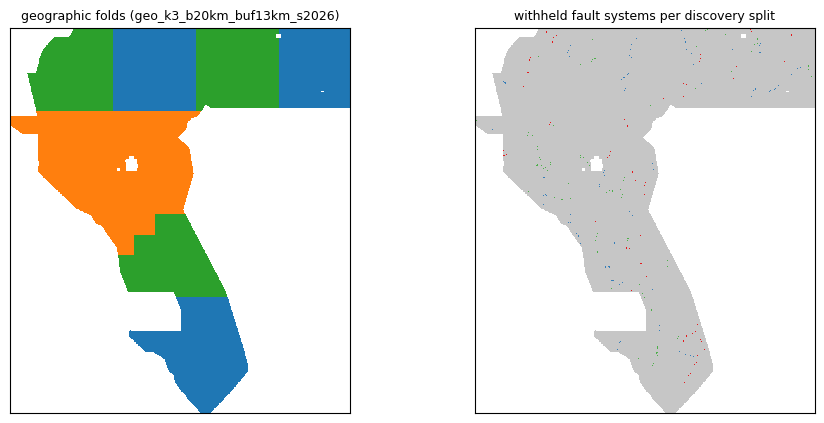

In [10]:
pipe.step('spatial_folds')
pipe.step('discovery_splits')
print(pipe.pc.fold_rel, '|', pipe.pc.discovery_rel)
from gems_bench.pipeline.status import fold_figure, save_fig
fig = fold_figure(pipe.pc)
if fig is not None:
    display(fig); save_fig(pipe.pc, fig, 'validation_design')

## 12. Feature store: create once, reuse

Families: raw 19-channel geophysics · Phase 2 engineered · Phase 1 `eda:*` maps · Phase 4 remote-sensing structural features (those the baselines use, or all) · Phase 5 fault-normal profiles · 1 m DEM aggregates. Only missing features are computed. Each family is pushed to Drive as soon as it exists.

Feature-group prerequisites: only the `eda:*` family needs the Phase-1 EDA rasters. If they are missing, that family is deferred and named in the error, while every other family is still built and kept. This means a G1 LightGBM baseline never waits for the EDA, the advanced feature bank or the DEM pilot. `data/feature_store/pipeline_feature_registry.csv` declares, per feature: name, source, transform, scale, support, CRS / grid, NoData behaviour, standardisation and a spec hash.

In [11]:
pipe.step('feature_store')
reg = pathlib.Path('/content/gems_work/data/feature_store/pipeline_feature_registry.csv')
if reg.exists():
    fr = pd.read_csv(reg)
    display(fr.groupby('family').agg(n=('name', 'size'), cached=('cached', 'sum')))

pipe.step('dem_pilot')                               # only runs when the DEM pilot is enabled

if CONFIG['run_mode'] == 'PREPARE_DATA':
    print('PREPARE_DATA ends here (no model training). Next: set run_mode="BASELINES", train_baselines=["G1"], '
          'and run from section 1. The baseline cells below only report the cached state in this mode.')
    pipe.failure_report()

[sync in] 4 copied (0.1 MiB), 0 unchanged, 1s: ['outputs/phase4/cache/features/rs_feature_registry.csv', 'data/feature_store/phase5/p5_feature_registry.csv', 'data/feature_store/pipeline_feature_registry.csv', 'data/feature_store/feature_provenance.json']
[feature_store] SKIP_CACHED: feature_store: ok (139 checks)
[feature_store] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_mag_anom.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_rtp.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_tmi_hg.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_geod_2ndinv.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_iso_grav_anom_slope.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_tc.npy']


,n,cached
family,,
phase2,48,48
phase2_eda,5,5
phase4_rs,67,67
raw,19,19


[dem_pilot] not part of mode ADVANCED_RESEARCH: outputs missing - dem_pilot: missing - f1_dem_pilot__888c6e12:prepare: missing - pending


## 13. Baselines: restore or train

G1 terrain LightGBM, G3 engineered LightGBM, RS05 (Phase 4), CNN-A and CNN-B (distance-aware), gated dual encoder, plus the label-free B0 lineament floor. A reported score is not a model: each baseline is `AVAILABLE` only if its finished run folder and maps are found and verified. Otherwise it is `NOT_AVAILABLE`, or it is retrained from the committed configuration snapshot **only when listed in `train_baselines`** and the mode is `BASELINES` or later.

**Next execution target: G1** (`run_mode='BASELINES'`, `train_baselines=['G1']`, CPU). It runs geographic CV, then a full fit per pseudo-discovery split. OOF and discovery maps and `PROVENANCE.json` (fold / split sha256, `historical_equivalence: false`) go to Drive. A regenerated G1 is a new run under the historical recipe. It is not a reproduction of the historical DTI until its metrics have been checked. GPU baselines on a CPU runtime are listed as *not attempted*.

In [12]:
pipe.step('baselines')
display(pipe.baselines())

[sync in] 125 copied (87.1 MiB), 0 unchanged, 29s: ['outputs/benchmark/experiments/b0_lineament_fused_s2026', 'outputs/benchmark/experiments/lgbm_G1_s2026', 'outputs/benchmark/experiments/disc0_lgbm_G1_s2026', 'outputs/benchmark/experiments/disc1_lgbm_G1_s2026', 'outputs/benchmark/experiments/disc2_lgbm_G1_s2026', 'outputs/benchmark/experiments/lgbm_G3_s2026', 'outputs/benchmark/experiments/disc0_lgbm_G3_s2026', 'outputs/benchmark/experiments/disc1_lgbm_G3_s2026', 'outputs/benchmark/experiments/disc2_lgbm_G3_s2026', 'outputs/phase4/experiments/p4_RS05_G3_noSS_RS_s2026', 'outputs/phase4/experiments/disc0_RS05_G3_noSS_RS', 'outputs/phase4/experiments/disc1_RS05_G3_noSS_RS', 'outputs/phase4/experiments/disc2_RS05_G3_noSS_RS', 'reports/pipeline/baseline_status.csv']
[sync out] 125 copied (87.1 MiB), 0 unchanged, 3s: ['outputs/benchmark/experiments/b0_lineament_fused_s2026', 'outputs/benchmark/experiments/lgbm_G1_s2026', 'outputs/benchmark/experiments/disc0_lgbm_G1_s2026', 'outputs/benchmar

,model,kind,gpu,cv_dir,origin,status,discovery,checkpoints,detail
0,B0_lineament,map,False,outputs/benchmark/experiments/b0_lineament_fus...,regenerated,AVAILABLE,n/a,False,
1,G1,lgbm_p2,False,outputs/benchmark/experiments/lgbm_G1_s2026,regenerated,AVAILABLE,3/3,True,
2,G3,lgbm_p2,False,outputs/benchmark/experiments/lgbm_G3_s2026,regenerated,AVAILABLE,3/3,True,
3,RS05_G3_noSS_RS,lgbm_rs,False,outputs/phase4/experiments/p4_RS05_G3_noSS_RS_...,regenerated,AVAILABLE,3/3,True,
4,CNN_A_dti,cnn3,True,outputs/phase3/experiments/p3_CNN_A_dti_p256_s...,,NOT_AVAILABLE,0/3,False,no run folder
5,DL00_CNN_B_dti,cnn3_p4,True,outputs/phase4/experiments/p4_DL00_CNN_B_dti_p...,,NOT_AVAILABLE,0/3,False,no run folder
6,DL02_CNN_TMGB_dti,cnn3_p4,True,outputs/phase4/experiments/p4_DL02_CNN_TMGB_dt...,,NOT_AVAILABLE,0/3,False,no run folder
7,P4_B_gated,cnn4,True,outputs/phase4/experiments/p4_P4_B_gated_p256_...,,NOT_AVAILABLE,0/3,False,no run folder


## 14–15. Research experiments: inventory → reuse → SCREEN / VALIDATE / FULL

**Progressive experimentation.** Cheap screening first, full validation only for shortlisted candidates:

`SCREEN` (1 fold, capped budget, proxy metrics) → shortlist → `VALIDATE` (3 folds + 1 discovery split) → shortlist → `FULL` (committed protocol, section-17 gate).

* **Reuse first.** `pipe.inventory()` lists every experiment folder on Drive (profile, completed folds / splits, metrics, reusability, next action). `pipe.plan_experiments()` shows what this session will do: `REUSE_FULL` (a compatible FULL run is complete: never retrained), `DONE`, `RESUME` (unit-level, from checkpoints), `RUN`, `NOT_NEEDED`.
* **Identity.** SCREEN / VALIDATE runs live in their own folders (`<name>__screen__<hash>`), so they can never overwrite or resume a FULL run. FULL keeps the historical ids (`b0_reference__d54e938a`, ...).
* **Matched control.** Every SCREEN / VALIDATE candidate is compared with `b0_reference` trained under the *same* profile, on the *same* fold, budget and scored pixels (mask digests are checked).
* **Proxy metrics.** SCREEN / VALIDATE numbers are labelled `proxy_*`. They never enter the scoreboard, the registry or the promotion gate. Only FULL runs do.
* **B1** needs the label-free `B0_lineament` map. It is found and verified on Drive, or built with its original CPU recipe (minutes) before B1 starts.
* **E1** (`e1_gsn_parity`) is a *parity check*. It uses the same modules, widths, construction order and seed as B0, so identical training is the expected result, not an architectural gain.

In [13]:
# P0 - read-only: what already exists (no GPU)
inv = pipe.inventory()
display(inv[['experiment_id', 'role', 'profile', 'folds_done', 'discovery_done', 'evaluation_done',
             'metrics_available', 'reusable', 'next_action']])
res = pipe.compare_results()          # reports/experiment_screening: metrics, paired deltas, shortlist, figures
print('report:', res['dir'])

# what this session will train at the selected profile (read-only)
display(pipe.plan_experiments())

# train only the missing work (RUN / RESUME); completed FULL runs are reused
pipe.step('advanced_models')

[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['reports/pipeline/experiment_inventory.csv']


,experiment_id,role,profile,folds_done,discovery_done,evaluation_done,metrics_available,reusable,next_action
0,b0_reference__d54e938a,control,FULL,"0,1,2","0,1,2",True,True,True,REPORT (complete; reuse results)
1,b1_bg_weight__7755635b,candidate,FULL,"0,1,2","0,1,2",True,True,True,REPORT (complete; reuse results)
2,b2_nnpu_p010__e0173a9a,candidate,FULL,"0,1,2","0,1,2",True,True,True,REPORT (complete; reuse results)
3,c1_geometry_heads__9a77180d,candidate,FULL,"0,1,2","0,1,2",True,True,True,REPORT (complete; reuse results)
4,e1_gsn_parity__b8b8c3db,parity_check,FULL,"0,1",,False,False,False,"RESUME train: folds [2] / splits [0, 1, 2] mis..."
5,g1_ensemble__93a1a694,candidate,FULL,,,False,False,False,"KEEP (incomplete, incompatible configuration: ..."
6,pipeline_scoreboard__811cf5c2,candidate,FULL,,,True,True,True,REPORT (complete; reuse results)
7,pipeline_scoreboard__a50ac697,candidate,FULL,,,True,True,True,REPORT (complete; reuse results)


[sync out] 14 copied (0.6 MiB), 0 unchanged, 1s: ['reports/experiment_screening']
report: /content/gems_work/reports/experiment_screening


,experiment,role,profile,experiment_id,action,reason,reuse_id
0,b0_reference,control,SCREEN,b0_reference__screen__fefd5b34,NOT_NEEDED,no candidate at this profile needs the matched...,NaN
1,b1_bg_weight,candidate,SCREEN,b1_bg_weight__screen__a4a67628,REUSE_FULL,FULL run b1_bg_weight__7755635b is complete,b1_bg_weight__7755635b
2,b2_nnpu_p010,candidate,SCREEN,b2_nnpu_p010__screen__3e8aff9a,REUSE_FULL,FULL run b2_nnpu_p010__e0173a9a is complete,b2_nnpu_p010__e0173a9a
3,c1_geometry_heads,candidate,SCREEN,c1_geometry_heads__screen__8b62e578,REUSE_FULL,FULL run c1_geometry_heads__9a77180d is complete,c1_geometry_heads__9a77180d


[advanced] plan (SCREEN): b0_reference=NOT_NEEDED, b1_bg_weight=REUSE_FULL, b2_nnpu_p010=REUSE_FULL, c1_geometry_heads=REUSE_FULL
[sync out] 14 copied (0.6 MiB), 0 unchanged, 0s: ['reports/experiment_screening']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/advanced_models.json']
[advanced_models] DONE: advanced_models: ok (4 checks)
[advanced_models] outputs: ['/content/drive/MyDrive/GEMS_2/experiments/b0_reference__screen__fefd5b34', '/content/drive/MyDrive/GEMS_2/experiments/b1_bg_weight__screen__a4a67628', '/content/drive/MyDrive/GEMS_2/experiments/b2_nnpu_p010__screen__3e8aff9a', '/content/drive/MyDrive/GEMS_2/experiments/c1_geometry_heads__screen__8b62e578']


StageResult(stage='advanced_models', decision='RUN', outcome='DONE', validation='ok', reason='advanced_models: ok (4 checks)', recovery='', seconds=2.516732578000017, summary={'completed': ['b0_reference', 'b1_bg_weight', 'b2_nnpu_p010', 'c1_geometry_heads'], 'trained': []}, outputs=['experiments/b0_reference__screen__fefd5b34', 'experiments/b1_bg_weight__screen__a4a67628', 'experiments/b2_nnpu_p010__screen__3e8aff9a', 'experiments/c1_geometry_heads__screen__8b62e578'], location='', traceback='', root_causes=[])

### Research dashboard and promotion to the next fidelity level

The dashboard shows the session profile, completed / incomplete experiments, remaining folds and splits, estimated GPU minutes, recorded GPU time, available maps, shortlist decisions and Drive usage (CSV + PNG/SVG under `reports/pipeline`).

Shortlist decisions (`PROMOTE_TO_VALIDATE`, `PROMOTE_TO_FULL`, `REVIEW`, `REJECT`, `PARITY_CONFIRMED`, `INCOMPARABLE`) are **recommendations** from configurable triage heuristics (`screening_rules`). Moving to the next level is your decision: copy the shortlisted names into `advanced_experiments`, set `experiment_profile` and re-run this section. Promoting a model for **submission** remains a separate, manual registry transition (section 16–17).

,item,value
0,experiment profile,SCREEN
1,experiments complete / total,6 / 8
2,incomplete (compatible),1
3,folds remaining,1
4,discovery splits remaining,3
5,planned runs at SCREEN,none
6,estimated GPU min per planned run (typical / u...,3.8 / 3.8 (estimate)
7,recorded GPU training min (all runs),229.5
8,model maps available (FULL),4
9,last checkpoint,"{""file"": ""disc2_model.pt"", ""experiment_id"": ""c..."


,experiment,role,profile,experiment_id,action,reason,reuse_id
0,b0_reference,control,SCREEN,b0_reference__screen__fefd5b34,NOT_NEEDED,no candidate at this profile needs the matched...,NaN
1,b1_bg_weight,candidate,SCREEN,b1_bg_weight__screen__a4a67628,REUSE_FULL,FULL run b1_bg_weight__7755635b is complete,b1_bg_weight__7755635b
2,b2_nnpu_p010,candidate,SCREEN,b2_nnpu_p010__screen__3e8aff9a,REUSE_FULL,FULL run b2_nnpu_p010__e0173a9a is complete,b2_nnpu_p010__e0173a9a
3,c1_geometry_heads,candidate,SCREEN,c1_geometry_heads__screen__8b62e578,REUSE_FULL,FULL run c1_geometry_heads__9a77180d is complete,c1_geometry_heads__9a77180d


,experiment,experiment_id,role,profile,configuration_hash,config_compatible,folds_done,folds_expected,discovery_done,discovery_expected,...,metrics_available,checkpoints,maps,complete,reusable,next_action,git_commit,updated,gpu_train_min,error
0,b0_reference,b0_reference__d54e938a,control,FULL,d54e938a5b70,True,"0,1,2","0,1,2","0,1,2","0,1,2",...,True,6,1,True,True,REPORT (complete; reuse results),8bccce056e36,2026-10-22T23:09:04,54.6,
1,b1_bg_weight,b1_bg_weight__7755635b,candidate,FULL,7755635b0dcf,True,"0,1,2","0,1,2","0,1,2","0,1,2",...,True,6,1,True,True,REPORT (complete; reuse results),8bab38b4b467,2026-10-25T14:24:39,66.1,
2,b2_nnpu_p010,b2_nnpu_p010__e0173a9a,candidate,FULL,e0173a9af42c,True,"0,1,2","0,1,2","0,1,2","0,1,2",...,True,6,1,True,True,REPORT (complete; reuse results),8bccce056e36,2026-10-22T23:46:25,34.0,
3,c1_geometry_heads,c1_geometry_heads__9a77180d,candidate,FULL,9a77180d2d70,True,"0,1,2","0,1,2","0,1,2","0,1,2",...,True,6,1,True,True,REPORT (complete; reuse results),8bccce056e36,2026-10-23T00:44:04,52.1,
4,e1_gsn_parity,e1_gsn_parity__b8b8c3db,parity_check,FULL,b8b8c3dbfcc1,True,"0,1","0,1,2",,"0,1,2",...,False,2,0,False,False,"RESUME train: folds [2] / splits [0, 1, 2] mis...",8bccce056e36,2026-10-23T01:07:15,22.7,
5,g1_ensemble,g1_ensemble__93a1a694,candidate,FULL,93a1a6945426,False,,"0,1,2",,"0,1,2",...,False,0,0,False,False,"KEEP (incomplete, incompatible configuration: ...",0eb9e540cba0,2026-10-25T23:31:26,NaN,FileNotFoundError: members without OOF + all d...
6,pipeline_scoreboard,pipeline_scoreboard__811cf5c2,candidate,FULL,811cf5c2e8e0,None,,"0,1,2",,"0,1,2",...,True,0,0,True,True,REPORT (complete; reuse results),8bab38b4b467,2026-10-25T14:27:56,NaN,
7,pipeline_scoreboard,pipeline_scoreboard__a50ac697,candidate,FULL,a50ac6979f22,None,,"0,1,2",,"0,1,2",...,True,0,0,True,True,REPORT (complete; reuse results),0eb9e540cba0,2026-10-25T23:31:24,NaN,


,experiment,experiment_id,profile,role,decision,reason,primary_gain,recall300_drop,folds_beating,folds_compared,frac_p_gt_099,mean_p,rules


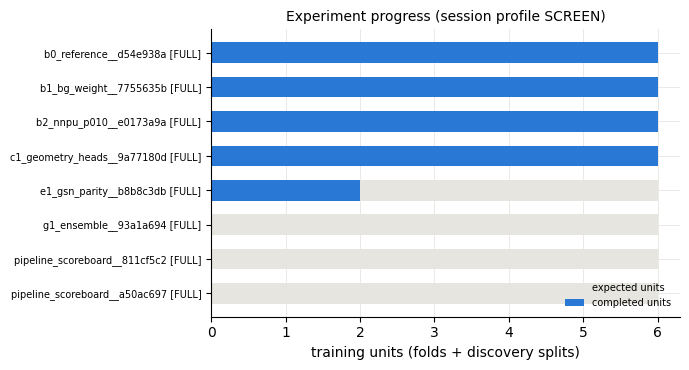

[sync out] 9 copied (0.2 MiB), 4 unchanged, 0s: ['reports/pipeline']
SCREEN -> VALIDATE: []
VALIDATE -> FULL  : []


In [14]:
dash = pipe.research_dashboard()

next_validate = pipe.shortlist('SCREEN')        # recommended for VALIDATE
next_full = pipe.shortlist('VALIDATE')          # recommended for FULL
print('SCREEN -> VALIDATE:', next_validate)
print('VALIDATE -> FULL  :', next_full)
# To promote (explicit): CONFIG.update({'experiment_profile': 'VALIDATE', 'advanced_experiments': next_validate})
# then re-run the configuration and pipeline cells, and this section.

## 16–17. Geographic and pseudo-discovery validation, model comparison and promotion

One protocol for every available model: geographic DTI (cross-fitted area budget) and pseudo-discovery DTI (withheld systems excluded / retained as FP) are reported **separately**; `public_lb` comes only from your manual `reports/leaderboard_log.csv`. Promotion to `promoted` is a manual, evidence-backed registry transition.

In [15]:
pipe.step('discovery_validation')
sb = pathlib.Path('/content/gems_work/reports/pipeline/scoreboard_latest.csv')
if sb.exists():
    b = __import__('pandas').read_csv(sb)
    display(b[[c for c in ('model', 'geo_dti_area', 'geo_fold_min', 'disc_dti_excl', 'disc_dti_retained_fp',
                           'short_recall_w', 'public_lb') if c in b.columns]])
from gems_bench.artifacts import ModelRegistry
display(ModelRegistry(pipe.pc.local / 'model_registry').table())
# Manual promotion (only when the candidate's promotion_decisions say promote=True):
# from gems_bench.experiment.promote import promote
# promote('<model_name>', '<experiment_id>'); pipe.push_all()

[sync in] 29 copied (0.5 MiB), 0 unchanged, 5s: ['experiments/pipeline_scoreboard__a50ac697', 'reports/pipeline/scoreboard_latest.csv']
2026-10-26T00:22:54 stage prepare start (attempt 1)
2026-10-26T00:22:54 stage prepare done
[sync out] 4 copied (0.0 MiB), 0 unchanged, 0s: ['experiments/pipeline_scoreboard__f0367089', 'model_registry']
2026-10-26T00:22:54 stage train start (attempt 1)
2026-10-26T00:22:54 stage train done
[sync out] 2 copied (0.0 MiB), 2 unchanged, 0s: ['experiments/pipeline_scoreboard__f0367089', 'model_registry']
2026-10-26T00:22:54 stage evaluate start (attempt 1)
evaluate_models: 3 maps, 3 with discovery, 77s
2026-10-26T00:24:14 stage evaluate done
[sync out] 21 copied (0.5 MiB), 2 unchanged, 0s: ['experiments/pipeline_scoreboard__f0367089', 'model_registry']
2026-10-26T00:24:15 stage export start (attempt 1)
2026-10-26T00:24:15 stage export done
[sync out] 4 copied (0.0 MiB), 21 unchanged, 0s: ['experiments/pipeline_scoreboard__f0367089', 'model_registry']


/content/GEMS/gems_bench/artifacts/registry.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  t = pd.concat([t[t.name != row["name"]], pd.DataFrame([{c: row.get(c) for c in COLUMNS}])], ignore_index=True)


[sync out] 5 copied (0.0 MiB), 25 unchanged, 0s: ['experiments/pipeline_scoreboard__f0367089', 'model_registry']
[sync out] 29 copied (0.5 MiB), 0 unchanged, 1s: ['experiments/pipeline_scoreboard__a50ac697', 'reports/pipeline/scoreboard_latest.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/discovery_validation.json']
[discovery_validation] DONE: discovery_validation: ok (1 checks)
[discovery_validation] outputs: ['/content/drive/MyDrive/GEMS_2/experiments/pipeline_scoreboard__a50ac697', '/content/drive/MyDrive/GEMS_2/reports/pipeline/scoreboard_latest.csv']


,model,geo_dti_area,geo_fold_min,disc_dti_excl,disc_dti_retained_fp,short_recall_w,public_lb
0,G1,0.132652,0.116454,0.100085,0.084869,0.137625,NaN
1,G3,0.116544,0.103700,0.074956,0.058492,0.133175,NaN
2,RS05_G3_noSS_RS,0.142885,0.131516,0.118566,0.094541,0.162635,NaN


,name,status,kind,experiment_id,oof,discovery,config_hash,git_commit,geo_dti,disc_dti_excl,disc_dti_retained_fp,protocol_hash,updated,notes
0,G1,baseline,lgbm,lgbm_G1_s2026,NaN,{},NaN,NaN,0.132652,0.100085,0.084869,dc29ba9f7fce,2026-10-26T00:24:15,terrain LightGBM (Phase 2)
1,RS05_G3_noSS_RS,baseline,lgbm,p4_RS05_G3_noSS_RS_s2026,NaN,{},NaN,NaN,0.142885,0.118566,0.094541,dc29ba9f7fce,2026-10-26T00:24:15,G3 without seismicity/strain + RS terrain/pote...


## 18. Ensemble optimisation

Members (≥ 2 with OOF + every discovery map) enter as per-fold rank quantiles; geographic weights are chosen on other folds, discovery weights with each split's withheld systems removed. An ensemble must pass the same gate against its best member.

In [16]:
pipe.step('ensemble')

[ensemble] not part of mode ADVANCED_RESEARCH: outputs missing - ensemble: missing - g1_ensemble__29dfaf7e: missing - members=['G1', 'RS05_G3_noSS_RS']


Report(name='ensemble', checks=[Check(path='experiments/g1_ensemble__29dfaf7e', status='missing', reason="members=['G1', 'RS05_G3_noSS_RS']", info={})], notes=[])

## 18b. M6 — model selection from existing FULL experiments (no training)

**Central question.** Can B0's short-fault recall and retained-FP robustness be combined with B1's geographic generalisation and discovery DTI? M6 answers it from the **saved FULL predictions only**. It uses no GPU and does no neural training, and it only reads the original experiment folders.

**Prerequisites.** Run the configuration, Drive and install cells (1–4) and sections 7–12; these are cached and do not train. M6 stages only the prediction rasters, manifests and metrics of the analysed experiments, never their checkpoints.

| phase | what | leakage protection |
|---|---|---|
| M6.1 audit | inventory, provenance, compatibility, missing artifacts (`COMPLETE / PARTIAL / INCOMPATIBLE / MISSING / INVALID`) | read-only; stops if a FULL map is missing |
| M6.2 paired | one consolidated section-17 scorecard; per-fold / per-split deltas vs B0 and B1; spatial-block bootstrap | area budget of fold *k* chosen on the other folds |
| M6.3 calibration | raw, rank, robust quantile, linear, temperature, isotonic, area budget, absolute-threshold transfer | every label-dependent parameter cross-fitted |
| M6.4 ensembles | B0+B1 mean / rank mean / nested weighted rank and robust; then B2 / C1 additions | weights + budget per fold chosen on the other folds; discovery weights never see the scored split |
| M6.5 complementarity | equal-area overlap; both / B0-only / B1-only / neither by length, fold, strike, contrast, junctions; case-study panels | descriptive |
| M6.6 postprocessing | small-component filter, gap closing, direction-aware linking, skeleton width, minimum length, orientation filter | parameters chosen on the other folds; identity always allowed |
| M6.7 gate | section-17 gate extended, against **both** B0 and B1: `PROMOTE / REVIEW / REJECT / INSUFFICIENT_EVIDENCE` | FULL members only; nothing is promoted automatically |

Every analysis unit is fingerprinted, so a re-run reuses finished units (`overwrite_existing=True` recomputes them). Outputs go to `/content/drive/MyDrive/GEMS_2/reports/m6/`: tables, figures with their CSV data, and `M6_RESEARCH_REPORT.md`. Guide: `docs/M6_RESULTS_GUIDE.md`. **No improvement is claimed until these cells have run.**

In [17]:
M6_CONFIG = {                                       # overrides configs/m6/model_selection.yaml (unknown keys rejected)
    'enabled': True,
    'mode': 'ANALYZE_EXISTING',                      # the only mode: M6 never trains
    'models': ['b0_reference', 'b1_bg_weight', 'b2_nnpu_p010', 'c1_geometry_heads'],
    'primary_pair': ['b0_reference', 'b1_bg_weight'],
    'run_calibration': True,
    'run_ensemble': True,
    'run_complementarity': True,
    'run_postprocessing': True,
    'run_promotion_audit': True,
    'train_models': False,                           # True is refused
    'overwrite_existing': False,                     # True recomputes every analysis unit
    'save_figures': True,
    'save_csv': True,
    'save_parquet': True,
    # e.g. 'ensemble': {'weights': [0.0, 0.25, 0.5, 0.75, 1.0], 'refine': True}, 'save_rasters': 'all'
}

from IPython.display import Image, Markdown, display

m6 = pipe.m6(M6_CONFIG)

def show(names, sub='figures'):
    for n in names:
        p = m6.ws.root / sub / f'{n}.png'
        display(Image(filename=str(p))) if p.exists() else print('not produced:', p.name)

# M6.1 - read-only audit; raises M6ArtifactError (with a recovery hint) if a required FULL map is missing
if M6_CONFIG['enabled']:
    audit = m6.audit()
    inv = audit['inventory']
    display(inv[[c for c in ('model', 'kind', 'status', 'experiment_id', 'profile', 'folds_done', 'n_disc_maps',
                             'feature_version', 'git_commit', 'registry_status', 'reasons') if c in inv]])
    display(audit['compatibility'])
    display(audit['missing'])

[sync out] 8 copied (0.0 MiB), 0 unchanged, 0s: ['reports/m6']
          model   status               experiment_id profile  n_disc_maps        reasons
    P5_B0_gated COMPLETE      b0_reference__d54e938a    FULL          3.0               
      P5_B1_bgw COMPLETE      b1_bg_weight__7755635b    FULL          3.0               
P5_B2_nnpu_p010 COMPLETE      b2_nnpu_p010__e0173a9a    FULL          3.0               
    P5_C1_heads COMPLETE c1_geometry_heads__9a77180d    FULL          3.0               
P5_E1_gsn_gated  MISSING     e1_gsn_parity__b8b8c3db    FULL          0.0 OOF map absent
   B0_lineament COMPLETE                         NaN    FULL          NaN               
             G1 COMPLETE                         NaN    FULL          NaN               
             G3 COMPLETE                         NaN    FULL          NaN               
[sync in] 137 copied (133.0 MiB), 3 unchanged, 30s: ['experiments/b0_reference__d54e938a/manifest.json', 'experiments/b0_reference__d54e

,model,kind,status,experiment_id,profile,folds_done,n_disc_maps,feature_version,git_commit,registry_status,reasons
0,P5_B0_gated,experiment,COMPLETE,b0_reference__d54e938a,FULL,"0,1,2",3.0,8795de7cfac1,8bccce056e364d37b2323582195ba090b85868c5,,
1,P5_B1_bgw,experiment,COMPLETE,b1_bg_weight__7755635b,FULL,"0,1,2",3.0,8795de7cfac1,8bab38b4b46747501c07e72b18ce454732a9ad3d,,
2,P5_B2_nnpu_p010,experiment,COMPLETE,b2_nnpu_p010__e0173a9a,FULL,"0,1,2",3.0,8795de7cfac1,8bccce056e364d37b2323582195ba090b85868c5,,
3,P5_C1_heads,experiment,COMPLETE,c1_geometry_heads__9a77180d,FULL,"0,1,2",3.0,8795de7cfac1,8bccce056e364d37b2323582195ba090b85868c5,,
4,P5_E1_gsn_gated,experiment,MISSING,e1_gsn_parity__b8b8c3db,FULL,"0,1",0.0,8795de7cfac1,8bccce056e364d37b2323582195ba090b85868c5,,OOF map absent
5,B0_lineament,baseline,COMPLETE,NaN,FULL,NaN,NaN,NaN,NaN,NaN,
6,G1,baseline,COMPLETE,NaN,FULL,NaN,NaN,NaN,NaN,NaN,
7,G3,baseline,COMPLETE,NaN,FULL,NaN,NaN,NaN,NaN,NaN,


,model_a,model_b,status_a,status_b,same_folds_fp,same_discovery_fp,same_protocol_hash,same_feature_version,same_git_commit,same_seed,comparable,blocking
0,P5_B0_gated,P5_B1_bgw,COMPLETE,COMPLETE,True,True,True,True,False,True,True,
1,P5_B0_gated,P5_B2_nnpu_p010,COMPLETE,COMPLETE,True,True,True,True,True,True,True,
2,P5_B0_gated,P5_C1_heads,COMPLETE,COMPLETE,True,True,True,True,True,True,True,
3,P5_B0_gated,P5_E1_gsn_gated,COMPLETE,MISSING,None,None,None,True,True,True,False,
4,P5_B0_gated,B0_lineament,COMPLETE,COMPLETE,False,False,False,False,False,False,False,"folds_fp,discovery_fp,protocol_hash"
5,P5_B0_gated,G1,COMPLETE,COMPLETE,False,False,False,False,False,False,False,"folds_fp,discovery_fp,protocol_hash"
6,P5_B0_gated,G3,COMPLETE,COMPLETE,False,False,False,False,False,False,False,"folds_fp,discovery_fp,protocol_hash"
7,P5_B1_bgw,P5_B2_nnpu_p010,COMPLETE,COMPLETE,True,True,True,True,False,True,True,
8,P5_B1_bgw,P5_C1_heads,COMPLETE,COMPLETE,True,True,True,True,False,True,True,
9,P5_B1_bgw,P5_E1_gsn_gated,COMPLETE,MISSING,None,None,None,True,False,True,False,


,model,artifact,path,required
0,P5_E1_gsn_gated,OOF prediction,/content/drive/MyDrive/GEMS_2/experiments/e1_g...,True


### M6.2 Consolidated comparison and paired geographic evidence

All models are re-scored together on one protocol (same folds, splits, budgets and policies). `reference_check` compares the numbers from the previous review with the persisted and recomputed scores and **reports** any difference. With three folds and three splits the paired tables are descriptive: direction, size, worst unit, and a spatial-block bootstrap (the folds' 20 km blocks, resampled inside each held-out zone). They are not significance tests.

evaluate_models: 7 maps, 7 with discovery, 167s
[m6] scorecard: computed in 167s
[sync out] 10 copied (0.4 MiB), 8 unchanged, 0s: ['reports/m6']
[m6] paired: computed in 190s
[sync out] 39 copied (1.2 MiB), 18 unchanged, 1s: ['reports/m6']


,model,metric,reference_observation,persisted,recomputed,persisted_minus_reference,recomputed_minus_persisted,status
0,P5_B0_gated,geo_dti_area,0.16456,0.164560,0.164560,3.340786e-07,8.326673e-17,MATCH
1,P5_B0_gated,geo_fold_min,0.15341,0.153408,0.153408,-2.409411e-06,2.775558e-17,MATCH
2,P5_B0_gated,disc_dti_excl,0.20304,0.203035,0.203035,-5.197918e-06,2.775558e-17,MATCH
3,P5_B0_gated,disc_dti_retained_fp,0.09635,0.096351,0.096351,7.677782e-07,6.938894e-17,MATCH
4,P5_B0_gated,short_recall_w,0.19240,0.192396,0.192396,-4.278238e-06,2.775558e-17,MATCH
5,P5_B1_bgw,geo_dti_area,0.16788,0.167877,0.167877,-3.465959e-06,8.326673e-17,MATCH
6,P5_B1_bgw,geo_fold_min,0.16309,0.163087,0.163087,-3.309917e-06,0.000000e+00,MATCH
7,P5_B1_bgw,disc_dti_excl,0.20860,0.208598,0.208598,-1.979844e-06,0.000000e+00,MATCH
8,P5_B1_bgw,disc_dti_retained_fp,0.09128,0.091277,0.091277,-2.859487e-06,5.551115e-17,MATCH
9,P5_B1_bgw,short_recall_w,0.17954,0.179544,0.179544,3.532493e-06,5.551115e-17,MATCH


,model,geo_dti_area,geo_fold_min,geo_fold_std,disc_dti_excl,disc_dti_retained_fp,short_recall_w,geo_far_share_at_match
0,P5_B0_gated,0.164560,0.153408,0.011874,0.203035,0.096351,0.192396,0.571171
1,P5_B1_bgw,0.167877,0.163087,0.004307,0.208598,0.091277,0.179544,0.533516
2,P5_B2_nnpu_p010,0.136179,0.124361,0.010390,0.208077,0.090033,0.154436,0.553292
3,P5_C1_heads,0.142457,0.116906,0.016840,0.195734,0.095121,0.146505,0.583366
4,B0_lineament,0.068924,0.064551,0.004285,0.039337,0.037960,0.079976,0.615914
5,G1,0.132652,0.116454,0.013462,0.100085,0.084869,0.137625,0.512956
6,G3,0.116544,0.103700,0.015639,0.074956,0.058492,0.133175,0.511815


fold,0,1,2
model,,,
B0_lineament,0.064551,0.074998,0.068896
G1,0.148971,0.116454,0.127962
G3,0.137010,0.103968,0.103700
P5_B0_gated,0.153408,0.156302,0.179918
P5_B1_bgw,0.173332,0.163087,0.166036
P5_B2_nnpu_p010,0.134882,0.124361,0.149691
P5_C1_heads,0.148276,0.116906,0.155787


split                               0         1         2
policy      model                                        
excl        B0_lineament     0.024857  0.055777  0.033612
            G1               0.099076  0.122196  0.075772
            G3               0.078052  0.092056  0.048320
            P5_B0_gated      0.232977  0.223356  0.129263
            P5_B1_bgw        0.227657  0.214825  0.179109
            P5_B2_nnpu_p010  0.226850  0.238262  0.151898
            P5_C1_heads      0.220428  0.222260  0.116308
retained_fp B0_lineament     0.023404  0.054068  0.031781
            G1               0.083380  0.105655  0.055329
            G3               0.061968  0.071551  0.037601
            P5_B0_gated      0.111538  0.108256  0.063554
            P5_B1_bgw        0.097723  0.100547  0.071162
            P5_B2_nnpu_p010  0.088638  0.109944  0.054069
            P5_C1_heads      0.101106  0.115635  0.067535

,model,reference,n_units,mean_delta,median_delta,min_delta,max_delta,units_improved,directional_consistency,effect_size_dz,sign_pattern,note,task,policy
0,B0_lineament,P5_B0_gated,3,-0.093728,-0.088857,-0.111022,-0.081304,0,1.000000,-6.067988,---,"descriptive: 3 folds, no population-level test",geographic,NaN
1,G1,P5_B0_gated,3,-0.032080,-0.039847,-0.051956,-0.004437,0,1.000000,-1.299127,---,"descriptive: 3 folds, no population-level test",geographic,NaN
2,G3,P5_B0_gated,3,-0.048316,-0.052333,-0.076218,-0.016398,0,1.000000,-1.604573,---,"descriptive: 3 folds, no population-level test",geographic,NaN
3,P5_B1_bgw,P5_B0_gated,3,0.004276,0.006785,-0.013882,0.019925,2,0.666667,0.250891,++-,"descriptive: 3 folds, no population-level test",geographic,NaN
4,P5_B2_nnpu_p010,P5_B0_gated,3,-0.026898,-0.030228,-0.031940,-0.018526,0,1.000000,-3.684158,---,"descriptive: 3 folds, no population-level test",geographic,NaN
5,P5_C1_heads,P5_B0_gated,3,-0.022886,-0.024132,-0.039395,-0.005132,0,1.000000,-1.333258,---,"descriptive: 3 folds, no population-level test",geographic,NaN
6,B0_lineament,P5_B0_gated,3,-0.157116,-0.167579,-0.208120,-0.095650,0,1.000000,-2.758360,---,"descriptive: 3 splits, no population-level test",discovery,excl
7,B0_lineament,P5_B0_gated,3,-0.058032,-0.054188,-0.088134,-0.031773,0,1.000000,-2.045066,---,"descriptive: 3 splits, no population-level test",discovery,retained_fp
8,G1,P5_B0_gated,3,-0.096184,-0.101160,-0.133901,-0.053491,0,1.000000,-2.378707,---,"descriptive: 3 splits, no population-level test",discovery,excl
9,G1,P5_B0_gated,3,-0.012995,-0.008225,-0.028157,-0.002602,0,1.000000,-0.967647,---,"descriptive: 3 splits, no population-level test",discovery,retained_fp


,model,reference,observed_delta,boot_median,boot_q05,boot_q95,p_delta_positive,n_boot,n_blocks,n_strata,note,task,block_km
0,P5_B1_bgw,P5_B0_gated,0.003316,0.003445,-0.004580,0.010992,0.742,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic,20.0
1,P5_B1_bgw,P5_B0_gated,0.005563,0.004942,-0.006288,0.016450,0.766,1000,335,3,spatial-block bootstrap at the cross-fitted op...,discovery_excl,20.0
2,P5_B2_nnpu_p010,P5_B0_gated,-0.028381,-0.028494,-0.036255,-0.019985,0.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic,20.0
3,P5_B2_nnpu_p010,P5_B0_gated,0.005042,0.004607,-0.005988,0.015975,0.753,1000,335,3,spatial-block bootstrap at the cross-fitted op...,discovery_excl,20.0
4,P5_C1_heads,P5_B0_gated,-0.022103,-0.022357,-0.030690,-0.013943,0.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic,20.0
5,P5_C1_heads,P5_B0_gated,-0.007301,-0.007374,-0.017082,0.002721,0.119,1000,335,3,spatial-block bootstrap at the cross-fitted op...,discovery_excl,20.0
6,B0_lineament,P5_B0_gated,-0.095637,-0.095615,-0.107438,-0.084361,0.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic,20.0
7,B0_lineament,P5_B0_gated,-0.163698,-0.164583,-0.189308,-0.140131,0.000,1000,335,3,spatial-block bootstrap at the cross-fitted op...,discovery_excl,20.0
8,G1,P5_B0_gated,-0.031908,-0.031962,-0.042030,-0.021840,0.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic,20.0
9,G1,P5_B0_gated,-0.102950,-0.102772,-0.119216,-0.085799,0.000,1000,335,3,spatial-block bootstrap at the cross-fitted op...,discovery_excl,20.0


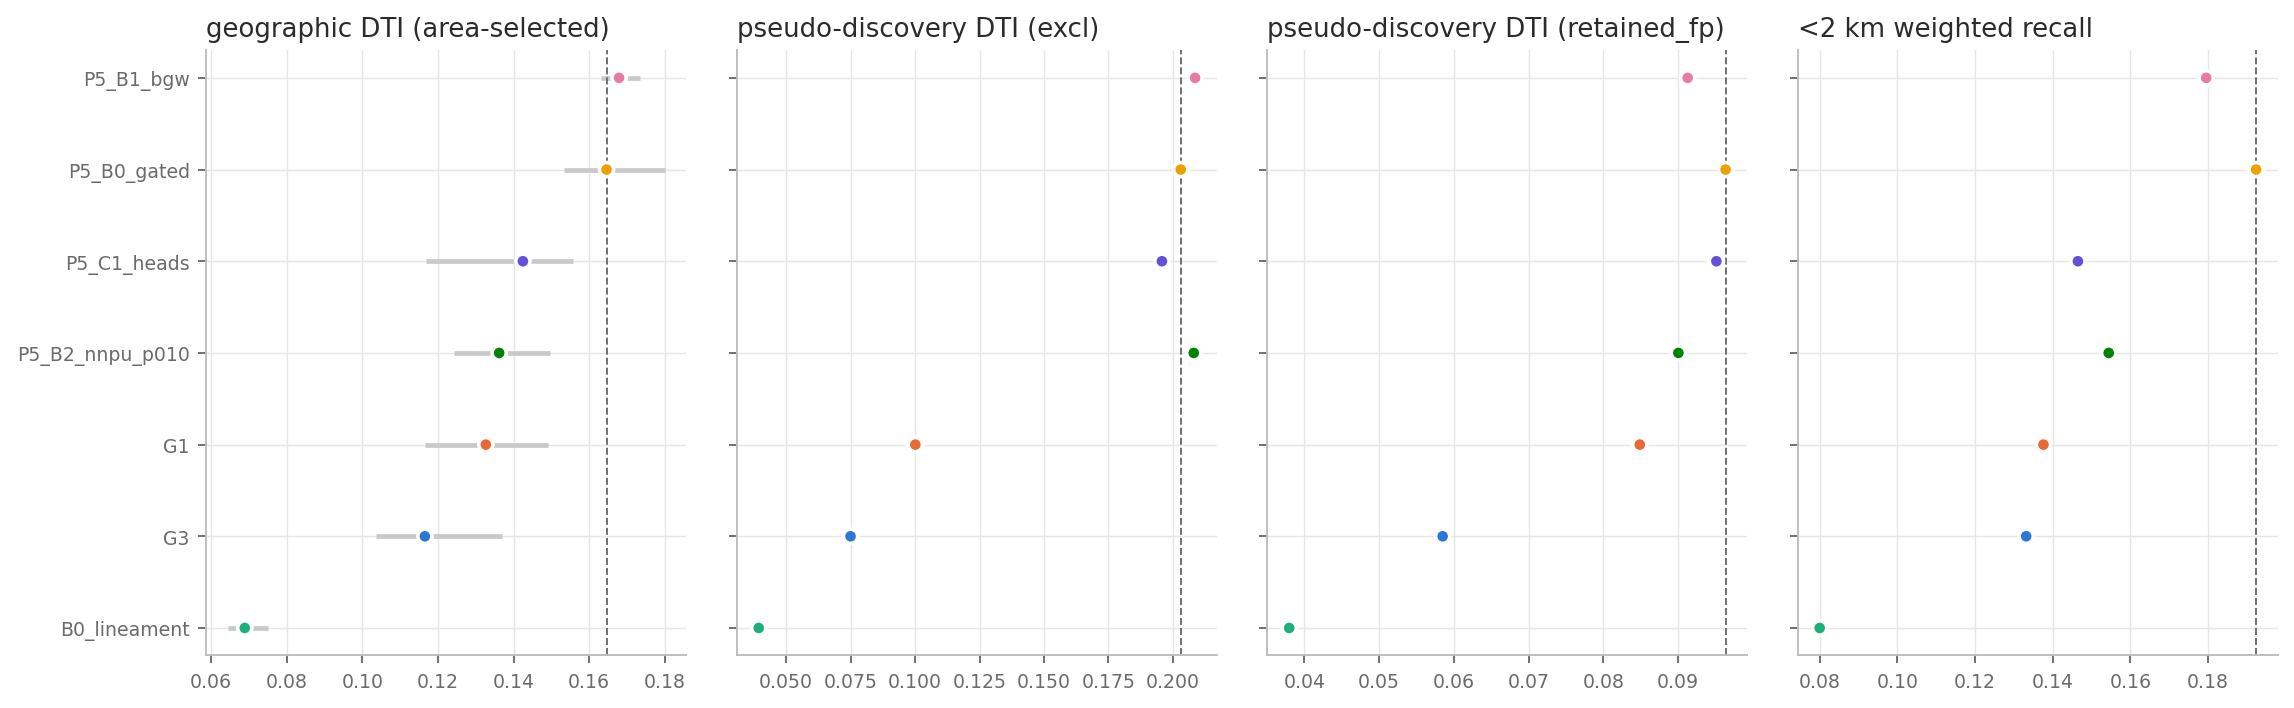

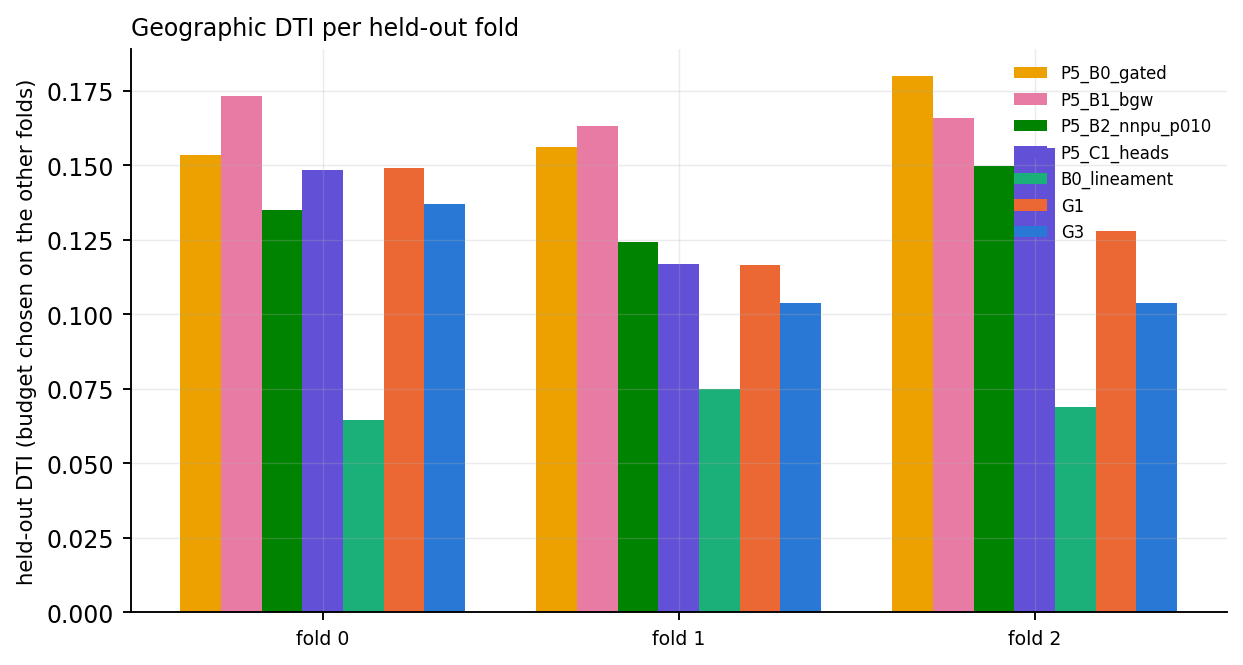

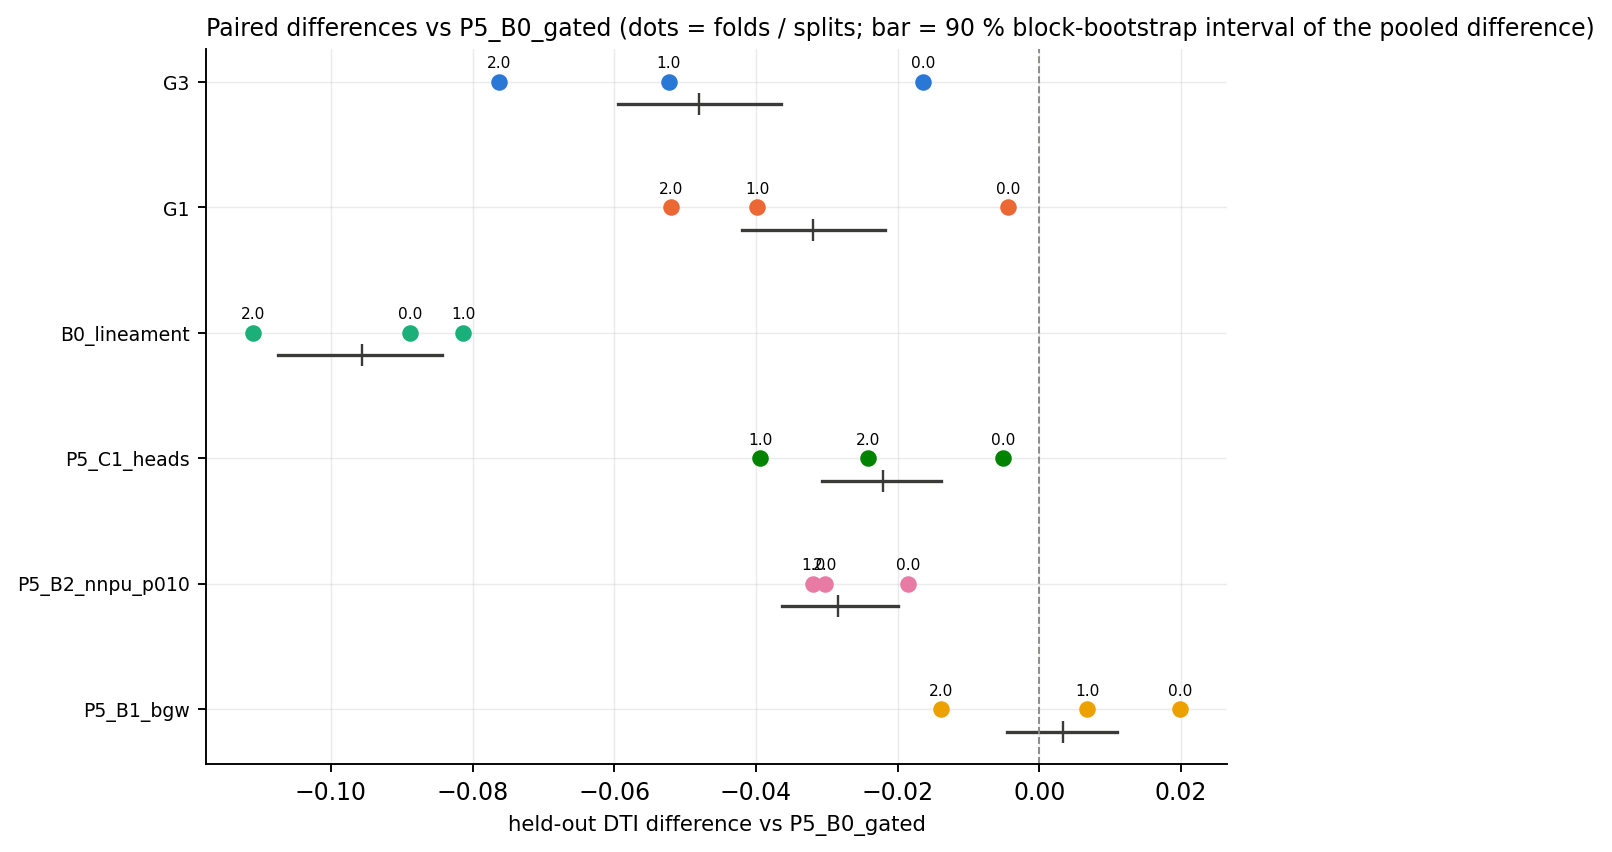

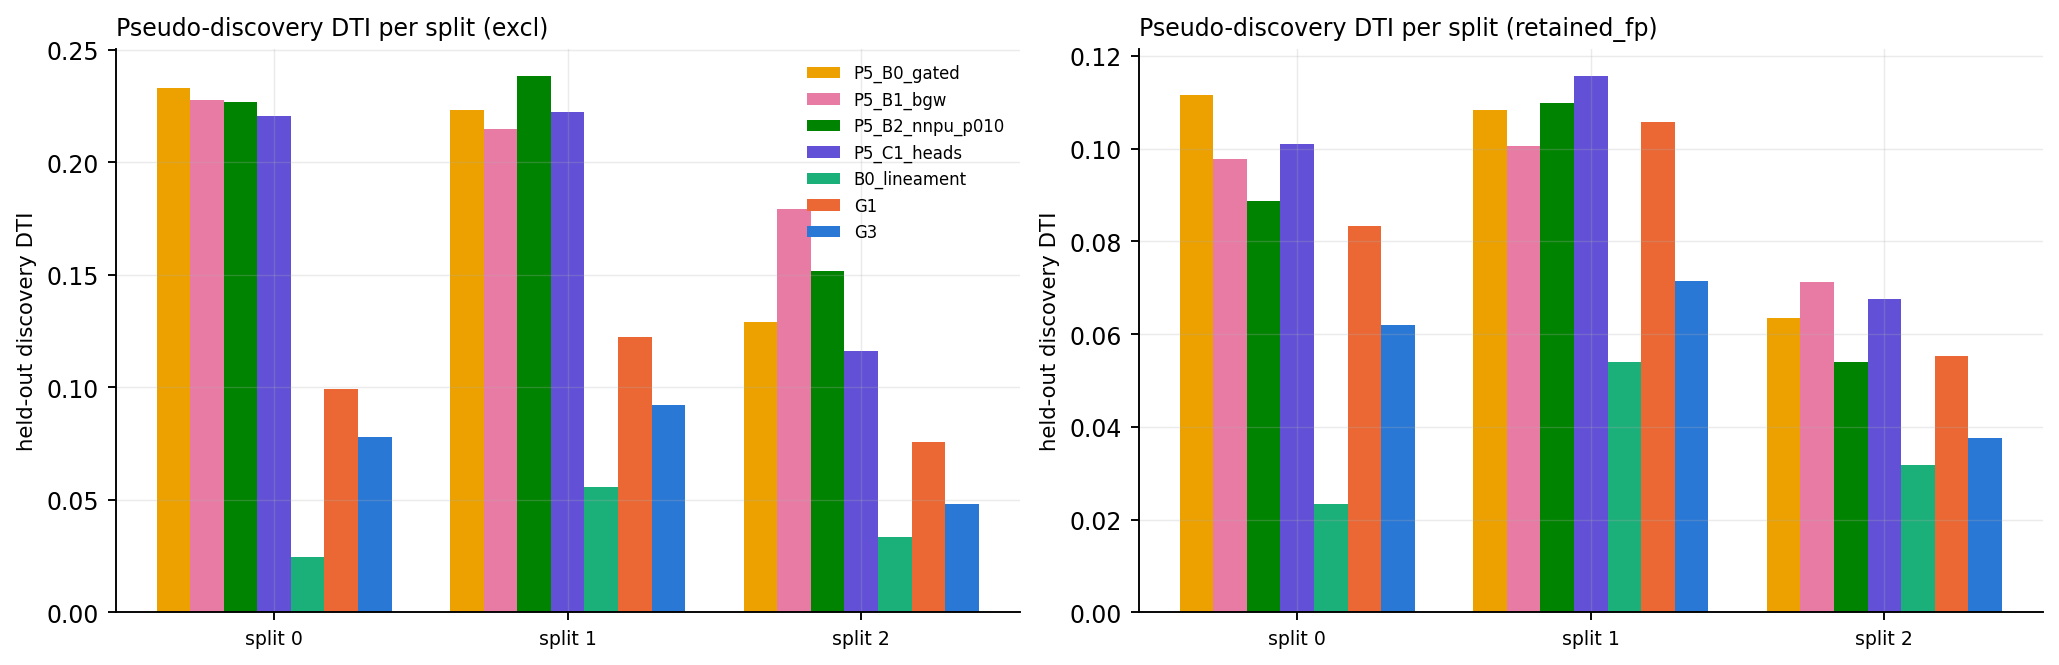

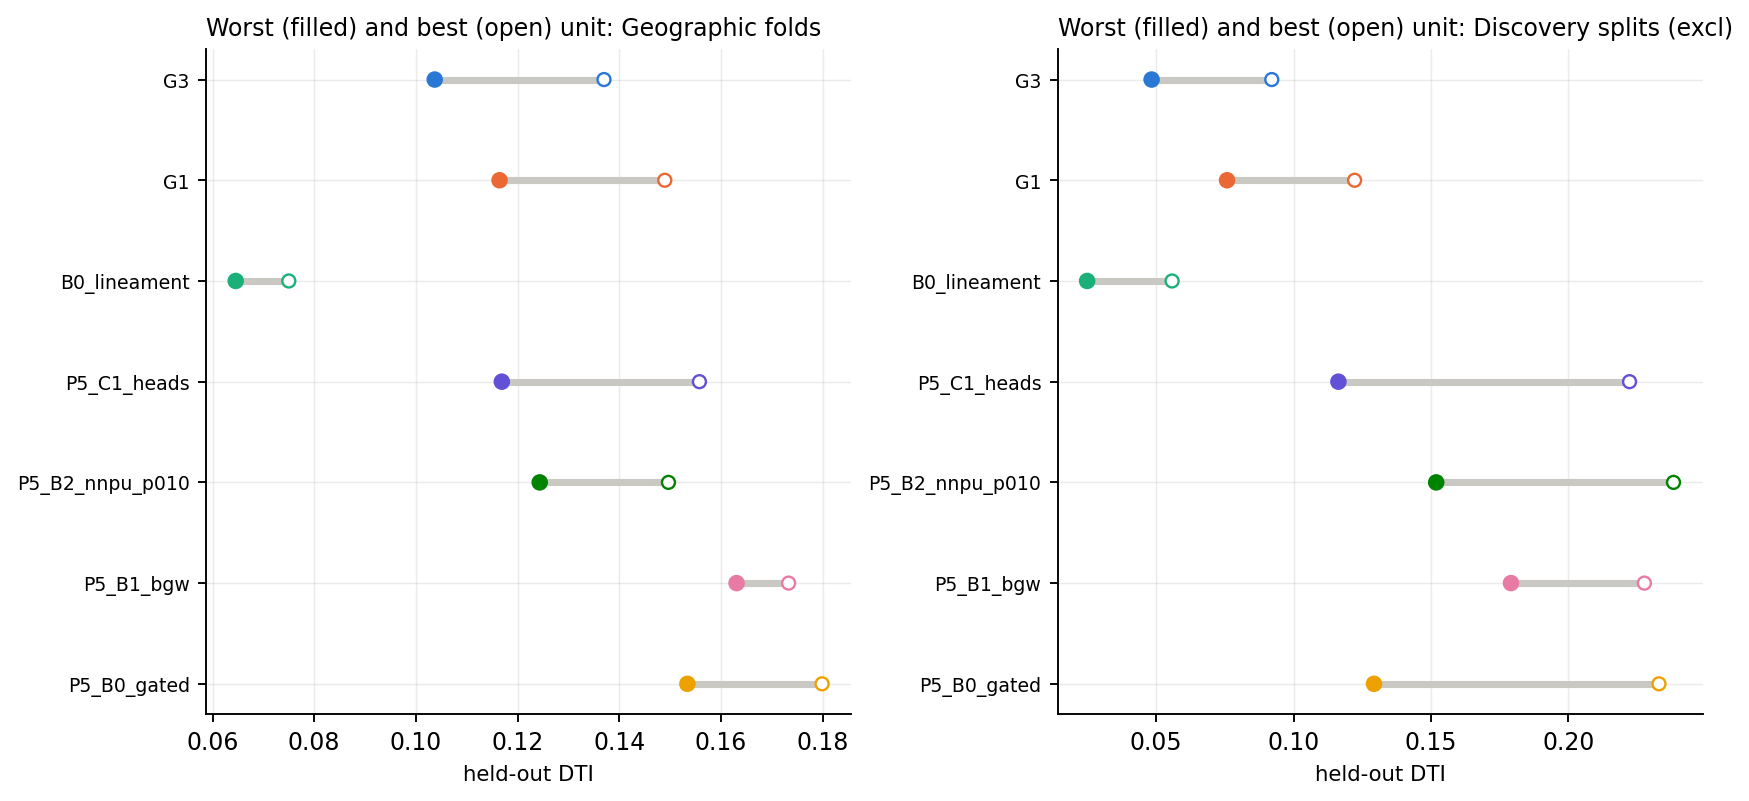

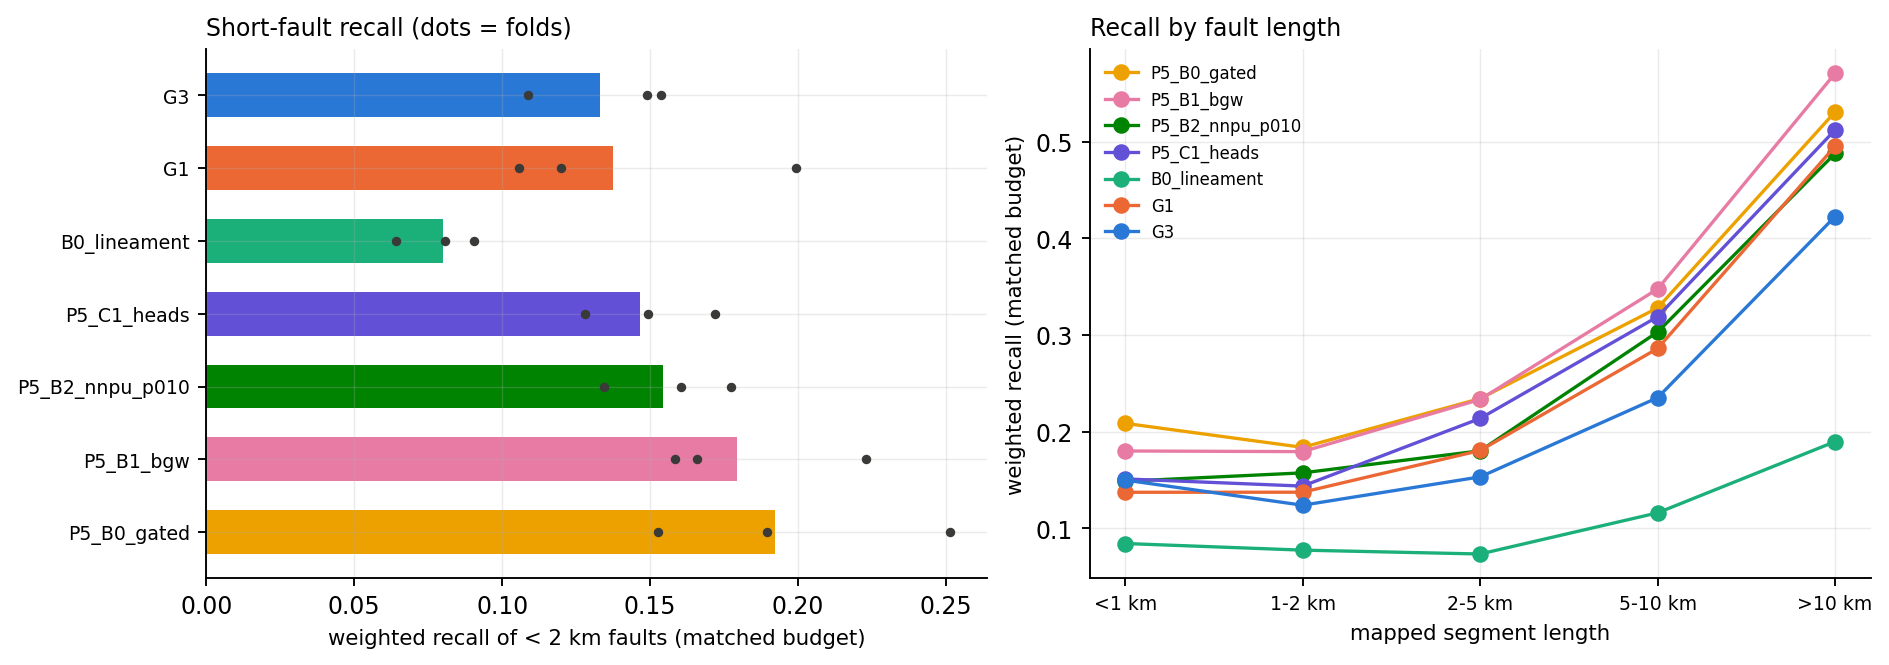

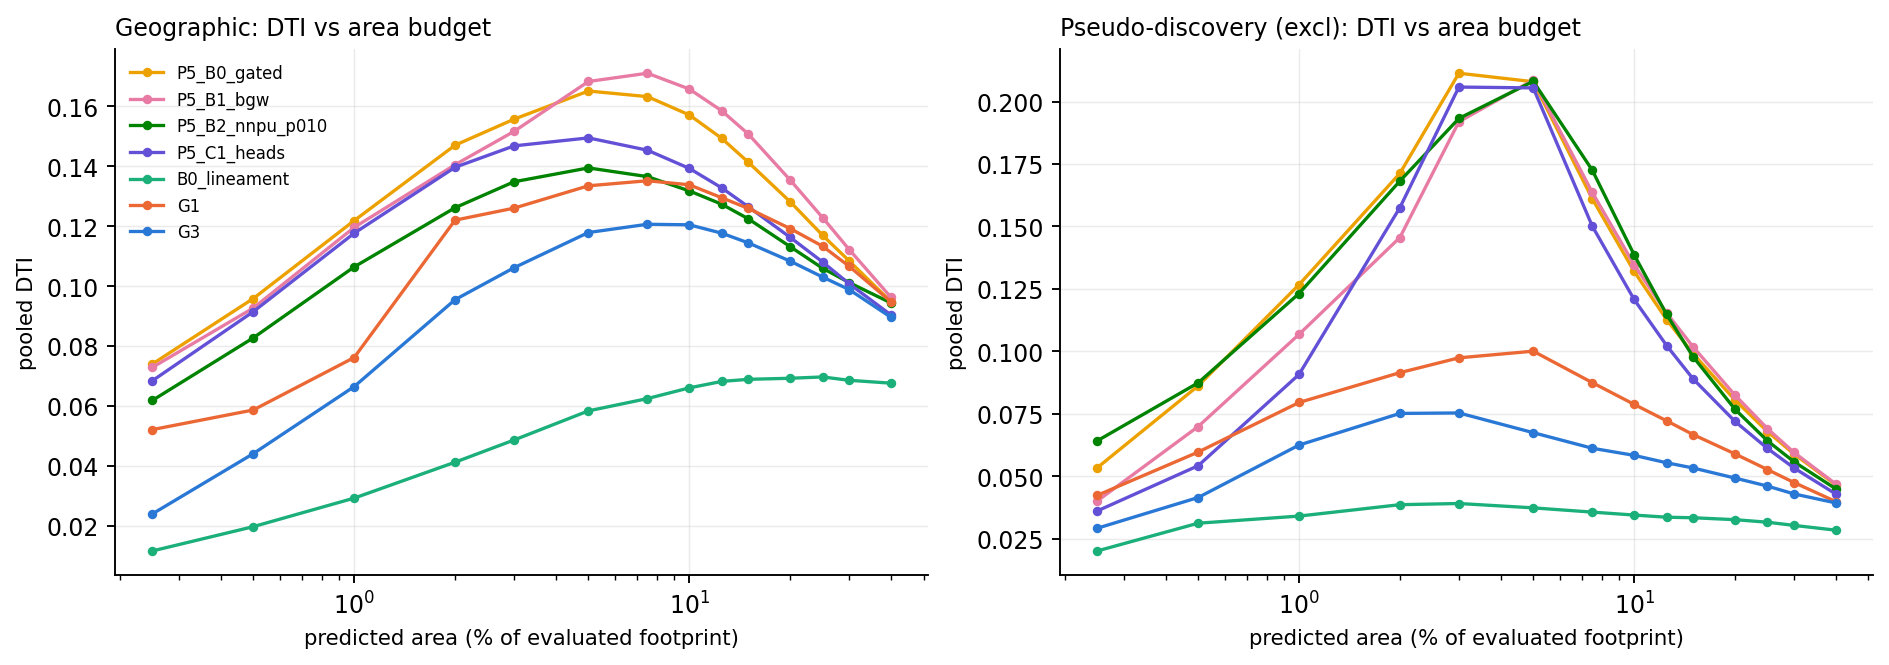

In [18]:
if M6_CONFIG['enabled']:
    m6.scorecard()
    paired = m6.paired()
    display(paired['reference_check'])               # previous review's numbers vs persisted / recomputed (never reconciled)
    mc = paired['model_comparison']
    display(mc[[c for c in ('model', 'geo_dti_area', 'geo_fold_min', 'geo_fold_std', 'disc_dti_excl',
                            'disc_dti_retained_fp', 'short_recall_w', 'geo_far_share_at_match') if c in mc]])
    display(paired['fold_metrics'].pivot_table(index='model', columns='fold', values='dti_heldout'))
    if len(paired['discovery_metrics']):
        display(paired['discovery_metrics'].pivot_table(index=['policy', 'model'], columns='split', values='dti_heldout'))
    display(paired['paired_summary'])
    display(paired['spatial_bootstrap'])
    show(['model_comparison', 'geo_dti_per_fold', 'paired_dti_differences', 'discovery_dti_per_split',
          'worst_fold_comparison', 'short_fault_recall_comparison', 'score_sensitivity'])

### M6.3 Area-budget and score calibration

For a fixed truth set, a binary per-fold top-*a* mask maximises DTI, so monotone recalibration cannot change it. `calibration_invariance` checks that raw and rank-normalised scores give identical masks. What can differ is how well a budget **transfers** between regions: `threshold_transfer` compares an absolute score cut with the per-fold area fraction, both chosen on the other folds.

[m6] calibration: computed in 164s
[sync out] 20 copied (2.5 MiB), 57 unchanged, 0s: ['reports/m6']


,model,family,label_free,dti_crossfit,dti_insample,optimism,fold_min,choice_on_grid_edge
0,P5_B0_gated,raw,True,0.114916,0.114916,0.000000,0.103642,False
1,P5_B0_gated,linear,False,0.120596,0.120998,0.000402,0.109835,True
2,P5_B0_gated,temperature,False,0.119501,0.119501,0.000000,0.108153,True
3,P5_B0_gated,isotonic,False,0.043295,0.043295,0.000000,0.039026,False
4,P5_B0_gated,hard_threshold,False,0.164560,0.165167,0.000607,0.153408,False
5,P5_B0_gated,rank,True,0.070158,0.070158,0.000000,0.062856,False
6,P5_B0_gated,robust_quantile,True,0.115383,0.115383,0.000000,0.104613,False
7,P5_B0_gated,hard_threshold_rank,False,0.164560,0.165167,0.000607,0.153408,False
8,P5_B1_bgw,raw,True,0.117896,0.117896,0.000000,0.098272,False
9,P5_B1_bgw,linear,False,0.112448,0.120227,0.007779,0.101185,True


,model,max_abs_diff,status
0,P5_B0_gated,0.0,IDENTICAL
1,P5_B1_bgw,0.0,IDENTICAL


,model,heldout_fold,selection_zones,policy,parameter,dev_dti,dev_area_frac,heldout_dti,heldout_area_frac,area_ratio_heldout_vs_dev,heldout_recall_w,heldout_recall300,heldout_far_share,uses_heldout_labels
0,P5_B0_gated,0,"1,2",absolute_threshold,"{""threshold"": 0.00037701180553995073}",0.169602,0.050,0.133340,0.147720,2.954402,0.492196,0.723152,0.702339,False
1,P5_B0_gated,0,"1,2",area_fraction,"{""target_frac"": 0.05}",0.171121,0.050,0.153408,0.050000,1.000004,0.269053,0.396910,0.627306,False
2,P5_B0_gated,1,"0,2",absolute_threshold,"{""threshold"": 0.00044051173608750105}",0.157456,0.050,0.142304,0.036294,0.725871,0.181185,0.268584,0.491752,False
3,P5_B0_gated,1,"0,2",area_fraction,"{""target_frac"": 0.05}",0.169529,0.050,0.156302,0.050003,1.000070,0.228615,0.357961,0.525614,False
4,P5_B0_gated,2,"0,1",absolute_threshold,"{""threshold"": 0.00046576772001571953}",0.146929,0.050,0.164961,0.020088,0.401768,0.183149,0.276476,0.389202,False
5,P5_B0_gated,2,"0,1",area_fraction,"{""target_frac"": 0.075}",0.154948,0.075,0.179918,0.075001,1.000008,0.366771,0.582635,0.603729,False
6,P5_B1_bgw,0,"1,2",absolute_threshold,"{""threshold"": 0.005881414283066988}",0.148557,0.050,0.155553,0.014999,0.299977,0.166663,0.234030,0.487304,False
7,P5_B1_bgw,0,"1,2",area_fraction,"{""target_frac"": 0.075}",0.169948,0.075,0.173332,0.075000,1.000000,0.388833,0.584701,0.627513,False
8,P5_B1_bgw,1,"0,2",absolute_threshold,"{""threshold"": 0.005812813062220812}",0.161302,0.050,0.116471,0.016432,0.328633,0.117644,0.176209,0.403600,False
9,P5_B1_bgw,1,"0,2",area_fraction,"{""target_frac"": 0.05}",0.170971,0.050,0.163087,0.050000,1.000005,0.239176,0.400354,0.521333,False


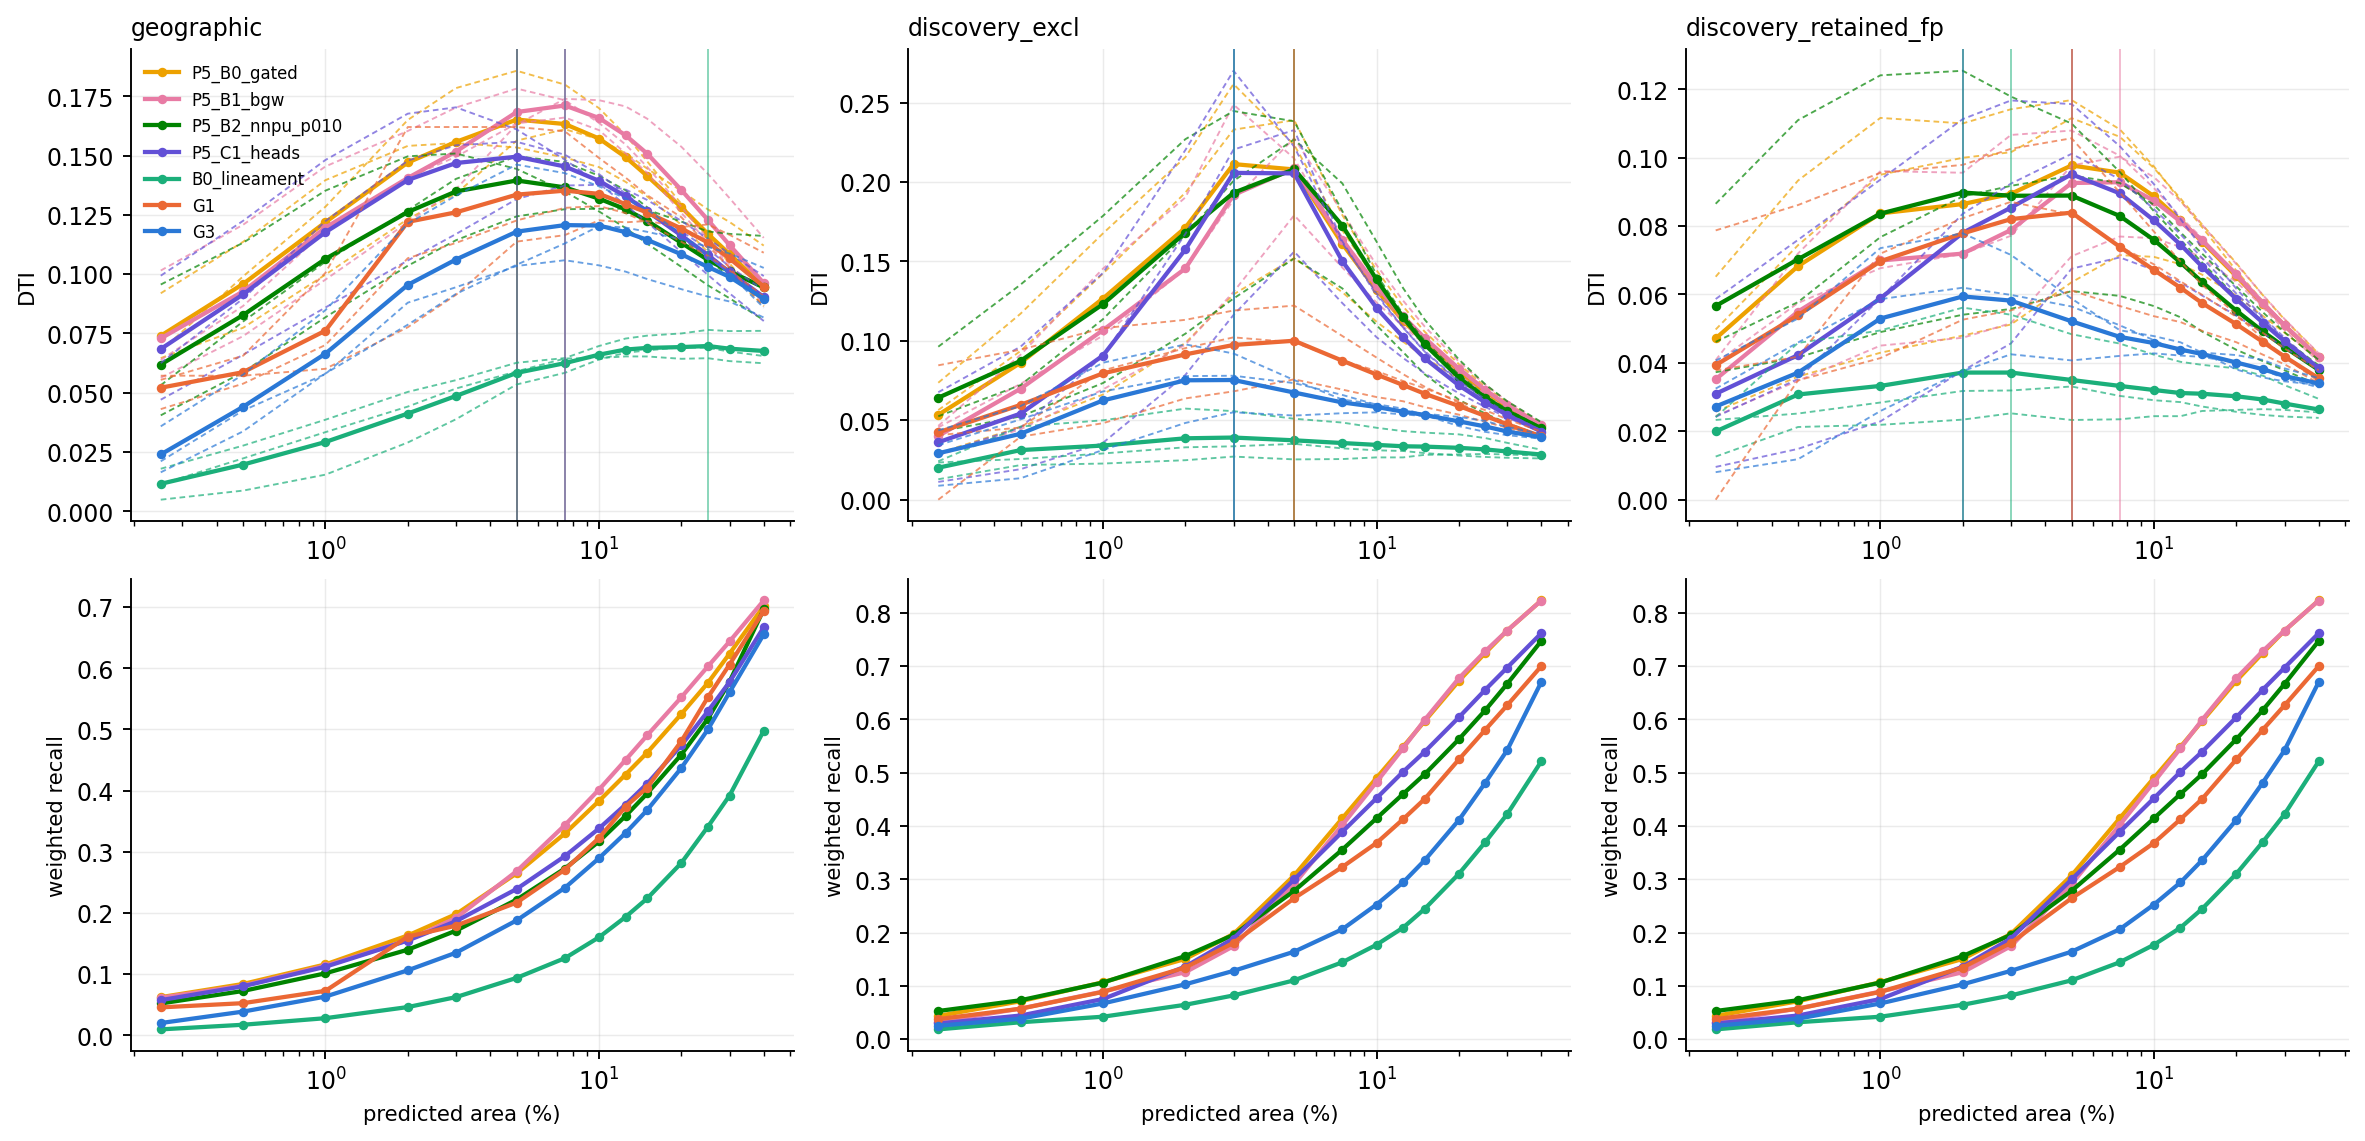

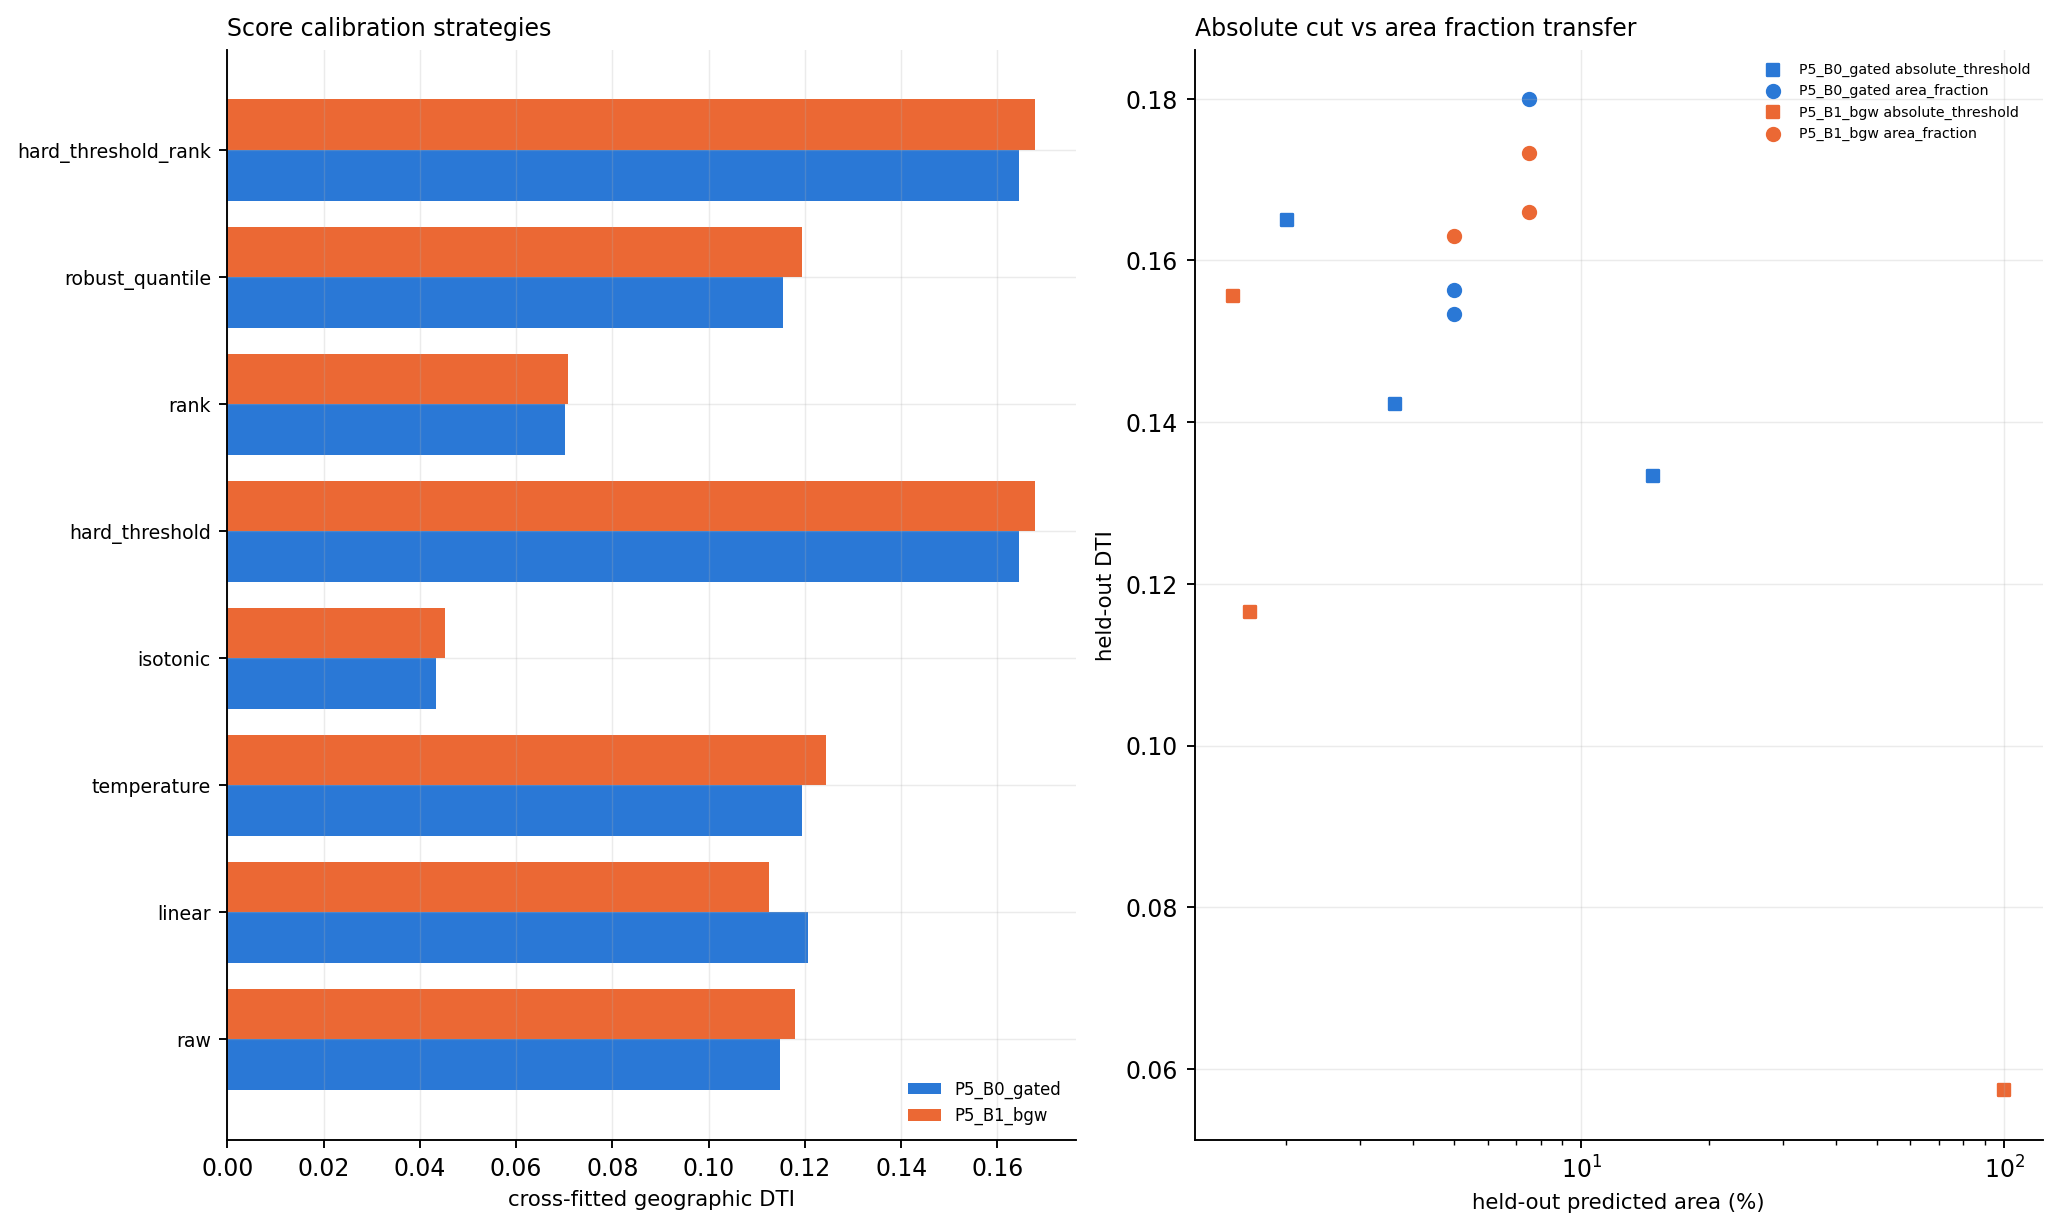

In [19]:
if M6_CONFIG['enabled'] and M6_CONFIG['run_calibration']:
    cal = m6.calibration()
    display(cal['calibration_results'][['model', 'family', 'label_free', 'dti_crossfit', 'dti_insample', 'optimism',
                                        'fold_min', 'choice_on_grid_edge']])
    display(cal['calibration_invariance'])
    display(cal['threshold_transfer'])
    show(['area_budget_curves', 'calibration_summary'])

### M6.4 Ensemble optimisation (nested)

B0 + B1 first: mean, rank mean, and weighted rank / robust blends *S = α R(S_B0) + (1 − α) R(S_B1)* with α on `[0, 0.25, 0.5, 0.75, 1]`. For held-out fold *k*, α and the area budget are chosen on the other folds, and refined around fold *k*'s own dev choice when it is interior. Discovery weights are chosen with the scored split's withheld systems removed (`geo_masked`) or on the other splits (`loso`). B2 / C1 are added only afterwards and must beat the best pair (`extension_justified`).

/content/GEMS/gems_bench/discovery/nested_selection.py:279: RuntimeWarning: Mean of empty slice
  cand.oof = np.where(v, np.nanmean(np.stack([maps[m] for m in members]), 0), np.nan).astype(np.float32)
/content/GEMS/gems_bench/discovery/nested_selection.py:323: RuntimeWarning: Mean of empty slice
  return np.where(ez, np.nanmean(np.stack(ps), 0), np.nan).astype(np.float32)


[m6] ensemble M6_ENS_B0_gated+B1_bgw_mean: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw_rankmean: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw_wrank: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw_wrobust: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw_wrank_loso: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010_wrank: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw+C1_heads_wrank: built
[m6] ensemble M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010+C1_heads_wrank: built
evaluate_models: 10 maps, 10 with discovery, 251s
[m6] ensembles: computed in 1799s
[sync out] 32 copied (35.3 MiB), 77 unchanged, 1s: ['reports/m6']


,candidate,members,method,normalisation,discovery_weights,geo_dti,geo_fold_min,disc_dti_excl,disc_dti_retained_fp,short_recall_w,delta_geo_dti_vs_P5_B0_gated,delta_geo_dti_vs_P5_B1_bgw,delta_disc_dti_excl_vs_P5_B0_gated,delta_disc_dti_excl_vs_P5_B1_bgw,geo_weights_per_fold,relative_inference_cost,extension_justified
0,P5_B0_gated,P5_B0_gated,single,none,NaN,0.164560,0.153408,0.203035,0.096351,0.192396,0.000000,-0.003316,0.000000,-0.005563,NaN,1.0,NaN
1,P5_B1_bgw,P5_B1_bgw,single,none,NaN,0.167877,0.163087,0.208598,0.091277,0.179544,0.003316,0.000000,0.005563,0.000000,NaN,1.0,NaN
2,P5_B2_nnpu_p010,P5_B2_nnpu_p010,single,none,NaN,0.136179,0.124361,0.208077,0.090033,0.154436,-0.028381,-0.031698,0.005042,-0.000521,NaN,1.0,NaN
3,P5_C1_heads,P5_C1_heads,single,none,NaN,0.142457,0.116906,0.195734,0.095121,0.146505,-0.022103,-0.025419,-0.007301,-0.012864,NaN,1.0,NaN
4,M6_ENS_B0_gated+B1_bgw_mean,P5_B0_gated+P5_B1_bgw,mean,none,fixed,0.160795,0.150807,0.253727,0.099443,0.162090,-0.003765,-0.007081,0.050692,0.045129,"{""0"": ""{\""P5_B0_gated\"": 0.5, \""P5_B1_bgw\"": 0...",2.0,NaN
5,M6_ENS_B0_gated+B1_bgw_rankmean,P5_B0_gated+P5_B1_bgw,rank_mean,rank,fixed,0.178309,0.166573,0.202933,0.108299,0.206433,0.013748,0.010432,-0.000102,-0.005665,"{""0"": ""{\""P5_B0_gated\"": 0.5, \""P5_B1_bgw\"": 0...",2.0,NaN
6,M6_ENS_B0_gated+B1_bgw_wrank,P5_B0_gated+P5_B1_bgw,weighted,rank,geo_masked,0.177374,0.166754,0.203592,0.107746,0.201516,0.012813,0.009497,0.000557,-0.005006,"{""0"": ""{\""P5_B0_gated\"": 0.5, \""P5_B1_bgw\"": 0...",2.0,NaN
7,M6_ENS_B0_gated+B1_bgw_wrobust,P5_B0_gated+P5_B1_bgw,weighted,robust,geo_masked,0.159006,0.149122,0.208598,0.091277,0.170289,-0.005555,-0.008871,0.005563,0.000000,"{""0"": ""{\""P5_B0_gated\"": 1.0, \""P5_B1_bgw\"": 0...",2.0,NaN
8,M6_ENS_B0_gated+B1_bgw_wrank_loso,P5_B0_gated+P5_B1_bgw,weighted,rank,loso,0.177374,0.166754,0.198624,0.092982,0.201516,0.012813,0.009497,-0.004411,-0.009974,"{""0"": ""{\""P5_B0_gated\"": 0.5, \""P5_B1_bgw\"": 0...",2.0,NaN
9,M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010_wrank,P5_B0_gated+P5_B1_bgw+P5_B2_nnpu_p010,weighted,rank,geo_masked,0.177343,0.166573,0.203592,0.107746,0.201139,0.012782,0.009466,0.000557,-0.005006,"{""0"": ""{\""P5_B0_gated\"": 0.5, \""P5_B1_bgw\"": 0...",3.0,False


,task,heldout_zone,selection_zones,all_zones,chosen,frac,heldout_labels_used_for_selection,candidate
0,geographic,0,"1,2","0,1,2","{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrank
1,geographic,1,"0,2","0,1,2","{""P5_B0_gated"": 0.4, ""P5_B1_bgw"": 0.6}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrank
2,geographic,2,"0,1","0,1,2","{""P5_B0_gated"": 0.2, ""P5_B1_bgw"": 0.8}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrank
3,geographic,0,"1,2","0,1,2","{""P5_B0_gated"": 1.0, ""P5_B1_bgw"": 0.0}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrobust
4,geographic,1,"0,2","0,1,2","{""P5_B0_gated"": 0.0, ""P5_B1_bgw"": 1.0}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrobust
5,geographic,2,"0,1","0,1,2","{""P5_B0_gated"": 0.0, ""P5_B1_bgw"": 1.0}",0.075,False,M6_ENS_B0_gated+B1_bgw_wrobust
6,geographic,0,"1,2","0,1,2","{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrank_loso
7,geographic,1,"0,2","0,1,2","{""P5_B0_gated"": 0.4, ""P5_B1_bgw"": 0.6}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrank_loso
8,geographic,2,"0,1","0,1,2","{""P5_B0_gated"": 0.2, ""P5_B1_bgw"": 0.8}",0.050,False,M6_ENS_B0_gated+B1_bgw_wrank_loso
9,geographic,0,"1,2","0,1,2","{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5, ""P5_B2_...",0.050,False,M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010_wrank


,split,method,selection_data,uses_split_labels,weights,candidate,dti_dev
0,0,fixed,none (equal weights),False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_mean,NaN
1,1,fixed,none (equal weights),False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_mean,NaN
2,2,fixed,none (equal weights),False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_mean,NaN
3,0,fixed,none (equal weights),False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_rankmean,NaN
4,1,fixed,none (equal weights),False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_rankmean,NaN
5,2,fixed,none (equal weights),False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_rankmean,NaN
6,0,geo_masked,"geographic OOF, split 0 withheld systems + ign...",False,"{""P5_B0_gated"": 0.5, ""P5_B1_bgw"": 0.5}",M6_ENS_B0_gated+B1_bgw_wrank,0.167843
7,1,geo_masked,"geographic OOF, split 1 withheld systems + ign...",False,"{""P5_B0_gated"": 0.25, ""P5_B1_bgw"": 0.75}",M6_ENS_B0_gated+B1_bgw_wrank,0.166542
8,2,geo_masked,"geographic OOF, split 2 withheld systems + ign...",False,"{""P5_B0_gated"": 0.25, ""P5_B1_bgw"": 0.75}",M6_ENS_B0_gated+B1_bgw_wrank,0.173439
9,0,geo_masked,"geographic OOF, split 0 withheld systems + ign...",False,"{""P5_B0_gated"": 0.0, ""P5_B1_bgw"": 1.0}",M6_ENS_B0_gated+B1_bgw_wrobust,0.159479


,model,reference,observed_delta,boot_median,boot_q05,boot_q95,p_delta_positive,n_boot,n_blocks,n_strata,note,task
0,M6_ENS_B0_gated+B1_bgw_mean,P5_B0_gated,-0.003765,-0.003657,-0.009921,0.001859,0.145,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
1,M6_ENS_B0_gated+B1_bgw_mean,P5_B1_bgw,-0.007081,-0.006993,-0.010835,-0.003421,0.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
2,M6_ENS_B0_gated+B1_bgw_rankmean,P5_B0_gated,0.013748,0.013677,0.008011,0.018812,1.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
3,M6_ENS_B0_gated+B1_bgw_rankmean,P5_B1_bgw,0.010432,0.010497,0.004986,0.015654,1.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
4,M6_ENS_B0_gated+B1_bgw_wrank,P5_B0_gated,0.012813,0.012707,0.006319,0.018645,1.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
5,M6_ENS_B0_gated+B1_bgw_wrank,P5_B1_bgw,0.009497,0.009563,0.004313,0.014135,1.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
6,M6_ENS_B0_gated+B1_bgw_wrobust,P5_B0_gated,-0.005555,-0.005664,-0.011455,0.000532,0.062,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
7,M6_ENS_B0_gated+B1_bgw_wrobust,P5_B1_bgw,-0.008871,-0.008809,-0.012681,-0.004844,0.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
8,M6_ENS_B0_gated+B1_bgw_wrank_loso,P5_B0_gated,0.012813,0.012707,0.006319,0.018645,1.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic
9,M6_ENS_B0_gated+B1_bgw_wrank_loso,P5_B1_bgw,0.009497,0.009563,0.004313,0.014135,1.000,1000,162,3,spatial-block bootstrap at the cross-fitted op...,geographic


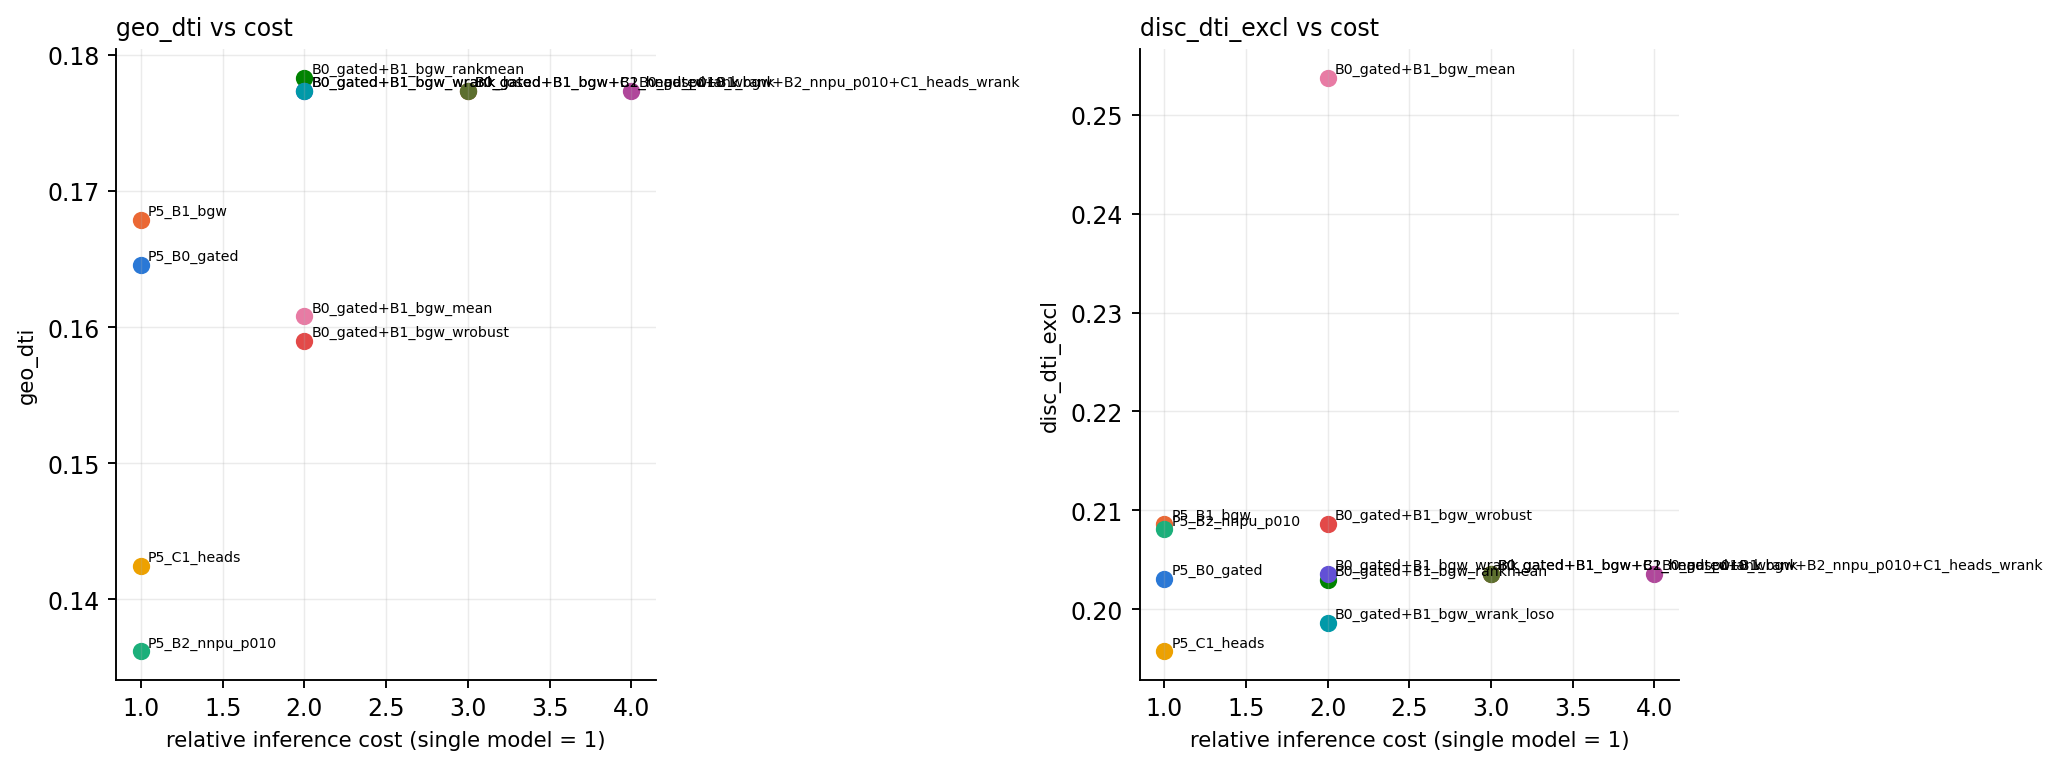

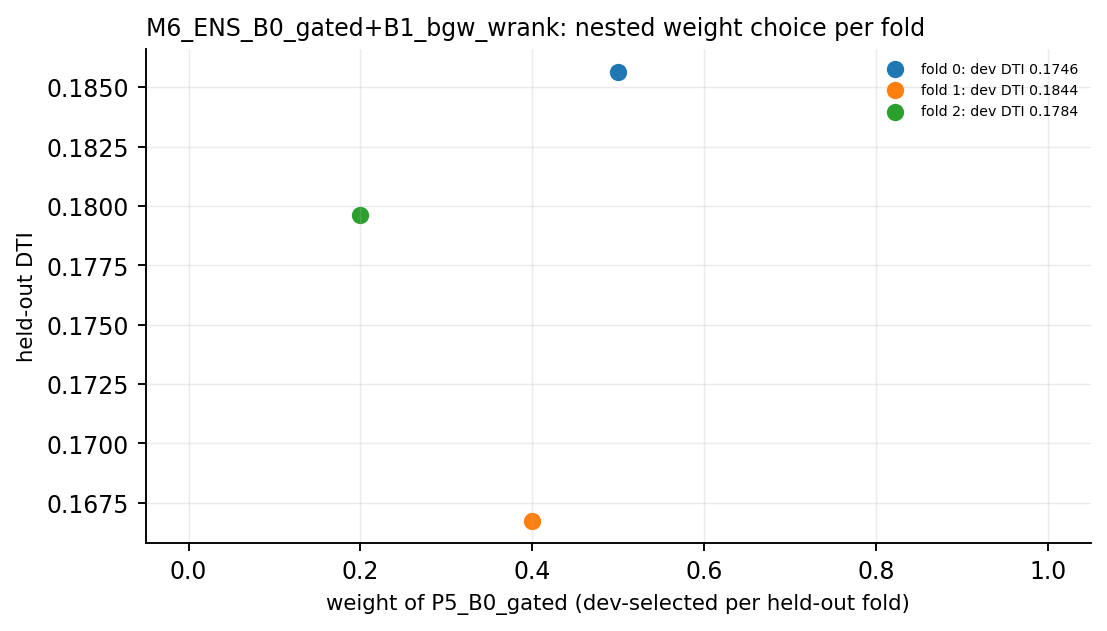

In [20]:
if M6_CONFIG['enabled'] and M6_CONFIG['run_ensemble']:
    ens = m6.ensembles()
    ec = ens['candidates']
    b0, b1 = m6.pair
    display(ec[[c for c in ('candidate', 'members', 'method', 'normalisation', 'discovery_weights', 'geo_dti',
                            'geo_fold_min', 'disc_dti_excl', 'disc_dti_retained_fp', 'short_recall_w',
                            f'delta_geo_dti_vs_{b0}', f'delta_geo_dti_vs_{b1}', f'delta_disc_dti_excl_vs_{b0}',
                            f'delta_disc_dti_excl_vs_{b1}', 'geo_weights_per_fold', 'relative_inference_cost',
                            'extension_justified') if c in ec]])
    display(m6.ws.load_table('ensemble_index_audit'))      # selection zones never include the scored zone
    display(m6.ws.load_table('ensemble_selection_discovery'))
    display(ens['bootstrap'])
    show(['score_vs_cost', 'ensemble_weight_choices'])

### M6.5 Complementarity and geological errors

At identical area budgets: score correlation, IoU and disagreement area. Mapped segments are classed as recovered by both / B0 only / B1 only / neither, by length, fold, strike, geophysical contrast, junction context and distance to the fold edge. Withheld systems are classed the same way, and false-positive exposure is shown by distance to mapped faults. Case-study panels (geophysics, mapped faults, B0, B1, ensemble, agreement) share extent and scale and are regenerated from `case_study_windows.csv`. Agreement far from mapped faults is an **unmapped prediction**, not a confirmed fault.

In [24]:
import numpy as np
import pandas as pd
from gems_bench.evaluation import geological_errors as GE

def safe_miss_attribution(cls):
    miss = cls.loc[cls["class"] == "neither"]
    hit = cls.loc[cls["class"] == "both"]

    rows = []

    attrs = dict(GE.ATTRIBUTE_HYPOTHESES)
    attrs.update({
        c: "low geophysical contrast along the trace"
        for c in cls.columns
        if c.startswith("contrast_")
    })

    for c, why in attrs.items():
        if c not in cls.columns:
            continue

        x = pd.to_numeric(miss[c], errors="coerce")
        y = pd.to_numeric(hit[c], errors="coerce")

        x = x.replace([np.inf, -np.inf], np.nan).dropna()
        y = y.replace([np.inf, -np.inf], np.nan).dropna()

        if x.empty or y.empty:
            continue

        a = float(x.median())
        b = float(y.median())

        rows.append({
            "attribute": c,
            "hypothesis": why,
            "median_missed_by_both": a,
            "median_recovered_by_both": b,
            "ratio_missed_over_recovered": a / b if b != 0 else np.nan,
            "n_missed": len(x),
            "n_recovered": len(y),
            "note": "Descriptive comparison; not causal",
        })

    return pd.DataFrame(rows)

# Patch the imported function for this Colab session
GE.miss_attribution = safe_miss_attribution

print("Patched geological_errors.miss_attribution")

Patched geological_errors.miss_attribution


[m6] complementarity: computed in 52s
[sync out] 53 copied (7.8 MiB), 109 unchanged, 1s: ['reports/m6']


,model_a,model_b,budget,zone,pearson,spearman,area_a_km2,area_b_km2,iou,overlap_a_in_b,a_only_km2,b_only_km2,both_km2,a_only_far_km2,b_only_far_km2,both_far_km2
0,P5_B0_gated,P5_B1_bgw,0.01,all,0.362187,-0.050438,516.60,516.60,0.211666,0.349381,336.11,336.11,180.49,159.98,155.58,40.03
4,P5_B0_gated,P5_B1_bgw,0.02,all,0.362187,-0.050438,1033.18,1033.18,0.202743,0.337134,684.86,684.86,348.32,380.31,364.83,105.29
8,P5_B0_gated,P5_B1_bgw,0.05,all,0.362187,-0.050438,2582.99,2582.94,0.170927,0.291948,1828.89,1828.84,754.10,1174.57,1077.28,300.76
12,P5_B0_gated,P5_B1_bgw,0.10,all,0.362187,-0.050438,5165.87,5165.87,0.148641,0.258812,3828.88,3828.88,1336.99,2680.09,2458.11,639.66


class,P5_B0_gated_only,P5_B1_bgw_only,both,neither
value,,,,
1-2,68.423968,67.254477,81.860721,842.861599
2-5,172.480693,138.389223,221.061254,1562.960957
5-10,64.124977,87.599871,298.407819,770.971007
<1,50.047518,40.716147,44.198990,358.111515
>10,12.159798,89.555149,318.543459,250.882869


class,P5_B0_gated_only,P5_B1_bgw_only,both,neither
value,,,,
0,92.251028,164.720895,356.278457,1061.513223
1,113.406115,83.229121,288.159027,1411.521580
2,161.579811,175.564850,319.634759,1312.753143


class,P5_B0_gated_only,P5_B1_bgw_only,both,neither
split,,,,
0,3,1,6,28
1,2,2,6,28
2,1,4,2,37


,attribute,hypothesis,median_missed_by_both,median_recovered_by_both,ratio_missed_over_recovered,n_missed,n_recovered,note
0,length_km,"short traces are harder (fewer pixels, below t...",1.531371,2.214214,0.691609,1716,250,Descriptive comparison; not causal
1,strike_share_other_folds,strikes rare in the training folds are missed ...,0.242834,0.300039,0.809342,1716,250,Descriptive comparison; not causal
2,local_density,isolated faults lack the context of dense faul...,0.064085,0.052618,1.217943,1716,250,Descriptive comparison; not causal
3,share_intersection,junction-rich traces are fragmented or merged,0.000000,0.000000,NaN,1716,250,Descriptive comparison; not causal
4,edge_km,faults near the fold-zone edge lose context at...,11.652837,8.119705,1.435131,1716,250,Descriptive comparison; not causal
5,contrast_mag_anom,low geophysical contrast along the trace,1.179935,1.082749,1.089759,1716,250,Descriptive comparison; not causal
6,contrast_iso_grav_anom_slope,low geophysical contrast along the trace,1.106435,1.258080,0.879463,1716,250,Descriptive comparison; not causal


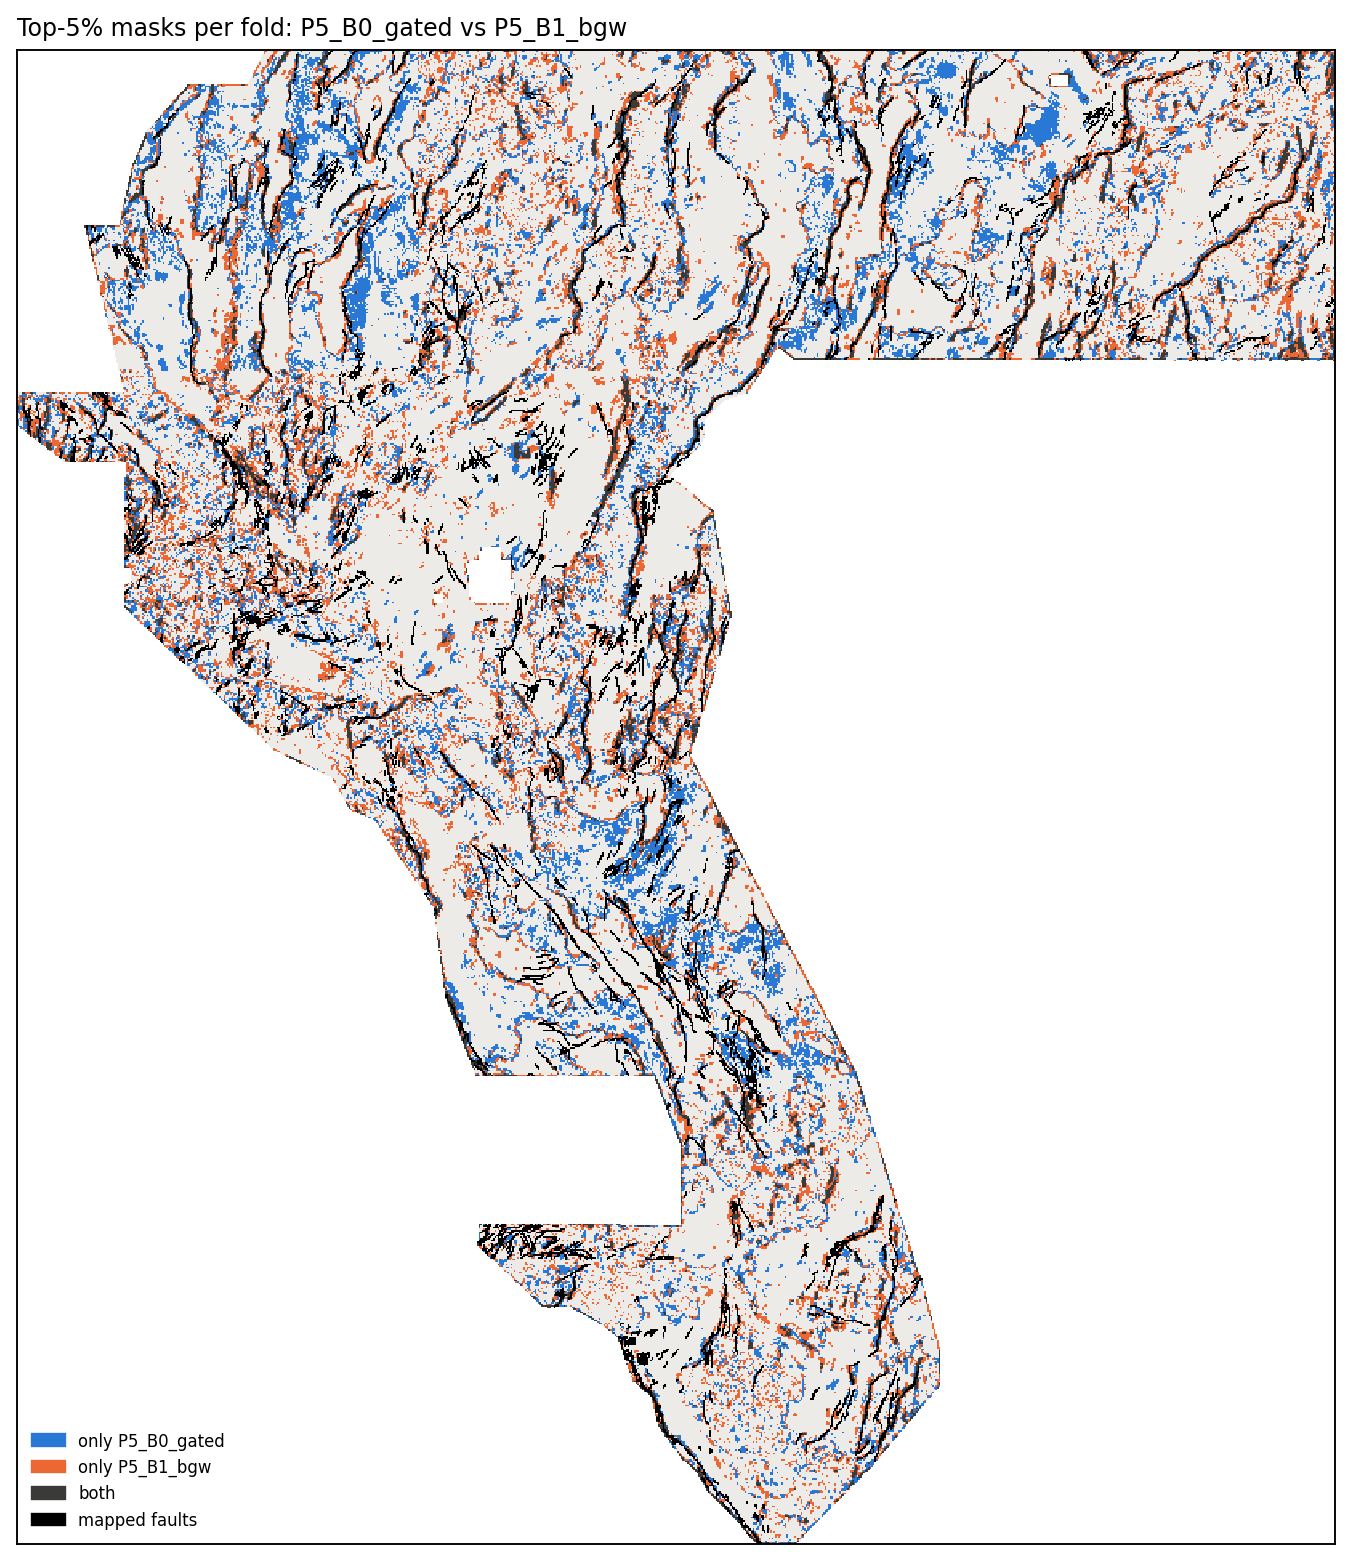

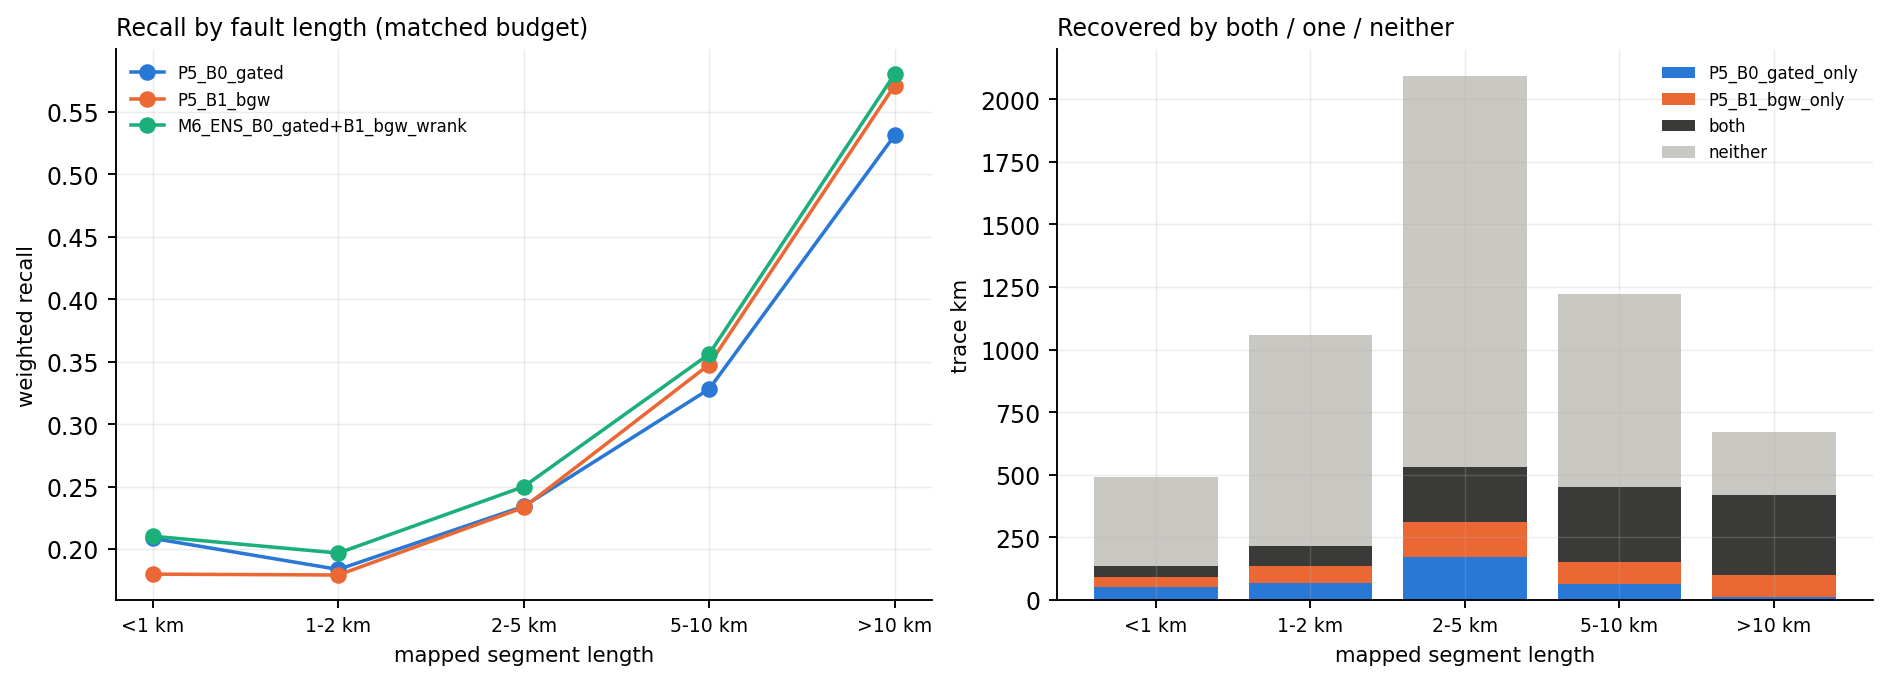

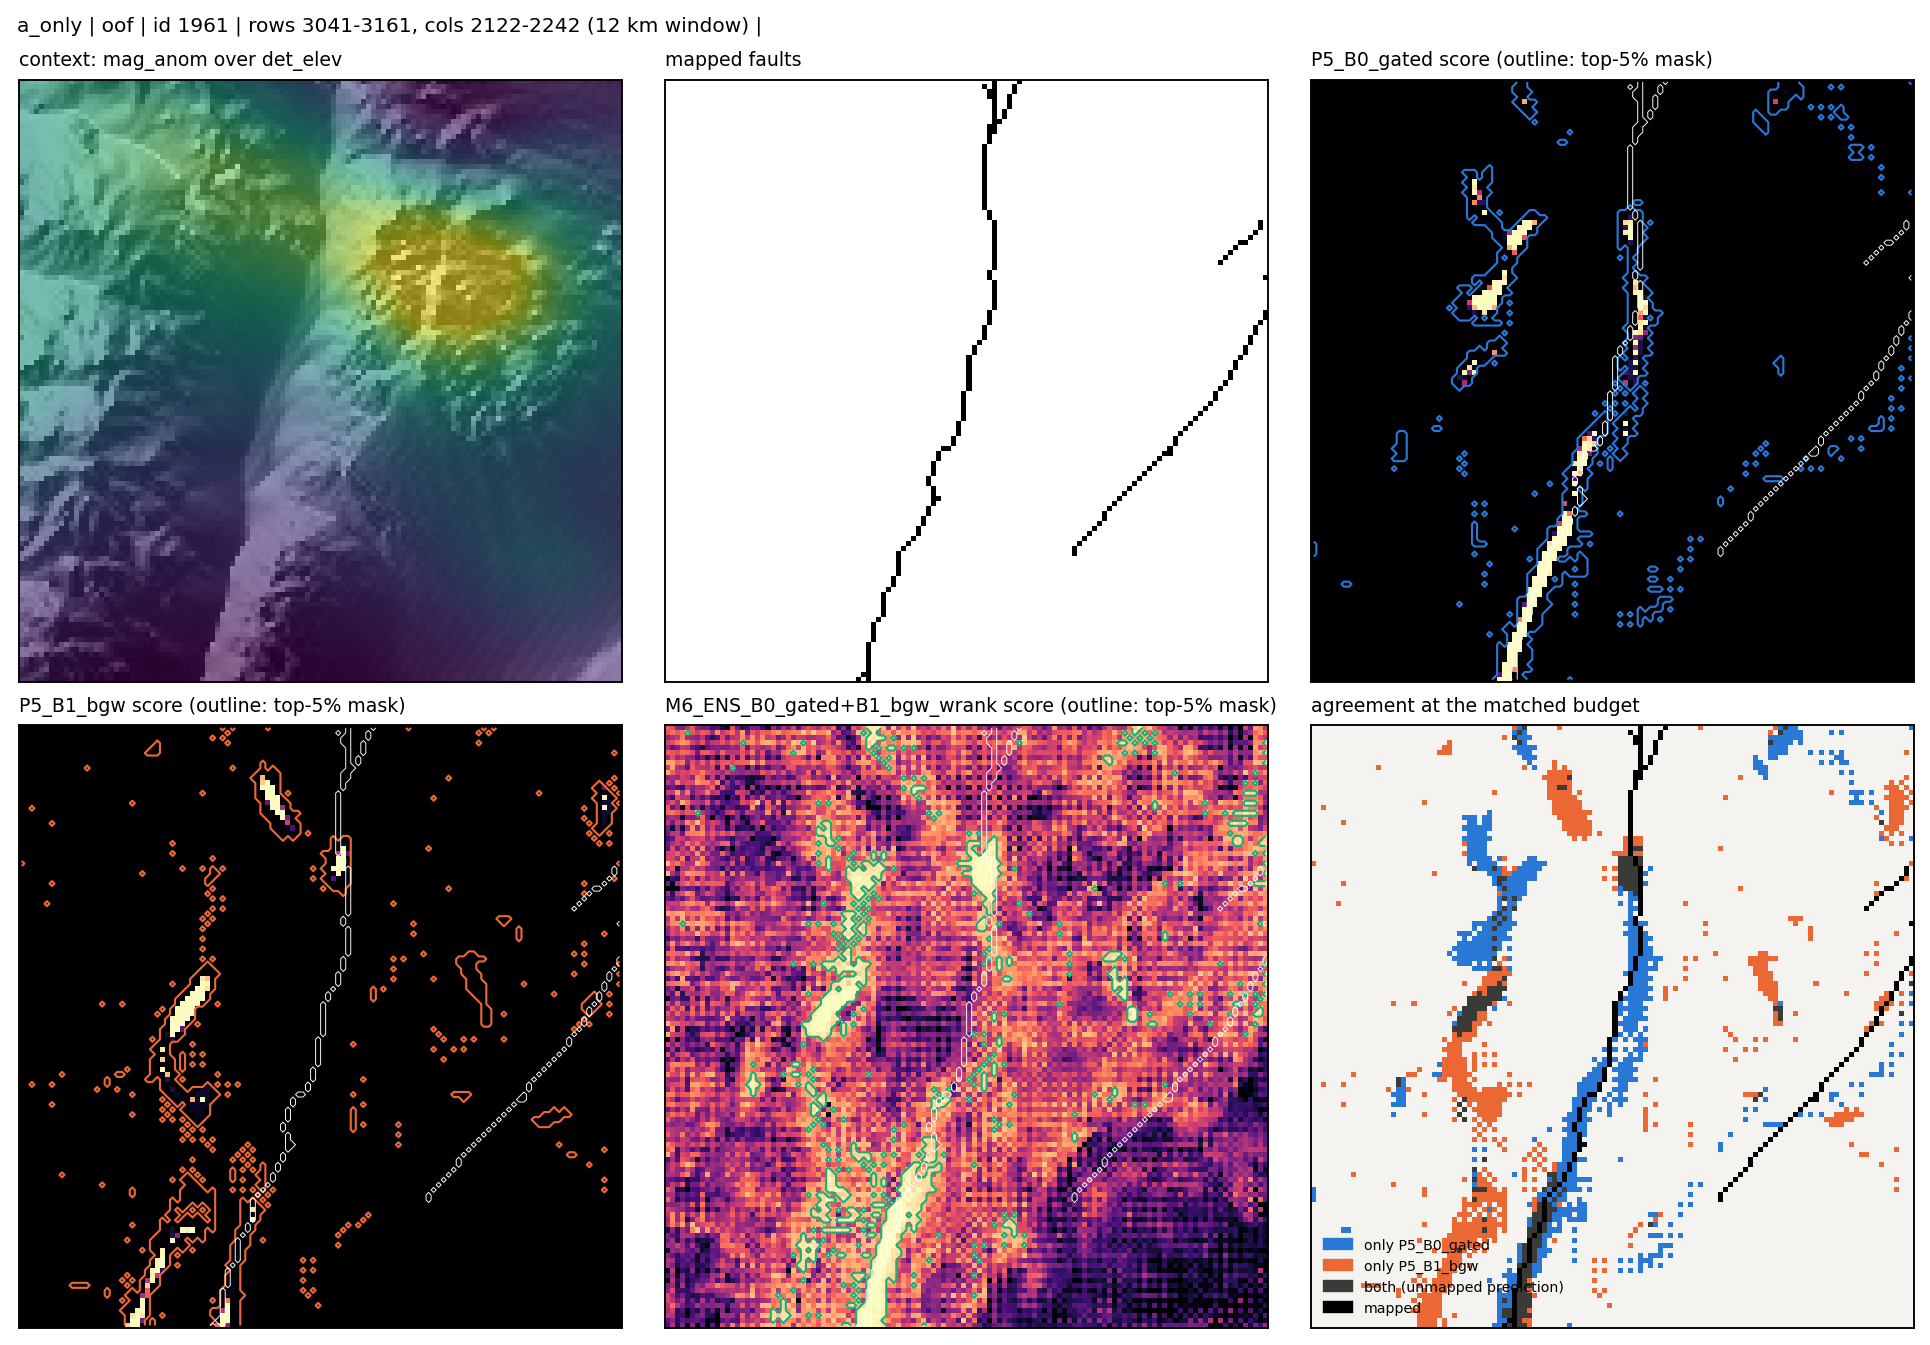

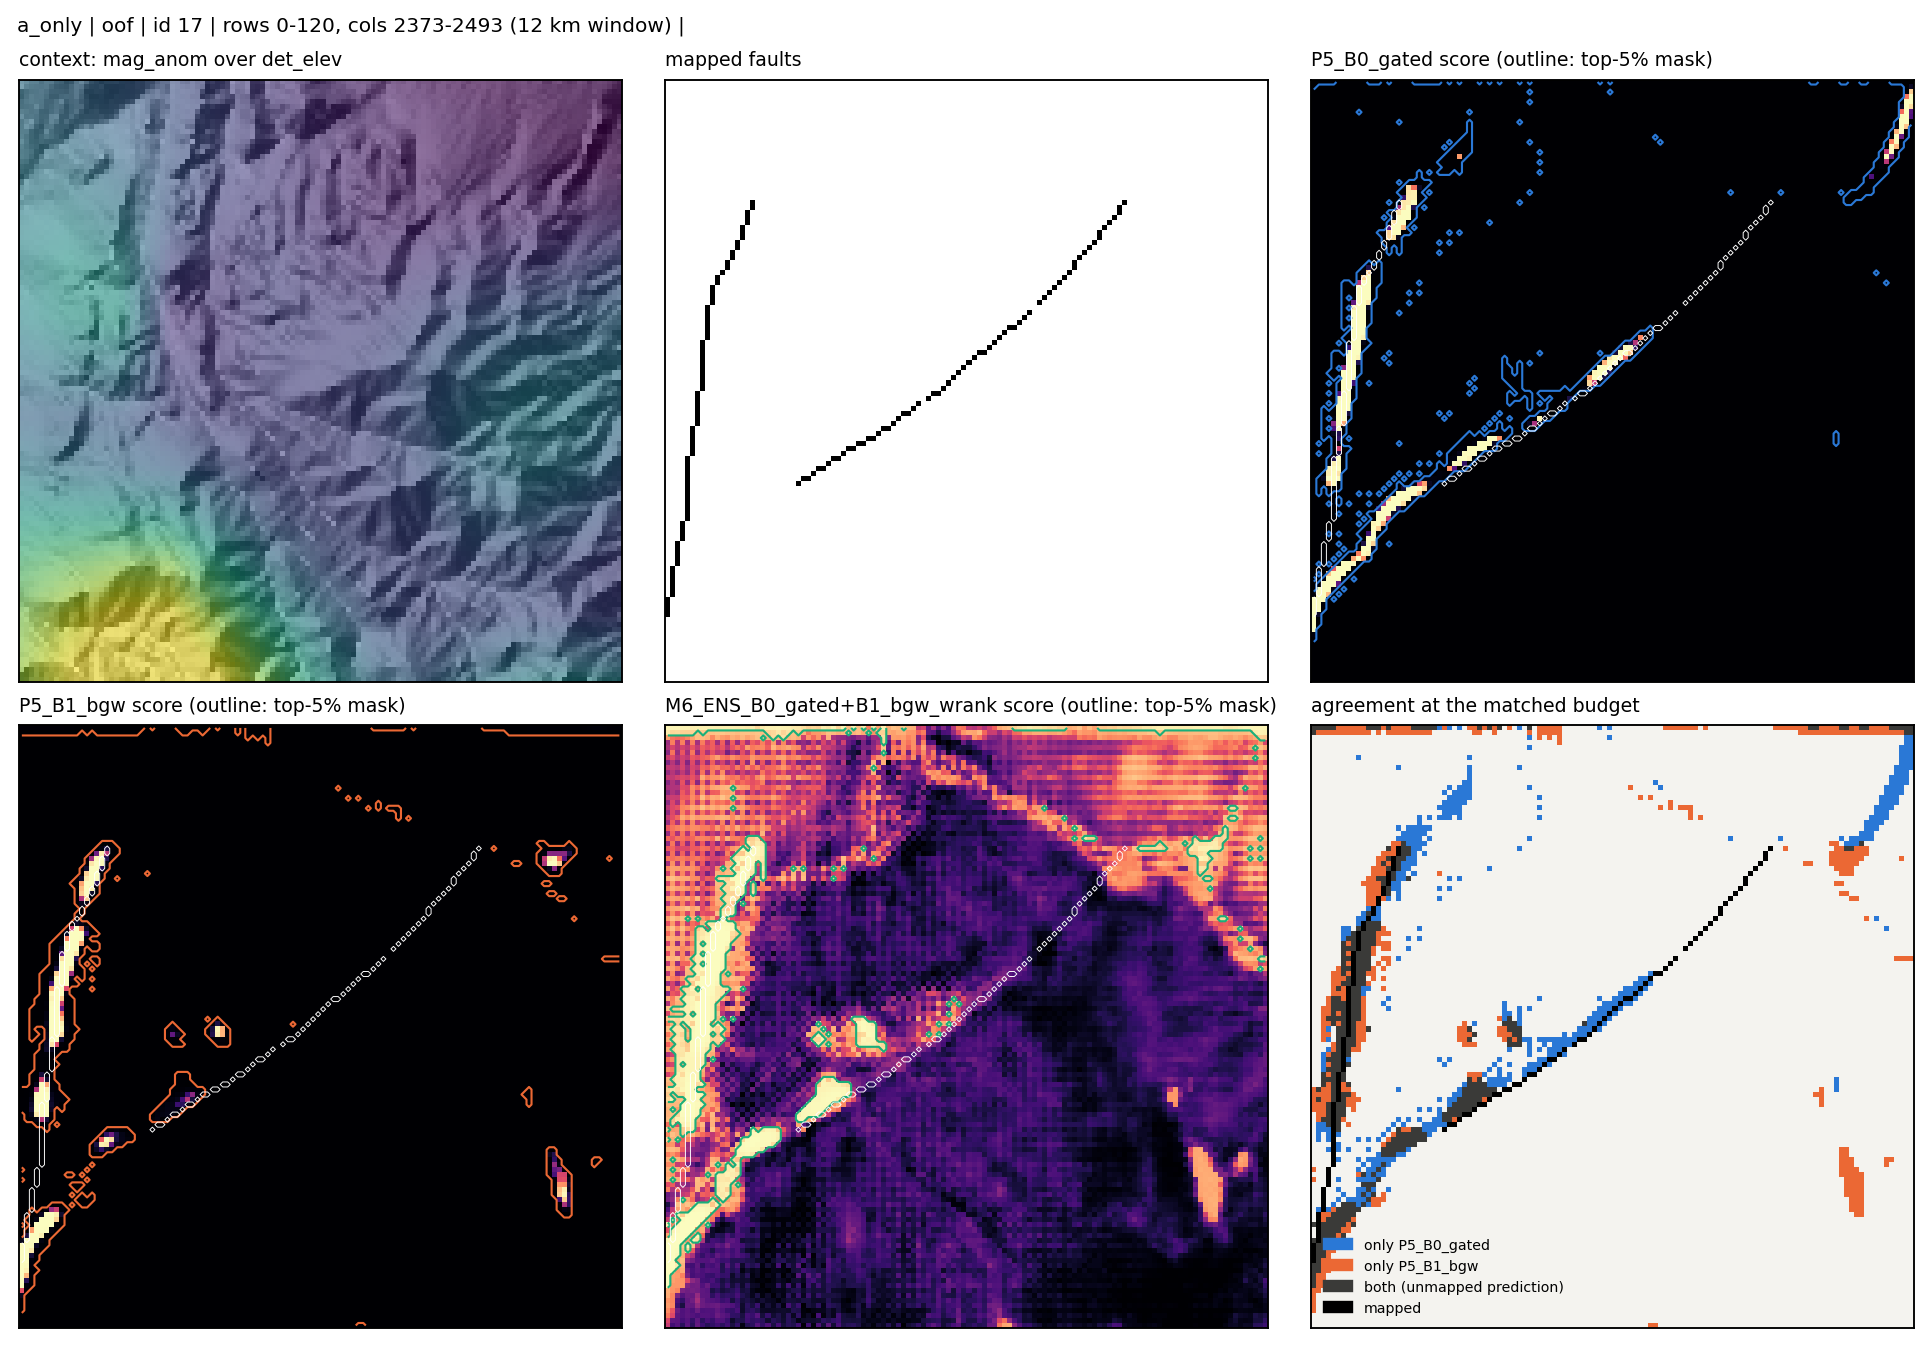

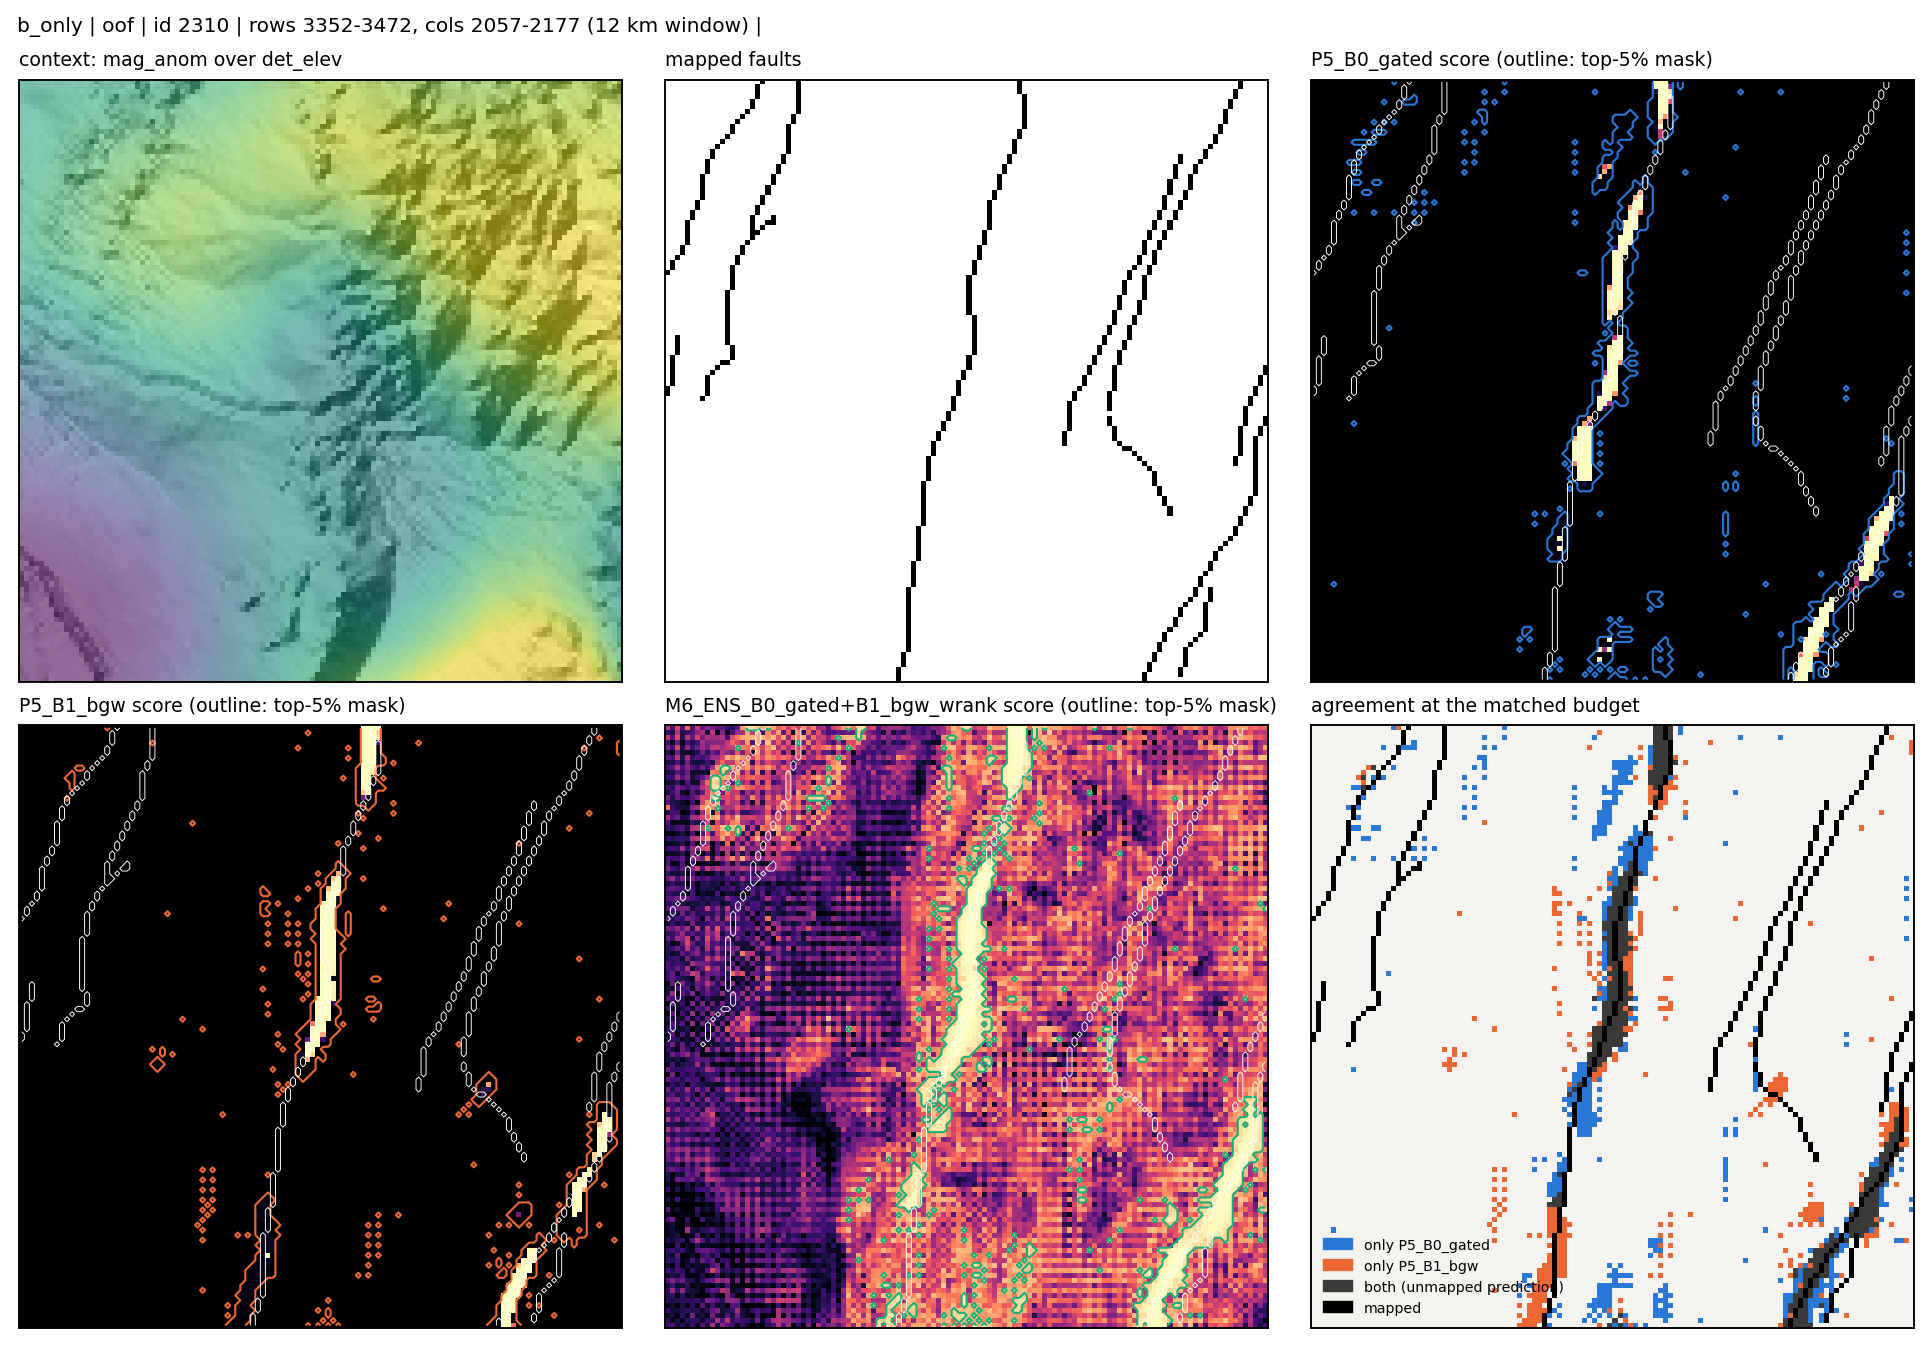

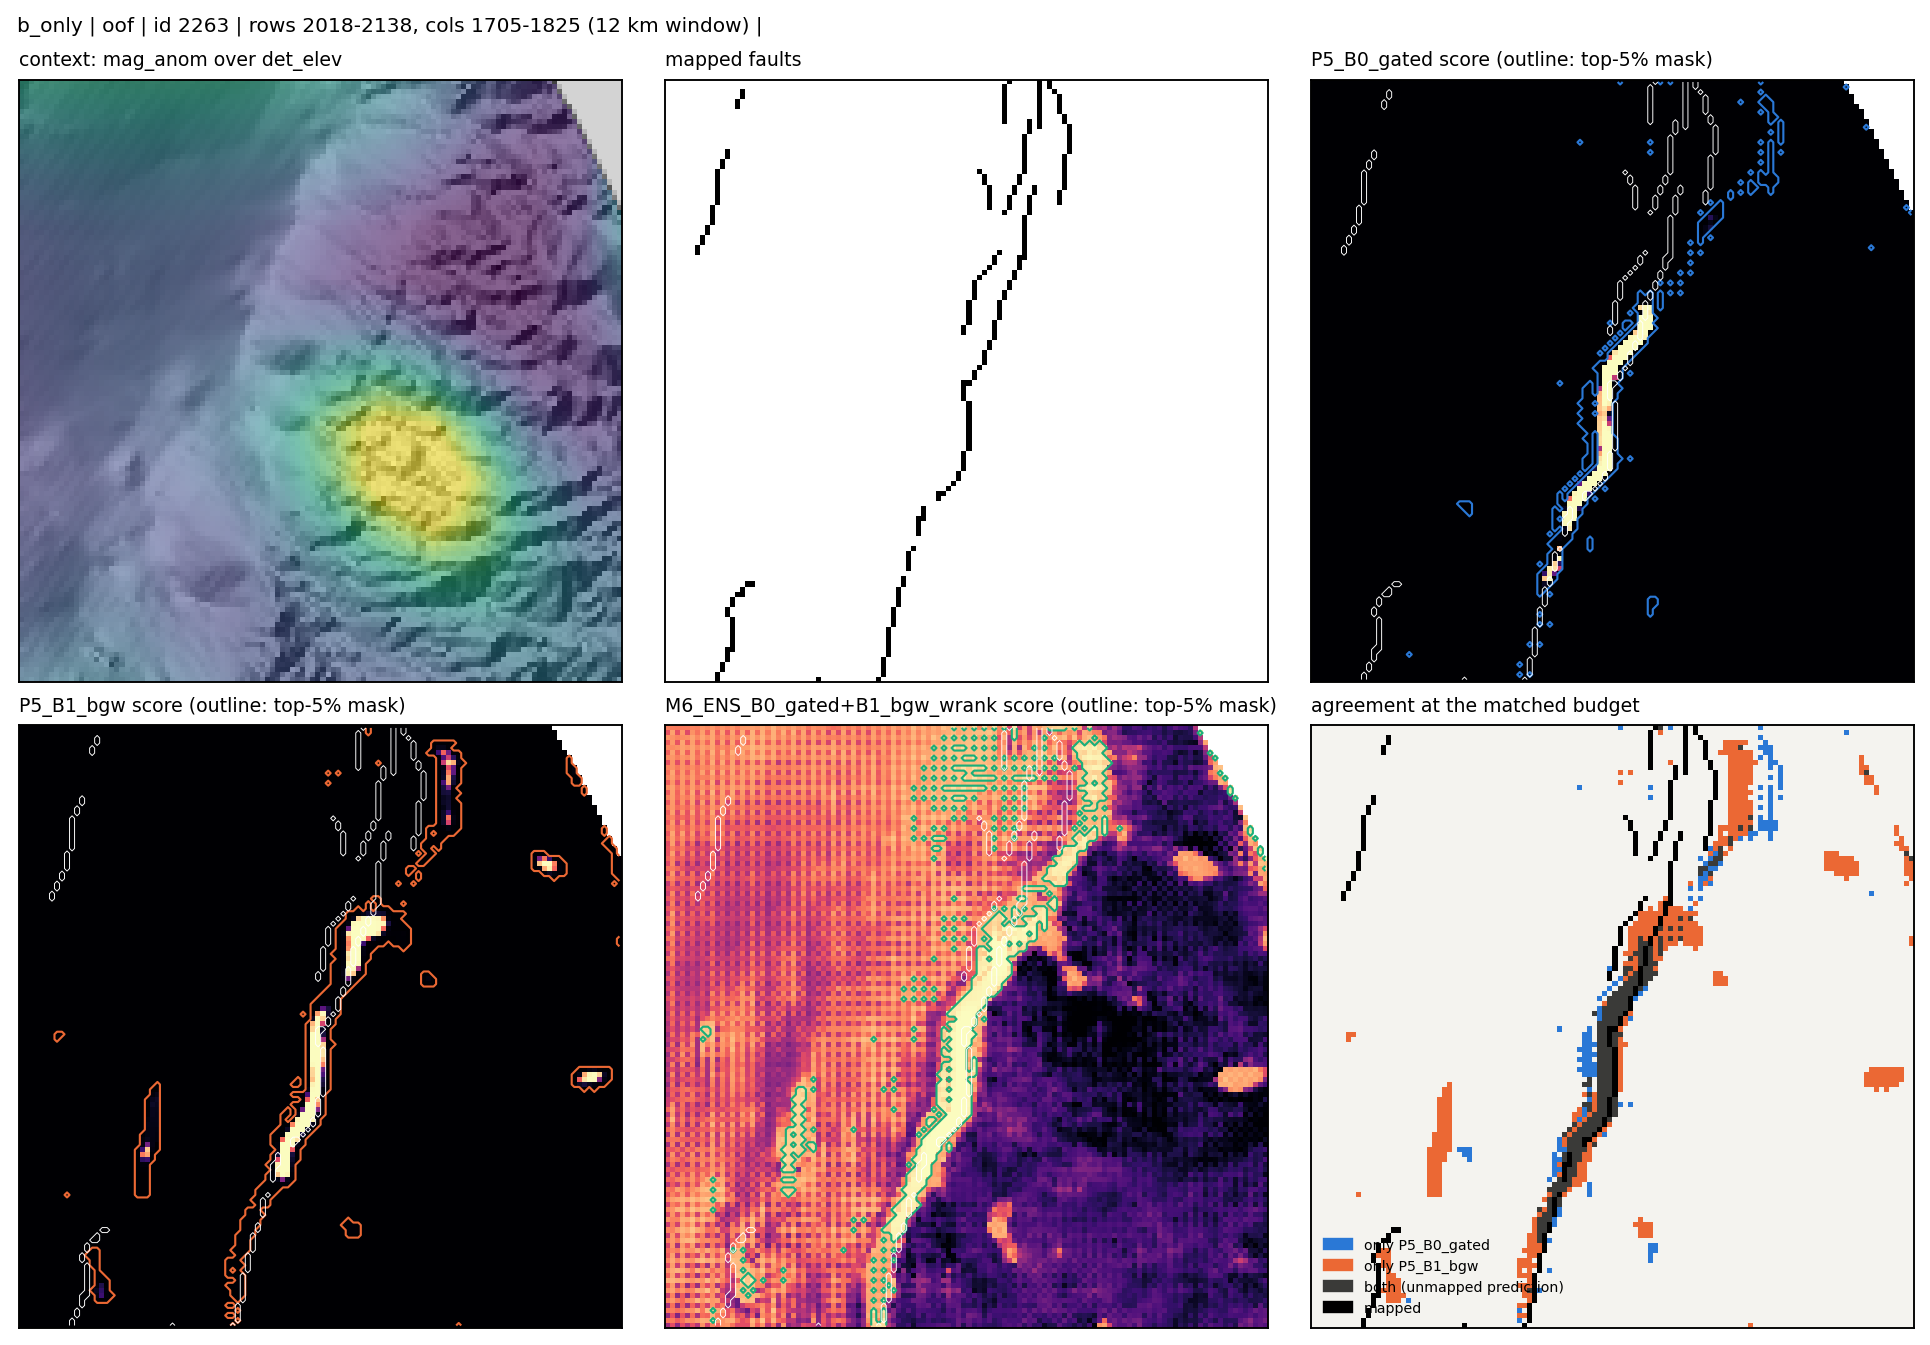

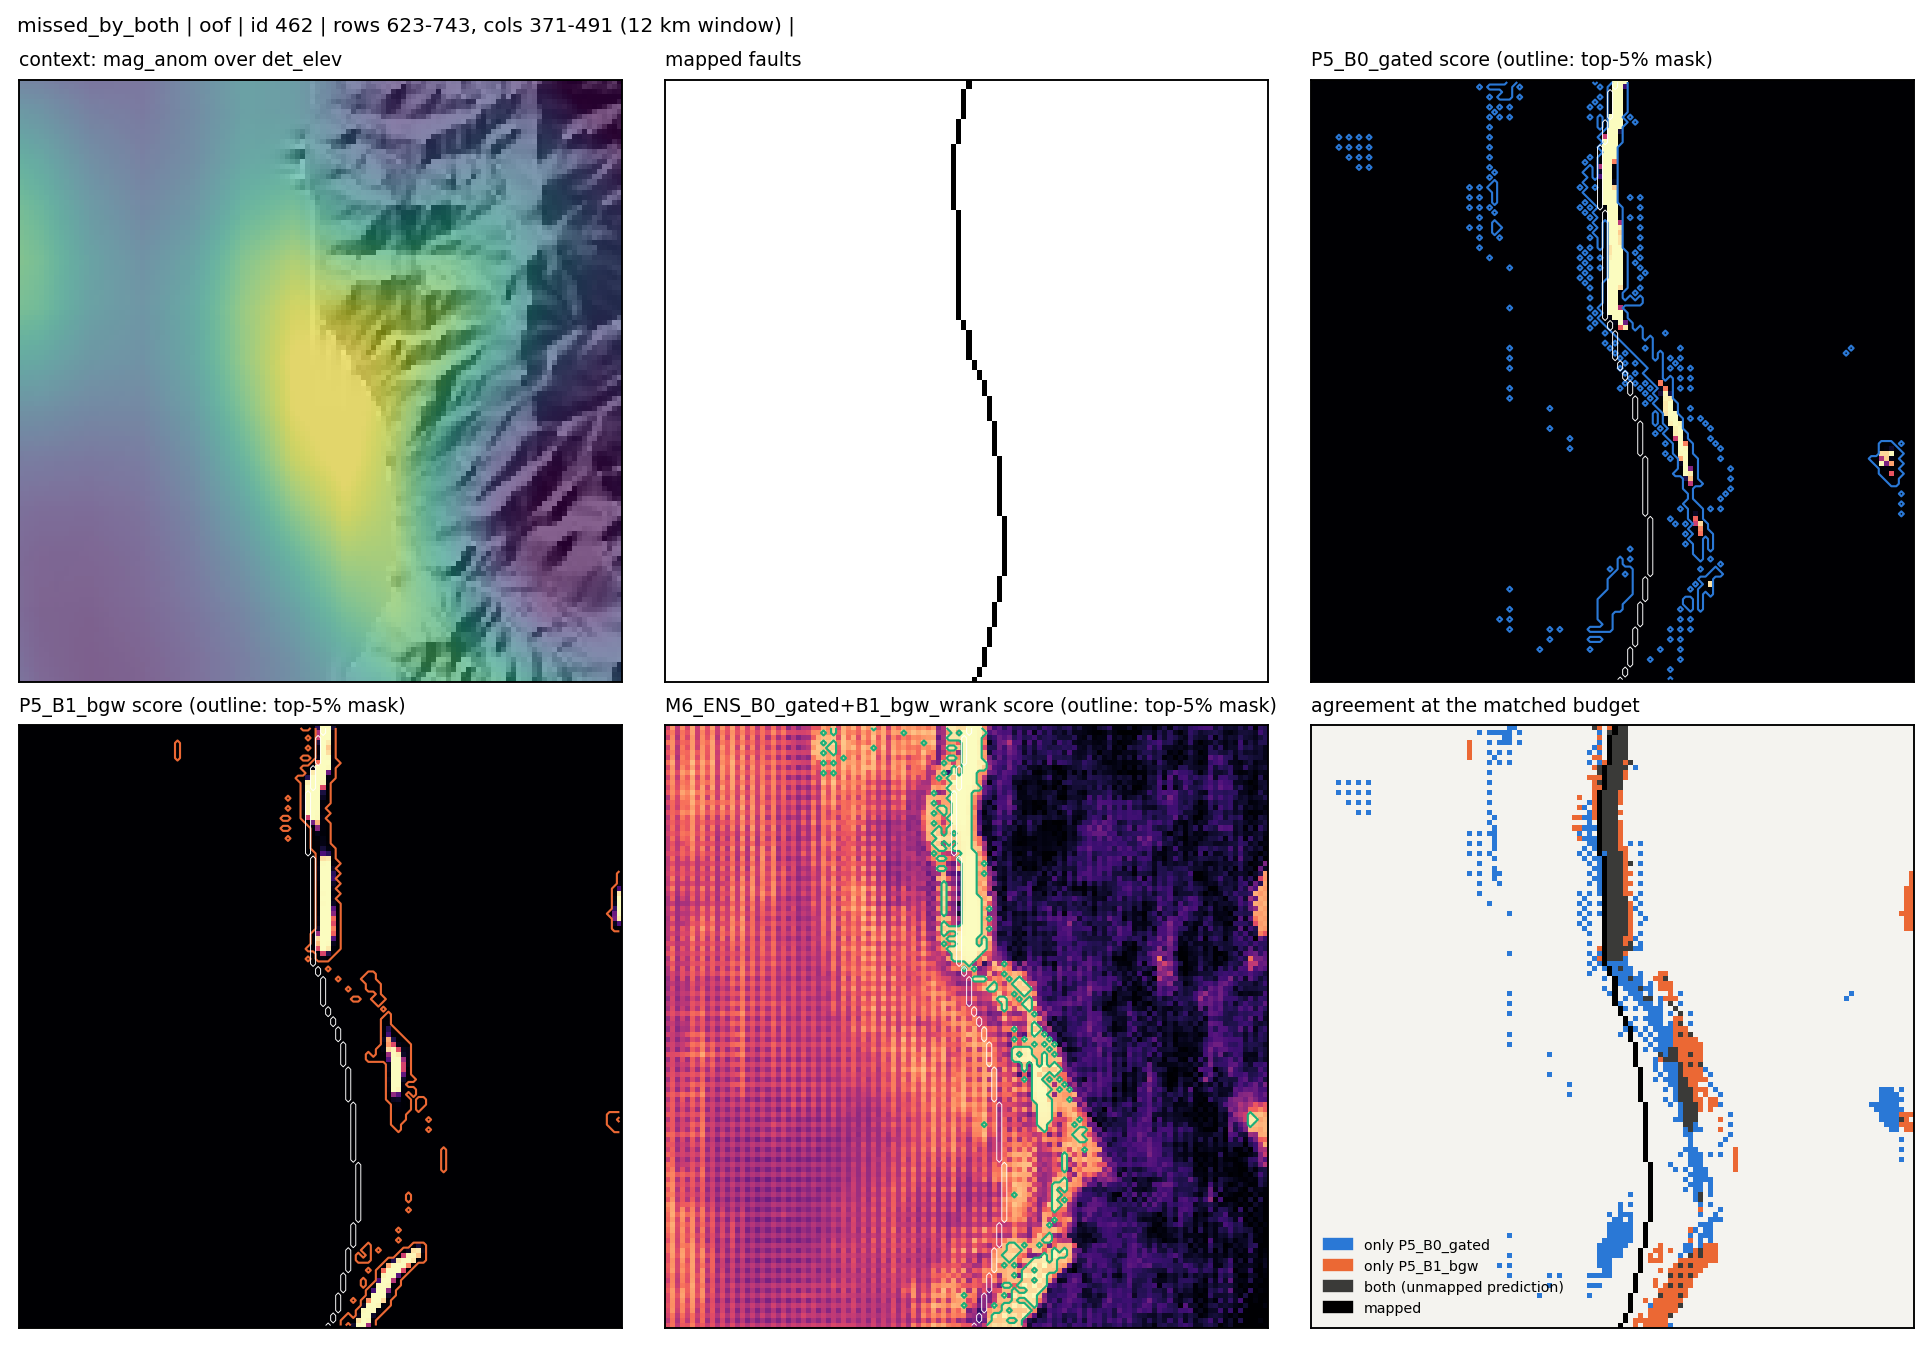

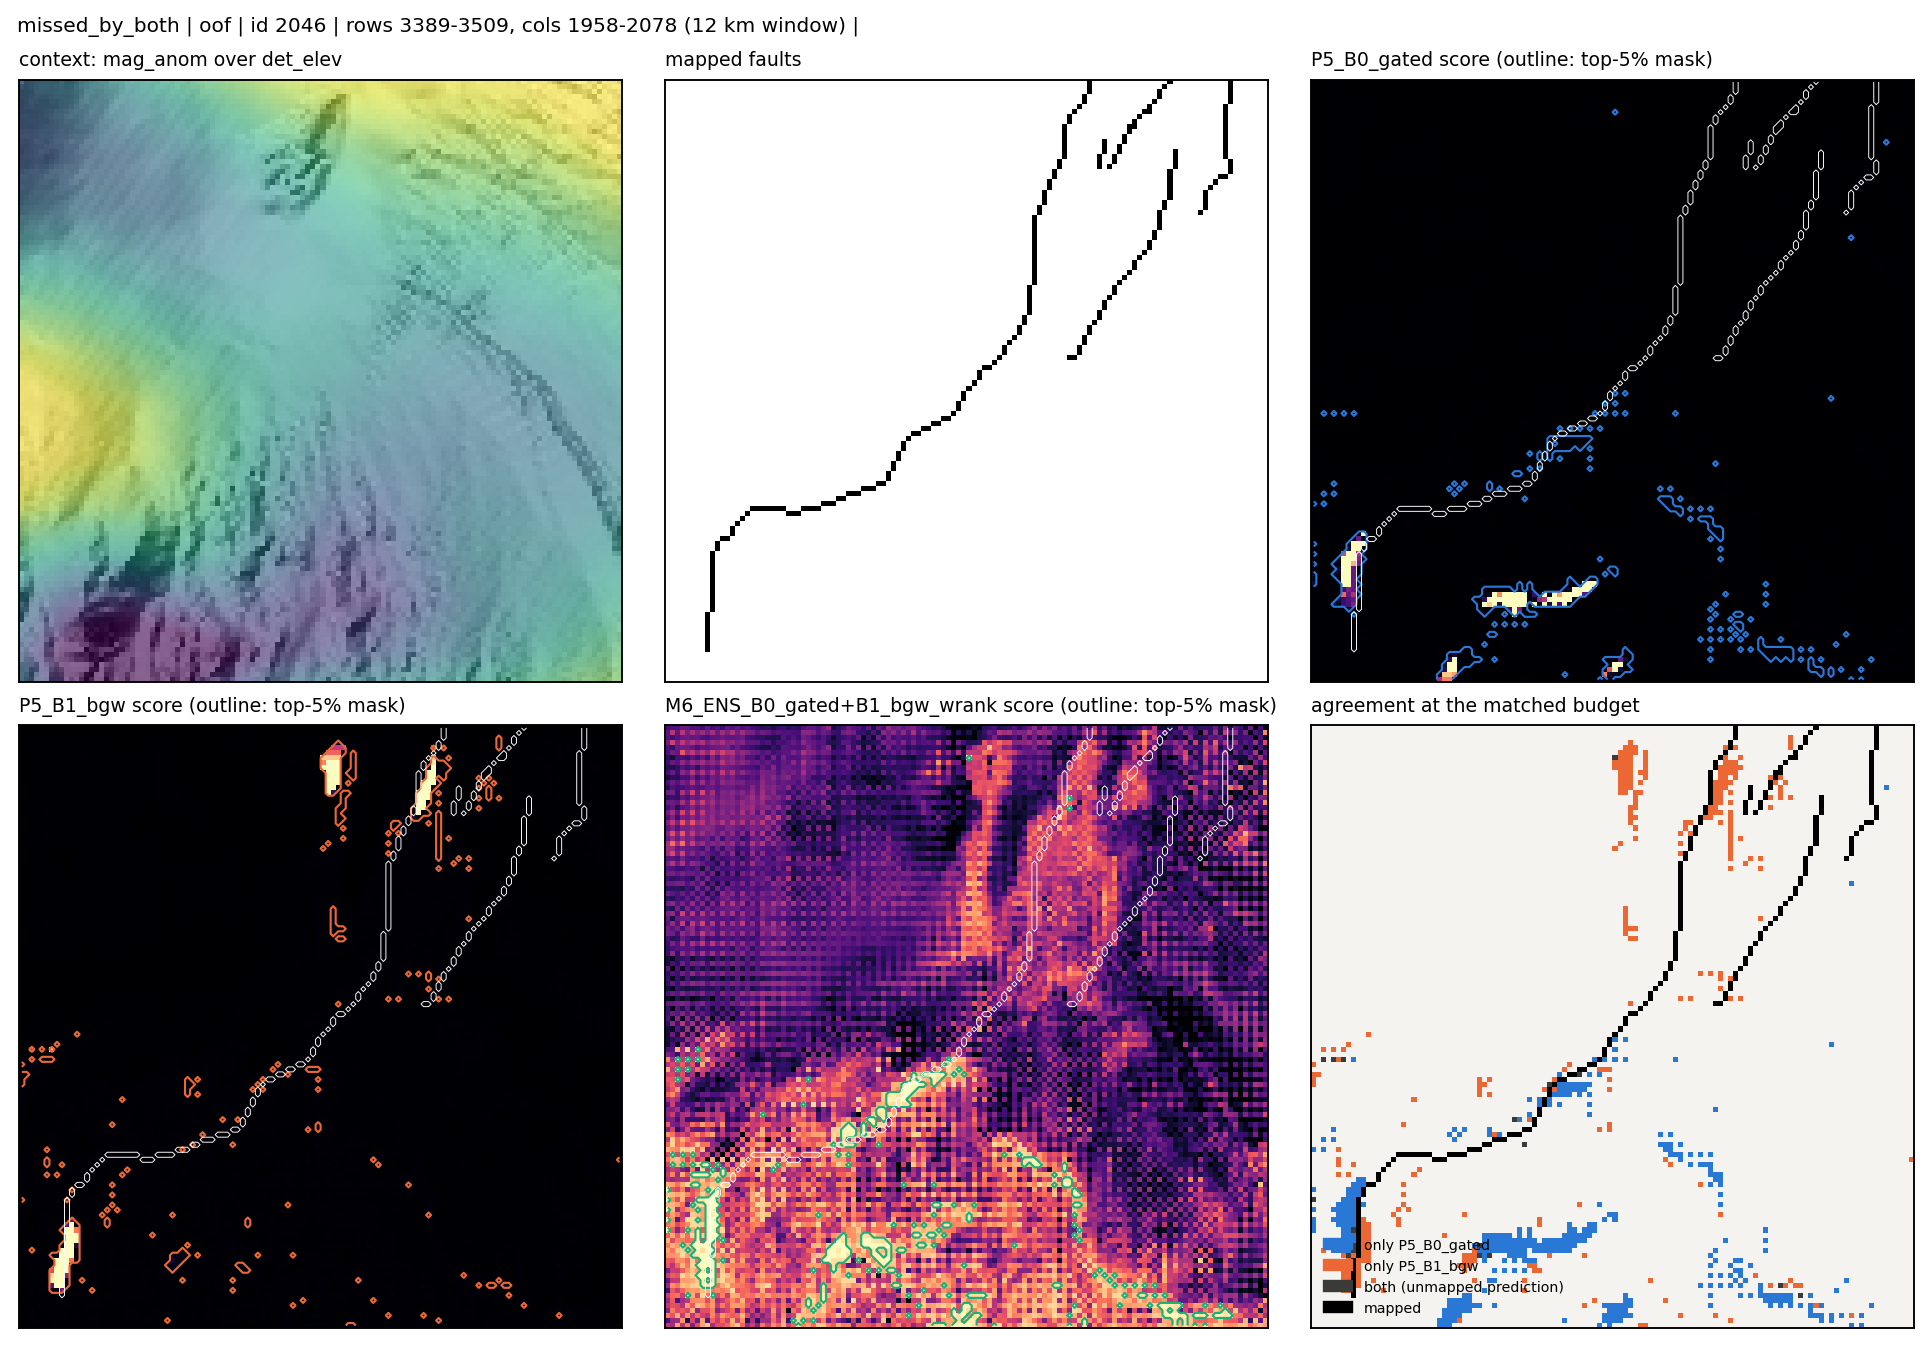

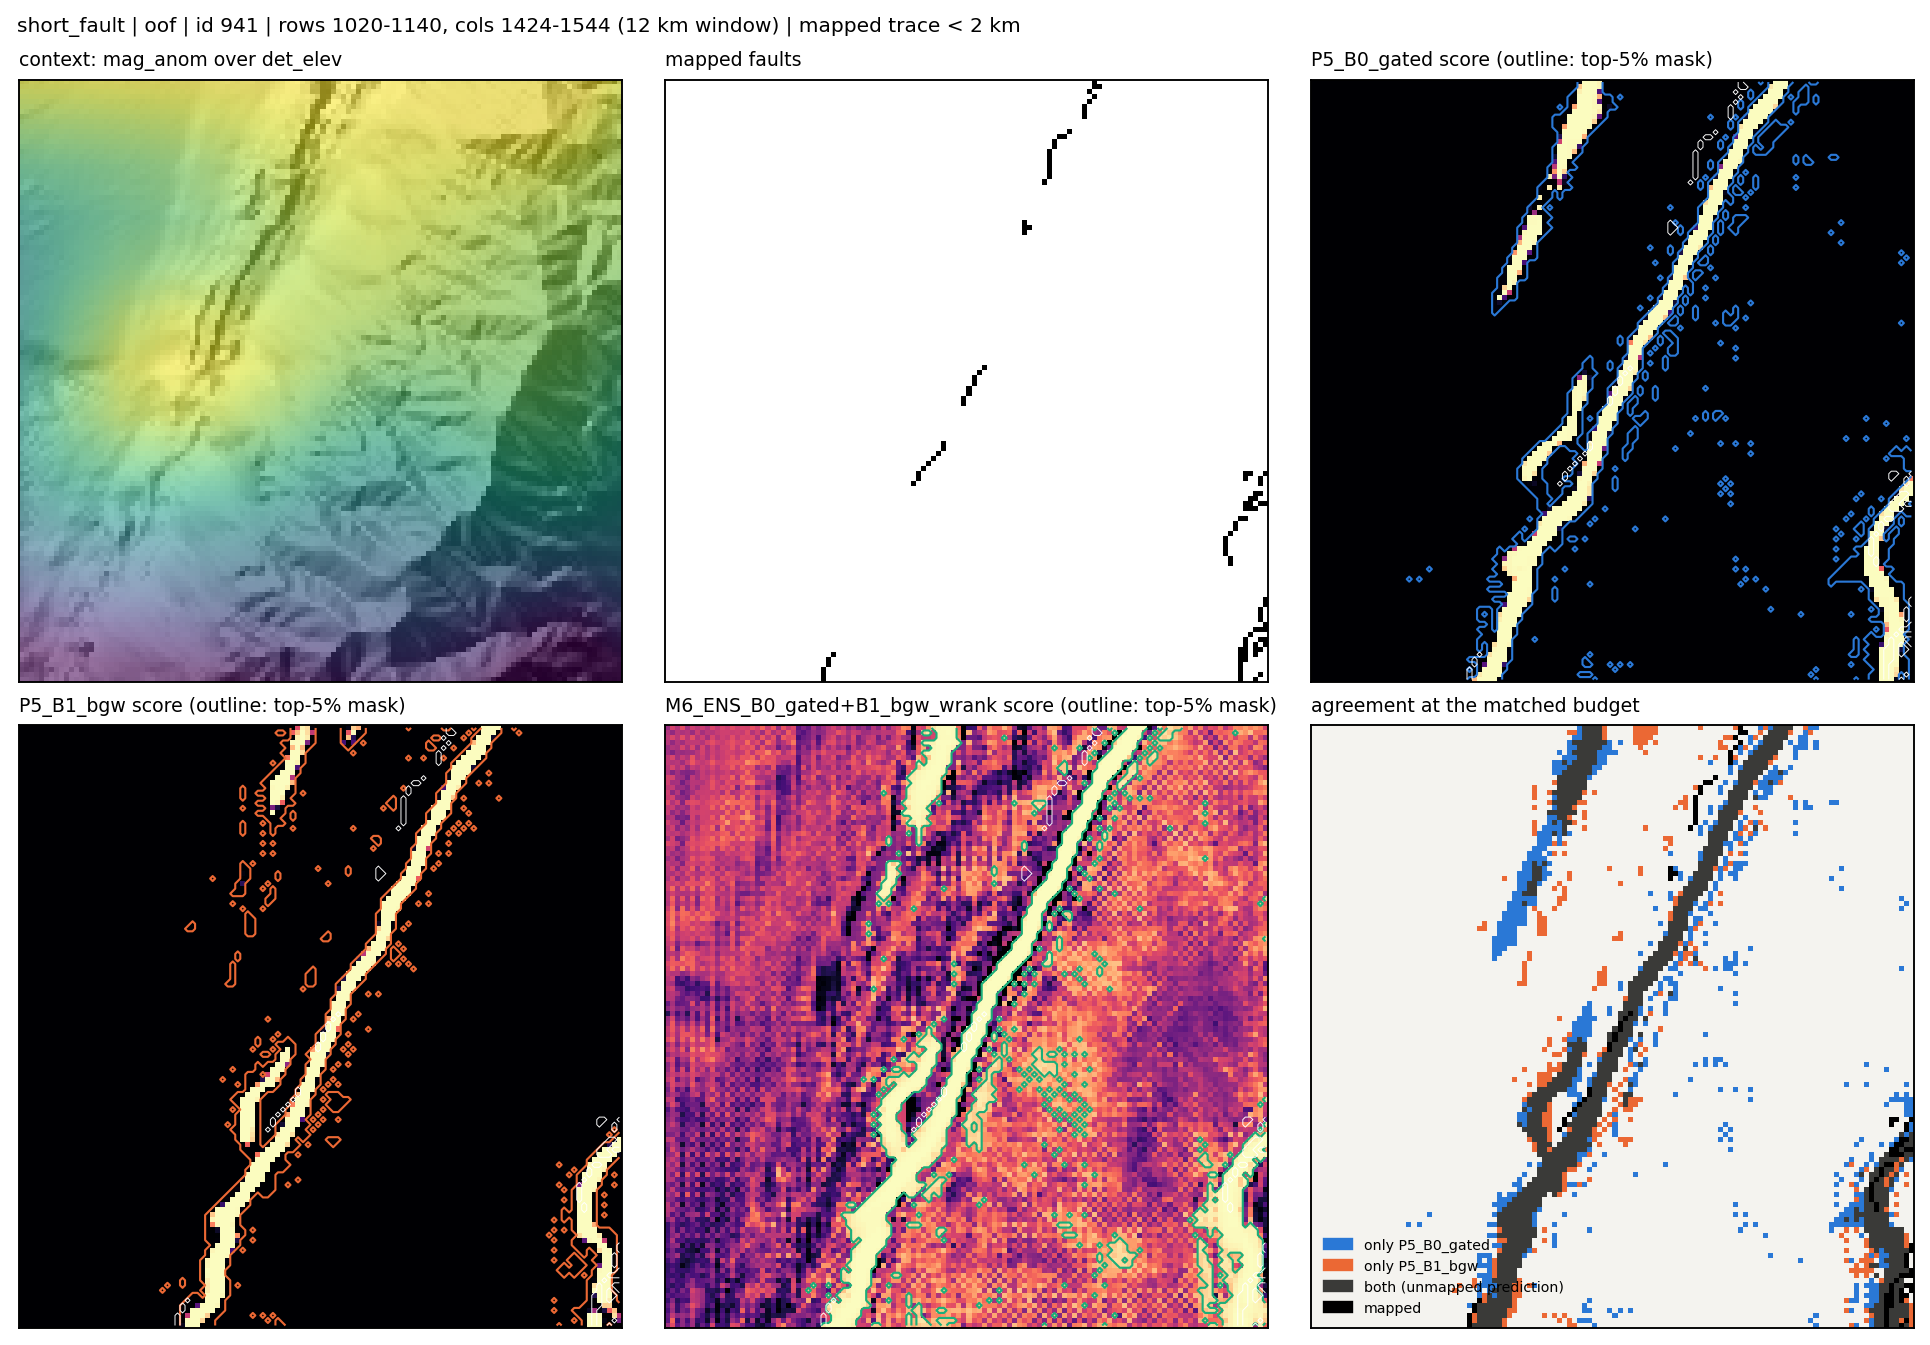

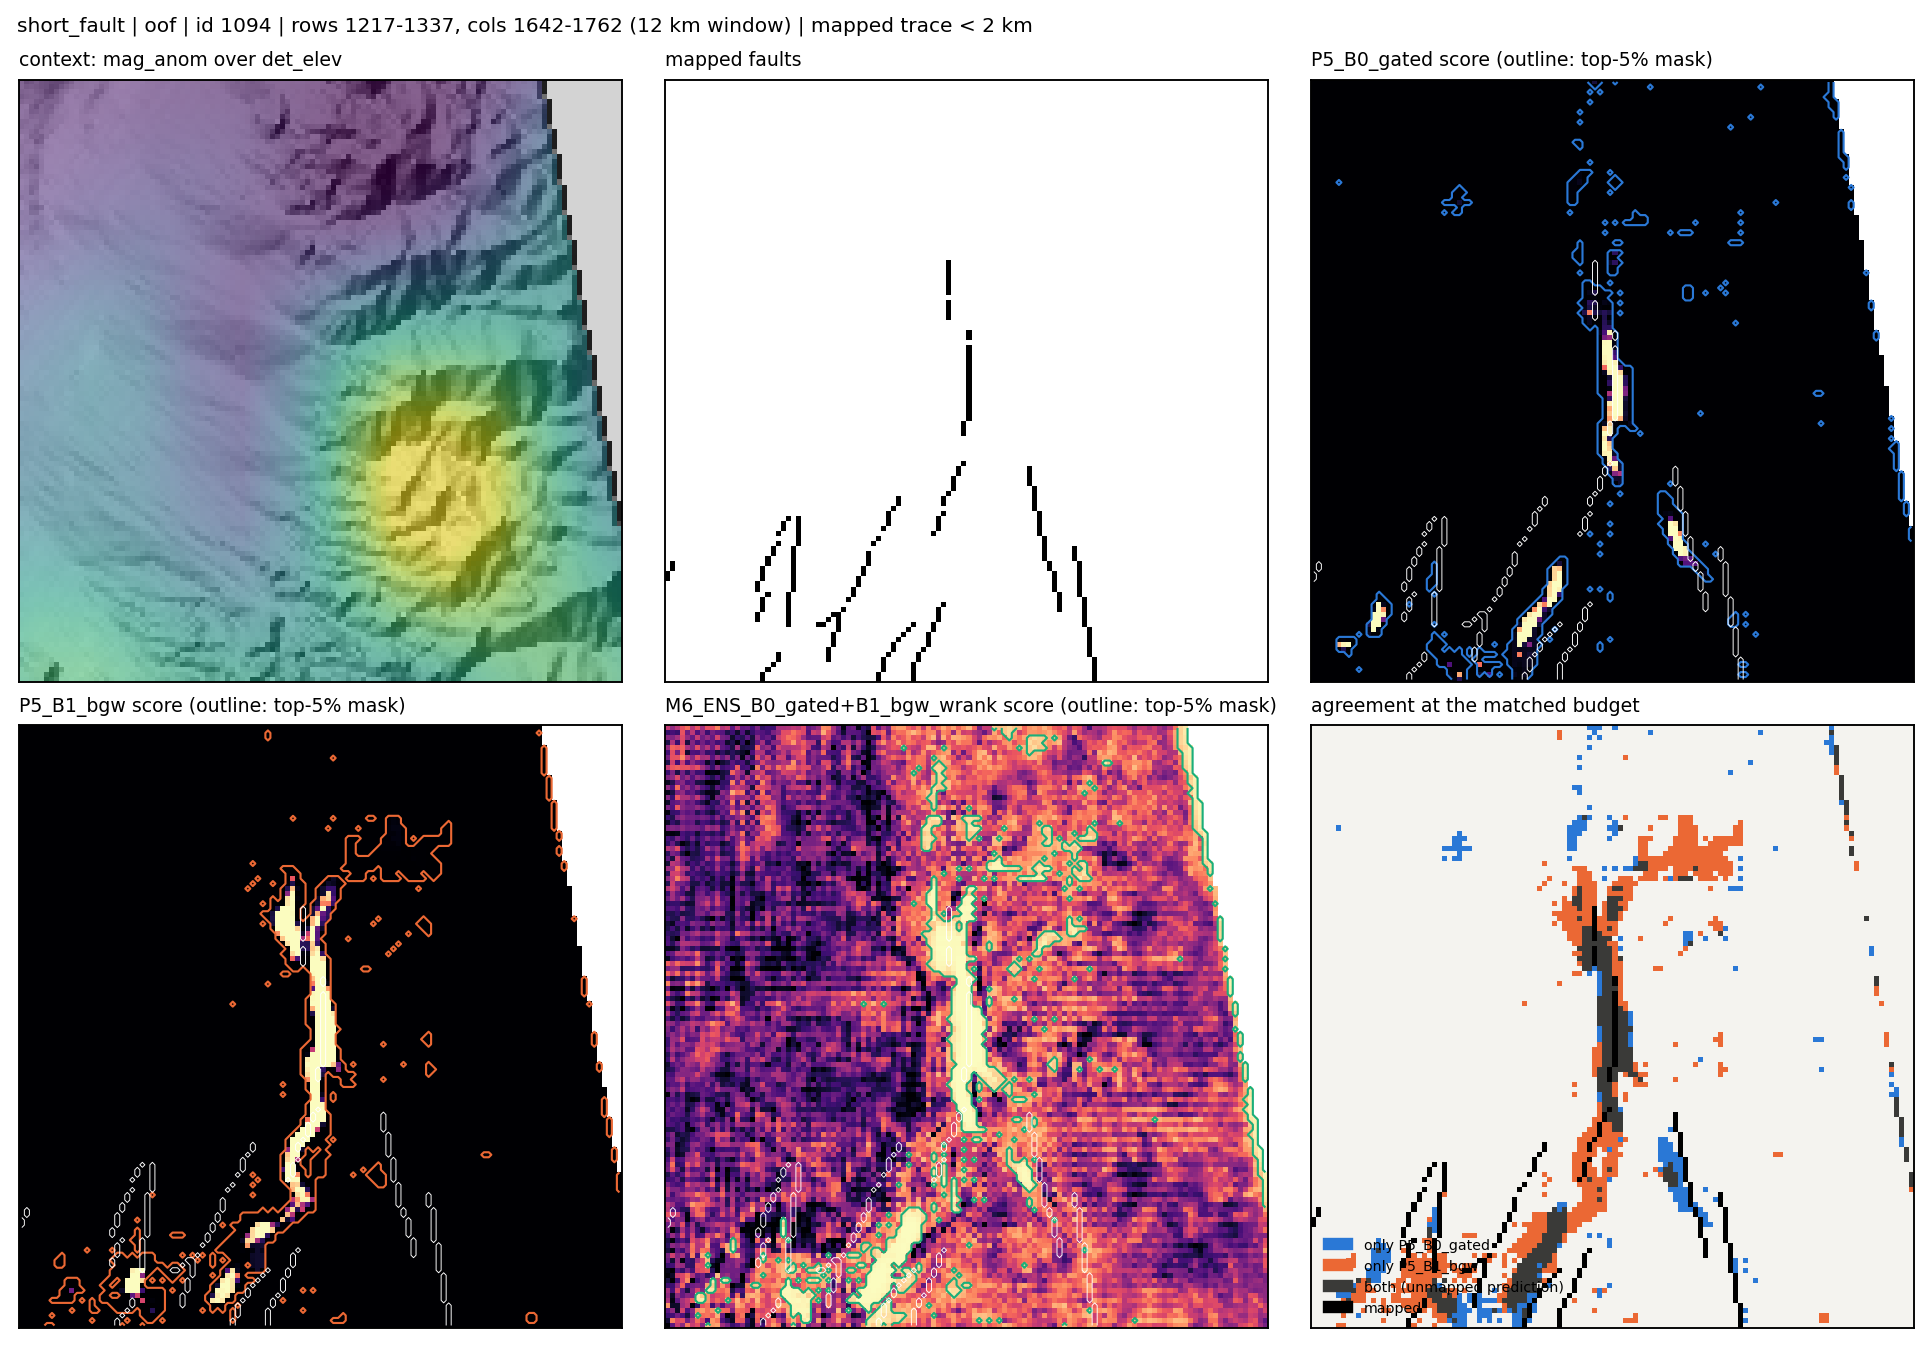

In [25]:
if M6_CONFIG['enabled'] and M6_CONFIG['run_complementarity']:
    comp = m6.complementarity()
    pcm = comp['model_complementarity']
    display(pcm[pcm.zone.astype(str) == 'all'])
    fs = comp['fault_system_summary']
    display(fs[fs.stratum == 'length_bin'].pivot_table(index='value', columns='class', values='trace_km', aggfunc='sum'))
    display(fs[fs.stratum == 'fold'].pivot_table(index='value', columns='class', values='trace_km', aggfunc='sum'))
    if len(comp['discovery_system_classes']):
        display(comp['discovery_system_classes'].groupby(['split', 'class']).size().unstack(fill_value=0))
    display(comp['error_attribution'])
    show(['model_disagreement', 'short_fault_analysis'])
    for w in comp['case_study_windows'].head(8).to_dict('records'):
        show([f"{w['kind']}_{w['source']}_{w['id']}"], sub='figures/geological_case_studies')

### M6.6 Topology-aware postprocessing (optional research layer)

Each operation is evaluated alone, with its parameter and area budget chosen on the other folds. The identity is always a candidate. Faults can be short, discontinuous, branched and curved, so every row shows the change in < 2 km recall, fragmentation, junctions and far-field share next to the DTI change. Operations are combined only if each one helped alone without costing short-fault recall.

[m6] postprocessing: computed in 412s
[sync out] 10 copied (1.3 MiB), 162 unchanged, 0s: ['reports/m6']


,model,operation,dti_crossfit,delta_vs_identity,short_recall_w,delta_short_recall_w,n_components,delta_fragmentation_per_100km,delta_n_junctions,delta_far_share,n_folds_applied
0,P5_B0_gated,identity,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
1,P5_B0_gated,remove_small,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
2,P5_B0_gated,close_gaps,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
3,P5_B0_gated,directional_close,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
4,P5_B0_gated,link_endpoints,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
5,P5_B0_gated,skeleton_width,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
6,P5_B0_gated,min_length,0.165167,0.000000,0.192396,0.000000,53908,0.000000,0,0.000000,0
7,P5_B0_gated,orientation_filter,0.165028,-0.000139,0.218930,0.026535,84433,56.273487,11194,0.020382,3
8,P5_B1_bgw,identity,0.163504,0.000000,0.216310,0.000000,49516,0.000000,0,0.000000,0
9,P5_B1_bgw,remove_small,0.163504,0.000000,0.216310,0.000000,49516,0.000000,0,0.000000,0


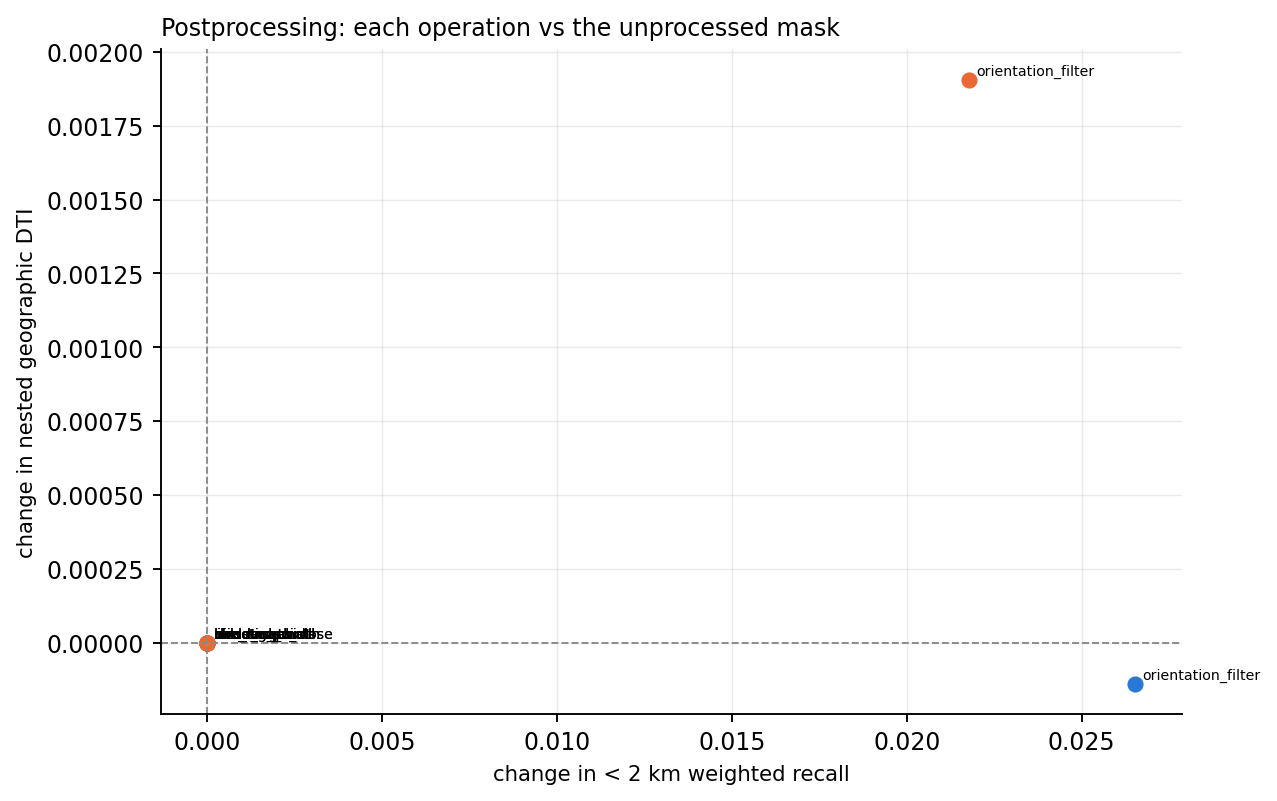

In [26]:
if M6_CONFIG['enabled'] and M6_CONFIG['run_postprocessing']:
    post = m6.postprocessing()
    pa = post['ablation']
    display(pa[[c for c in ('model', 'operation', 'dti_crossfit', 'delta_vs_identity', 'short_recall_w',
                            'delta_short_recall_w', 'n_components', 'delta_fragmentation_per_100km',
                            'delta_n_junctions', 'delta_far_share', 'n_folds_applied') if c in pa]])
    show(['postprocessing_ablation'])

### M6.7 Selection gate and research report

Section-17 criteria plus short-fault recall, area calibration, spatial stability, leakage, provenance and cost, assessed against **both** B0 and B1. A candidate is recommended only with `PROMOTE` against both. Otherwise the report says that no candidate passes. Registry promotion and submission stay manual (sections 16–17 and 19–20).

In [27]:
if M6_CONFIG['enabled']:
    if M6_CONFIG['run_promotion_audit']:
        g = m6.gate()
        d = g['decisions']
        display(d[d.control == 'ALL'][['candidate', 'verdict', 'reason']])
        display(d[d.control != 'ALL'])
        print('recommendation:', g['recommendation'])
    report = m6.report()
    display(m6.summary())                            # compact end-of-section summary
    print('report:', report)
    display(Markdown(report.read_text(encoding='utf-8')[:6000]))

[m6] gate: computed in 0s
[sync out] 4 copied (0.0 MiB), 172 unchanged, 0s: ['reports/m6']


,candidate,verdict,reason
1,P5_B1_bgw,REVIEW,most cautious verdict over controls P5_B0_gated
4,P5_B2_nnpu_p010,REJECT,most cautious verdict over controls P5_B0_gate...
7,P5_C1_heads,REJECT,most cautious verdict over controls P5_B0_gate...
10,M6_ENS_B0_gated+B1_bgw_mean,REVIEW,most cautious verdict over controls P5_B0_gate...
13,M6_ENS_B0_gated+B1_bgw_rankmean,REVIEW,most cautious verdict over controls P5_B0_gate...
16,M6_ENS_B0_gated+B1_bgw_wrank,REVIEW,most cautious verdict over controls P5_B0_gate...
19,M6_ENS_B0_gated+B1_bgw_wrobust,REJECT,most cautious verdict over controls P5_B0_gate...
22,M6_ENS_B0_gated+B1_bgw_wrank_loso,REJECT,most cautious verdict over controls P5_B0_gate...
25,M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010_wrank,REVIEW,most cautious verdict over controls P5_B0_gate...
28,M6_ENS_B0_gated+B1_bgw+C1_heads_wrank,REVIEW,most cautious verdict over controls P5_B0_gate...


,candidate,control,verdict,reason,1_primary_discovery,2_geographic,3_worst_fold,4_retained_fp,5_short_fault_recall,6_area_calibration,...,evidence_1_primary_discovery,evidence_2_geographic,evidence_3_worst_fold,evidence_4_retained_fp,evidence_5_short_fault_recall,evidence_6_area_calibration,evidence_7_spatial_stability,evidence_8_no_leakage,evidence_9_provenance,evidence_10_cost
0,P5_B1_bgw,P5_B0_gated,REVIEW,"failed: 3_worst_fold, 4_retained_fp, 5_short_f...",PASS,PASS,FAIL,FAIL,FAIL,FAIL,...,0.0056,0.0033,"geo fold-min +0.0097, disc split-min +0.0498, ...",-0.0051,-0.0129,"area ratio geo x1.50, disc x1.67; far-share fa...",P(geo delta > 0) = 0.74,selection audit,P5_B1_bgw=COMPLETE,x1.0 single-model inference
2,P5_B2_nnpu_p010,P5_B0_gated,REVIEW,"failed: 2_geographic, 3_worst_fold, 4_retained...",PASS,FAIL,FAIL,FAIL,FAIL,FAIL,...,0.0050,-0.0284,"geo fold-min -0.0290, disc split-min +0.0226, ...",-0.0063,-0.0380,"area ratio geo x1.00, disc x1.67; far-share fa...",P(geo delta > 0) = 0.00,selection audit,P5_B2_nnpu_p010=COMPLETE,x1.0 single-model inference
3,P5_B2_nnpu_p010,P5_B1_bgw,REJECT,no primary gain and a regression beyond tolerance,FAIL,FAIL,FAIL,PASS,FAIL,PASS,...,-0.0005,-0.0317,"geo fold-min -0.0387, disc split-min -0.0272, ...",-0.0012,-0.0251,"area ratio geo x0.67, disc x1.00; far-share fa...",P(geo delta > 0) = 0.00,selection audit,P5_B2_nnpu_p010=COMPLETE,x1.0 single-model inference
5,P5_C1_heads,P5_B0_gated,REJECT,no primary gain and a regression beyond tolerance,FAIL,FAIL,FAIL,PASS,FAIL,PASS,...,-0.0073,-0.0221,"geo fold-min -0.0365, disc split-min -0.0130, ...",-0.0012,-0.0459,"area ratio geo x1.00, disc x1.00; far-share fa...",P(geo delta > 0) = 0.00,selection audit,P5_C1_heads=COMPLETE,x1.0 single-model inference
6,P5_C1_heads,P5_B1_bgw,REJECT,no primary gain and a regression beyond tolerance,FAIL,FAIL,FAIL,PASS,FAIL,PASS,...,-0.0129,-0.0254,"geo fold-min -0.0462, disc split-min -0.0628, ...",0.0038,-0.0330,"area ratio geo x0.67, disc x0.60; far-share fa...",P(geo delta > 0) = 0.00,selection audit,P5_C1_heads=COMPLETE,x1.0 single-model inference
8,M6_ENS_B0_gated+B1_bgw_mean,P5_B0_gated,REVIEW,"failed: 5_short_fault_recall, 6_area_calibration",PASS,PASS,PASS,PASS,FAIL,FAIL,...,0.0507,-0.0038,"geo fold-min -0.0026, disc split-min +0.0701, ...",0.0031,-0.0303,"area ratio geo x1.50, disc x1.67; far-share fa...",P(geo delta > 0) = 0.14,selection audit,"P5_B0_gated=COMPLETE, P5_B1_bgw=COMPLETE",x2.0 single-model inference
9,M6_ENS_B0_gated+B1_bgw_mean,P5_B1_bgw,REVIEW,"failed: 2_geographic, 3_worst_fold, 5_short_fa...",PASS,FAIL,FAIL,PASS,FAIL,PASS,...,0.0451,-0.0071,"geo fold-min -0.0123, disc split-min +0.0203, ...",0.0082,-0.0175,"area ratio geo x1.00, disc x1.00; far-share fa...",P(geo delta > 0) = 0.00,selection audit,"P5_B0_gated=COMPLETE, P5_B1_bgw=COMPLETE",x2.0 single-model inference
11,M6_ENS_B0_gated+B1_bgw_rankmean,P5_B0_gated,REVIEW,"failed: 1_primary_discovery, 3_worst_fold, 6_a...",FAIL,PASS,FAIL,PASS,PASS,FAIL,...,-0.0001,0.0137,"geo fold-min +0.0132, disc split-min -0.0125, ...",0.0119,0.0140,"area ratio geo x1.00, disc x1.67; far-share fa...",P(geo delta > 0) = 1.00,selection audit,"P5_B0_gated=COMPLETE, P5_B1_bgw=COMPLETE",x2.0 single-model inference
12,M6_ENS_B0_gated+B1_bgw_rankmean,P5_B1_bgw,REVIEW,"failed: 1_primary_discovery, 3_worst_fold",FAIL,PASS,FAIL,PASS,PASS,PASS,...,-0.0057,0.0104,"geo fold-min +0.0035, disc split-min -0.0624, ...",0.0170,0.0269,"area ratio geo x0.67, disc x1.00; far-share fa...",P(geo delta > 0) = 1.00,selection audit,"P5_B0_gated=COMPLETE, P5_B1_bgw=COMPLETE",x2.0 single-model inference
14,M6_ENS_B0_gated+B1_bgw_wrank,P5_B0_gated,REVIEW,"failed: 1_primary_discovery, 3_worst_fold, 6_a...",FAIL,PASS,FAIL,PASS,PASS,FAIL,...,0.0006,0.0128,"geo fold-min +0.0133, disc split-min -0.0078, ...",0.0114,0.0091,"area ratio geo x1.00, disc x1.67; far-share fa...",P(geo delta > 0) = 1.00,selection audit,"P5_B0_gated=COMPLETE, P5_B1_bgw=COMPLETE",x2.0 single-model inference


recommendation: {'recommended': None, 'verdict': 'NO_CANDIDATE_PASSES', 'rule': 'no candidate passed every criterion against both controls', 'review': ['P5_B1_bgw', 'M6_ENS_B0_gated+B1_bgw_mean', 'M6_ENS_B0_gated+B1_bgw_rankmean', 'M6_ENS_B0_gated+B1_bgw_wrank', 'M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010_wrank', 'M6_ENS_B0_gated+B1_bgw+C1_heads_wrank', 'M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010+C1_heads_wrank'], 'candidates': ['P5_B1_bgw', 'P5_B2_nnpu_p010', 'P5_C1_heads', 'M6_ENS_B0_gated+B1_bgw_mean', 'M6_ENS_B0_gated+B1_bgw_rankmean', 'M6_ENS_B0_gated+B1_bgw_wrank', 'M6_ENS_B0_gated+B1_bgw_wrobust', 'M6_ENS_B0_gated+B1_bgw_wrank_loso', 'M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010_wrank', 'M6_ENS_B0_gated+B1_bgw+C1_heads_wrank', 'M6_ENS_B0_gated+B1_bgw+B2_nnpu_p010+C1_heads_wrank'], 'controls': ['P5_B0_gated', 'P5_B1_bgw'], 'rules': {'primary_policy': 'excl', 'alt_policy': 'retained_fp', 'min_disc_gain': 0.005, 'max_alt_drop': 0.002, 'max_geo_drop': 0.005, 'min_unique_systems': 1, 'max_far_share_increas

,model,geo_dti,geo_fold_min,disc_dti_excl,disc_dti_retained_fp,short_recall_w,verdict
0,P5_B0_gated,0.164560,0.153408,0.203035,0.096351,0.192396,control
1,P5_B1_bgw,0.167877,0.163087,0.208598,0.091277,0.179544,REVIEW
2,P5_B2_nnpu_p010,0.136179,0.124361,0.208077,0.090033,0.154436,REJECT
3,P5_C1_heads,0.142457,0.116906,0.195734,0.095121,0.146505,REJECT
4,B0_lineament,0.068924,0.064551,0.039337,0.037960,0.079976,control
5,G1,0.132652,0.116454,0.100085,0.084869,0.137625,control
6,G3,0.116544,0.103700,0.074956,0.058492,0.133175,control
7,M6_ENS_B0_gated+B1_bgw_mean,0.160795,0.150807,0.253727,0.099443,0.162090,REVIEW
8,M6_ENS_B0_gated+B1_bgw_rankmean,0.178309,0.166573,0.202933,0.108299,0.206433,REVIEW
9,M6_ENS_B0_gated+B1_bgw_wrank,0.177374,0.166754,0.203592,0.107746,0.201516,REVIEW


report: /content/gems_work/reports/m6/M6_RESEARCH_REPORT.md


# GEMS 2.1 - M6 research report: model selection, ensembles and geological error analysis

_Generated 2026-10-26 01:14 by `gems_bench.pipeline.m6` (version m6.1) at code commit `c3cea7664c944ac35eb6381fa2b8f523edee4df3`; evaluation protocol `dc29ba9f7fce`. Every number is read from the tables under `reports/m6/`, computed by this run from saved FULL predictions. No model was trained. Local scores are not leaderboard scores; geographic and pseudo-discovery DTI are different quantities and are never averaged._

## Central question

Can an ensemble combine P5_B0_gated's short-fault recall and retained-FP robustness with P5_B1_bgw's geographic generalisation and discovery DTI?

Primary (prespecified) candidate: `M6_ENS_B0_gated+B1_bgw_wrank` (members P5_B0_gated+P5_B1_bgw, nested weights per fold {"0": "{\"P5_B0_gated\": 0.5, \"P5_B1_bgw\": 0.5}", "1": "{\"P5_B0_gated\": 0.4, \"P5_B1_bgw\": 0.6}", "2": "{\"P5_B0_gated\": 0.2, \"P5_B1_bgw\": 0.8}"}).

| metric | ensemble | delta_vs_P5_B0_gated | delta_vs_P5_B1_bgw |
|---|---|---|---|
| geo_dti | 0.1774 | 0.0128 | 0.0095 |
| geo_fold_min | 0.1668 | 0.0133 | 0.0037 |
| disc_dti_excl | 0.2036 | 0.0006 | -0.0050 |
| disc_dti_retained_fp | 0.1077 | 0.0114 | 0.0165 |
| short_recall_w | 0.2015 | 0.0091 | 0.0220 |


Gate verdict for `M6_ENS_B0_gated+B1_bgw_wrank`: **REVIEW** (most cautious verdict over controls P5_B0_gated, P5_B1_bgw).

Recommendation: **none** (NO_CANDIDATE_PASSES; rule: no candidate passed every criterion against both controls).

## M6.1 Artifact audit

Status: COMPLETE / PARTIAL / INCOMPATIBLE / MISSING / INVALID. Only COMPLETE FULL runs are analysed and eligible for promotion. Provenance: `provenance_audit.csv`; pairwise: `model_compatibility.csv`.

| model | kind | status | experiment_id | profile | n_disc_maps | feature_version | git_commit | reasons |
|---|---|---|---|---|---|---|---|---|
| P5_B0_gated | experiment | COMPLETE | b0_reference__d54e938a | FULL | 3.0000 | 8795de7cfac1 | 8bccce056e364d37b2323582195ba090b85868c5 | nan |
| P5_B1_bgw | experiment | COMPLETE | b1_bg_weight__7755635b | FULL | 3.0000 | 8795de7cfac1 | 8bab38b4b46747501c07e72b18ce454732a9ad3d | nan |
| P5_B2_nnpu_p010 | experiment | COMPLETE | b2_nnpu_p010__e0173a9a | FULL | 3.0000 | 8795de7cfac1 | 8bccce056e364d37b2323582195ba090b85868c5 | nan |
| P5_C1_heads | experiment | COMPLETE | c1_geometry_heads__9a77180d | FULL | 3.0000 | 8795de7cfac1 | 8bccce056e364d37b2323582195ba090b85868c5 | nan |
| P5_E1_gsn_gated | experiment | MISSING | e1_gsn_parity__b8b8c3db | FULL | 0.0000 | 8795de7cfac1 | 8bccce056e364d37b2323582195ba090b85868c5 | OOF map absent |
| B0_lineament | baseline | COMPLETE | nan | FULL | nan | nan | nan | nan |
| G1 | baseline | COMPLETE | nan | FULL | nan | nan | nan | nan |
| G3 | baseline | COMPLETE | nan | FULL | nan | nan | nan | nan |

### Reference observations vs persisted / recomputed scores

0 of 20 reference numbers differ beyond tolerance (reported, not reconciled).

| model | metric | reference_observation | persisted | recomputed | status |
|---|---|---|---|---|---|
| P5_B0_gated | geo_dti_area | 0.1646 | 0.1646 | 0.1646 | MATCH |
| P5_B0_gated | geo_fold_min | 0.1534 | 0.1534 | 0.1534 | MATCH |
| P5_B0_gated | disc_dti_excl | 0.2030 | 0.2030 | 0.2030 | MATCH |
| P5_B0_gated | disc_dti_retained_fp | 0.0964 | 0.0964 | 0.0964 | MATCH |
| P5_B0_gated | short_recall_w | 0.1924 | 0.1924 | 0.1924 | MATCH |
| P5_B1_bgw | geo_dti_area | 0.1679 | 0.1679 | 0.1679 | MATCH |
| P5_B1_bgw | geo_fold_min | 0.1631 | 0.1631 | 0.1631 | MATCH |
| P5_B1_bgw | disc_dti_excl | 0.2086 | 0.2086 | 0.2086 | MATCH |
| P5_B1_bgw | disc_dti_retained_fp | 0.0913 | 0.0913 | 0.0913 | MATCH |
| P5_B1_bgw | short_recall_w | 0.1795 | 0.1795 | 0.1795 | MATCH |
| P5_B2_nnpu_p010 | geo_dti_area | 0.1362 | 0.1362 | 0.1362 | MATCH |
| P5_B2_nnpu_p010 | geo_fold_min | 0.1244 | 0.1244 | 0.1244 | MATCH |
| P5_B2_nnpu_p010 | disc_dti_excl | 0.2081 | 0.2081 | 0.2081 | MATCH |
| P5_B2_nnpu_p010 | disc_dti_retained_fp | 0.0900 | 0.0900 | 0.0900 | MATCH |
| P5_B2_nnpu_p010 | short_recall_w | 0.1544 | 0.1544 | 0.1544 | MATCH |
| P5_C1_heads | geo_dti_area | 0.1425 | 0.1425 | 0.1425 | MATCH |
| P5_C1_heads | geo_fold_min | 0.1169 | 0.1169 | 0.1169 | MATCH |
| P5_C1_heads | disc_dti_excl | 0.1957 | 0.1957 | 0.1957 | MATCH |
| P5_C1_heads | disc_dti_retained_fp | 0.0951 | 0.0951 | 0.0951 | MATCH |
| P5_C1_heads | short_recall_w | 0.1465 | 0.1465 | 0.1465 | MATCH |


## M6.2 Consolidated comparison (one protocol)

| model | geo_dti_area | geo_fold_min | geo_fold_std | disc_dti_excl | disc_dti_retained_fp | short_recall_w | geo_far_share_at_match |
|---|---|---|---|---|---|---|---|
| P5_B0_gated | 0.1646 | 0.1534 | 0.0119 | 0.2030 | 0.0964 | 0.1924 | 0.5712 |
| P5_B1_bgw | 0.1679 | 0.1631 | 0.0043 | 0.2086 | 0.0913 | 0.1795 | 0.5335 |
| P5_B2_nnpu_p010 | 0.1362 | 0.1244 | 0.0104 | 0.2081 | 0.0900 | 0.1544 | 0.5533 |
| P5_C1_heads | 0.1425 | 0.1169 | 0.0168 | 0.1957 | 0.0951 | 0.1465 | 0.5834 |
| B0_lineament | 0.0689 | 0.0646 | 0.0043 | 0.0393 | 0.0380 | 0.0800 | 0.6159 |
| G1 | 0.1327 | 0.1165 | 0.0135 | 0.1001 | 0.0849 | 0.1376 | 0.5130 |
| G3 | 0.1165 | 0.1037 | 0.0156 | 0.0750 | 0.0585 | 0.1332 | 0.5118 |

## Paired differences (per fold / split)

Three folds / three splits: directional consistency and effect sizes are descriptive, not population-level tests.

| task | model | reference | policy | n_units | mean_delta | min_delta | max_delta | units_improved | sign_pattern | effect_size_dz |
|---|---|---|---|---|---|---|---|---|---|---|
| geographic | B0_lineament | P5_B0_gated | nan | 3 | -0.0937 | -0.1110 | -0.0813 | 0 | --- | -6.0680 |
| geographic | G1 | P5_B0_gated | nan | 3 | -0.0321 | -0.0520 | -0.0044 | 0 | --- | -1.2991 |
| geographic | G3 | P5_B0_gated | nan | 3 | -0.0483 | -0.0762 | -0.0164 | 0 | --- | -1.6046 |
| geographic | P5_B1_bgw | P5_B0_gated | nan | 3 | 0.0043 | -0.0139 | 0.0199 | 2 | ++- | 0.2509 |
| geographic | P5_B2_nnpu_p010 | P5_B0_gated | nan | 3 | -0

## 18c. GEMS 3.0 — discovery-first research on existing predictions (no CNN retraining)

**Why.** B1 improved geographic DTI only modestly, and B2 / C1 did not help. GEMS3 tests explanations that need no new CNN: (1) the training target differs from the competition target, (2) the output representation is poorly matched to the metric, (3) faults are structures, not pixels.

**Verified contract** (organizer answers, `docs/GEMS_OFFICIAL_METRIC_AUDIT.md`): the hidden truth is *new* faults only; known faults are masked **pixel-exactly** (no buffer); a prediction near a known trace but far from new truth is fully penalised; one Tversky index is pooled over all public pixels. The historical pseudo-discovery `excl` policy (300 m dilated exclusion) was over-forgiving. The new primary task `disc_official` follows the contract.

| stage | switch | outputs (`reports/gems3/`) | trains? |
|---|---|---|---|
| G1 official metric | `verify_official_metric` | `audit/` | no |
| G2 thresholds · area · widths · dilation · B0+B1 fusion · known ring | `run_metric_optimization` | `metric_optimization/`, `ensembles/` | no |
| G3 full-region submission candidate | `prepare_submission_candidate` | `predictions/`, `submissions/` | no (fold-average inference; GPU recommended) |
| G4 geological candidates + oracle headroom | `run_candidate_generation`, `run_candidate_oracle` | `proposals/` | no |
| G5 candidate ranker (only if the oracle says CONTINUE) | `run_candidate_ranker` | `ranker/` | small CPU LightGBM |
| G5 DEM gate (cached DEM features only) | `run_dem_gate` | `dem/` | small CPU LightGBM |
| G5 map completion (corruption + endpoint-extension baseline) | `run_map_completion` | `map_completion/` | no |

**Prerequisites.** Cells 1–4 and sections 7–12 (cached), then this section. M6 (18b) is not required: GEMS3 loads the same FULL maps itself, read-only. Every stage is fingerprinted and reused. A failed optional stage is logged in `manifests/stage_log.json` and does not stop the others. Every DTI is cross-fitted over held-out folds / splits. Pseudo-discovery is a **proxy**, and no number here is a leaderboard score.

In [28]:
GEMS3_CONFIG = {                                    # overrides configs/gems3/research.yaml (unknown keys rejected)
    'enabled': True,
    'mode': 'FAST_DISCOVERY_RESEARCH',
    'models': ['b0_reference', 'b1_bg_weight'],
    'retrain_existing_cnns': False,                  # True is refused
    'verify_official_metric': True,
    'run_metric_optimization': True,                 # thresholds, area budget, widths, dilation, B0+B1 fusion
    'prepare_submission_candidate': True,            # GPU recommended (fold-average inference of B0 and B1)
    'run_candidate_generation': True,
    'run_candidate_oracle': True,
    'run_candidate_ranker': False,                   # enable when proposals/oracle_decision.csv says CONTINUE
    'run_dem_gate': False,                           # needs the cached DEM mosaic (section 9)
    'run_map_completion': False,
    'overwrite_existing': False,
    'save_figures': True, 'save_csv': True, 'save_parquet': True, 'save_rasters': True,
    # e.g. 'submission': {'source': 'oof_stitched'} without a GPU, {'known_fill': True} for the masking pair
}

from IPython.display import Image, Markdown, display

g3 = pipe.gems3(GEMS3_CONFIG)

def show3(names, sub='figures'):
    for n in names:
        p = g3.ws.root / sub / f'{n}.png'
        display(Image(filename=str(p))) if p.exists() else print('not produced:', p.name)

if GEMS3_CONFIG['enabled']:
    g3.load()                                        # read-only inventory + memory-mapped OOF / discovery maps
    inv = g3.m6.inv
    display(inv[[c for c in ('model', 'status', 'experiment_id', 'profile', 'n_disc_maps', 'n_checkpoints',
                             'git_commit', 'reasons') if c in inv]])

[sync out] 8 copied (0.0 MiB), 0 unchanged, 0s: ['reports/gems3/inventory']
      model   status          experiment_id profile  n_disc_maps reasons
P5_B0_gated COMPLETE b0_reference__d54e938a    FULL            3        
  P5_B1_bgw COMPLETE b1_bg_weight__7755635b    FULL            3        
[sync in] 0 copied (0.0 MiB), 68 unchanged, 0s: ['experiments/b0_reference__d54e938a/manifest.json', 'experiments/b0_reference__d54e938a/config.yaml', 'experiments/b0_reference__d54e938a/metrics', 'experiments/b0_reference__d54e938a/reports', 'experiments/b0_reference__d54e938a/predictions/oof.tif', 'experiments/b0_reference__d54e938a/predictions/disc0.tif', 'experiments/b0_reference__d54e938a/predictions/disc1.tif', 'experiments/b0_reference__d54e938a/predictions/disc2.tif', 'experiments/b1_bg_weight__7755635b/manifest.json', 'experiments/b1_bg_weight__7755635b/config.yaml', 'experiments/b1_bg_weight__7755635b/metrics', 'experiments/b1_bg_weight__7755635b/reports', 'experiments/b1_bg_weight__775

,model,status,experiment_id,profile,n_disc_maps,n_checkpoints,git_commit,reasons
0,P5_B0_gated,COMPLETE,b0_reference__d54e938a,FULL,3,6,8bccce056e364d37b2323582195ba090b85868c5,
1,P5_B1_bgw,COMPLETE,b1_bg_weight__7755635b,FULL,3,6,8bab38b4b46747501c07e72b18ce454732a9ad3d,


### G1. Official metric verification

`official_contract`: each item with its evidence (verified, inferred, unverified). `masking_audit`: synthetic cases where the known-fault conventions disagree. `official_metric_comparison`: B0 / B1 discovery DTI under the historical `excl` policy, the official pixel-exact mask, and "known faults are FP", at the same budgets. The gap between `disc_excl` and `disc_official` measures how much the old protocol overstated the models.

[gems3] official_metric: computed in 26s
[sync out] 13 copied (0.2 MiB), 8 unchanged, 0s: ['reports/gems3']


,item,official,status
0,kernel,"k(d) = max(1 - d/R, 0), R = 300 m, d between p...",VERIFIED (problem description)
1,alpha_beta,"alpha = 0.2 (FP), beta = 0.8 (FN)",VERIFIED (problem description)
2,tp_fp_fn,TP = sum_g max_x p k; FP = sum_x p (1 - max_g ...,VERIFIED (problem description)
3,eps,"present, value not published",UNSPECIFIED
4,truth,new faults only (not in USGS/INGENIOUS),VERIFIED (organizer)
5,known_mask_geometry,"pixel-exact, identical to the training fault l...",VERIFIED (organizer) - MISMATCH fixed by disc_...
6,known_mask_fp,masked pixels do not count towards penalty terms,VERIFIED (organizer)
7,near_known_fp,a prediction near a known trace but far from n...,VERIFIED (organizer) - MISMATCH fixed
8,masked_pred_supports_tp,'should not matter whether known faults are in...,INFERRED from organizer wording; no public sco...
9,new_truth_near_known,new truth may lie within 300 m of a known trac...,VERIFIED (organizer) - proxy limitation


convention,excl_dilated_300m_with_support,known_is_fp,official_pixel_exact_no_support,pixel_exact_with_support
case,,,,
known_fill_plus_new,1.000000,0.833333,1.000000,1.000000
predict_known_only,0.714286,0.666667,0.000000,0.714286
predict_new_exactly,1.000000,1.000000,1.000000,1.000000
ring_far_from_new,1.000000,0.833333,0.833333,0.833333


task                     disc_excl  disc_official  disc_retained_fp
model       target_frac                                            
P5_B0_gated 0.01          0.126682       0.102104          0.083690
            0.02          0.171263       0.104073          0.086417
            0.05          0.207927       0.109376          0.097713
            0.10          0.132013       0.092414          0.088671
P5_B1_bgw   0.01          0.106811       0.088014          0.069919
            0.02          0.145575       0.090616          0.071927
            0.05          0.208598       0.106011          0.092574
            0.10          0.134666       0.091473          0.087396

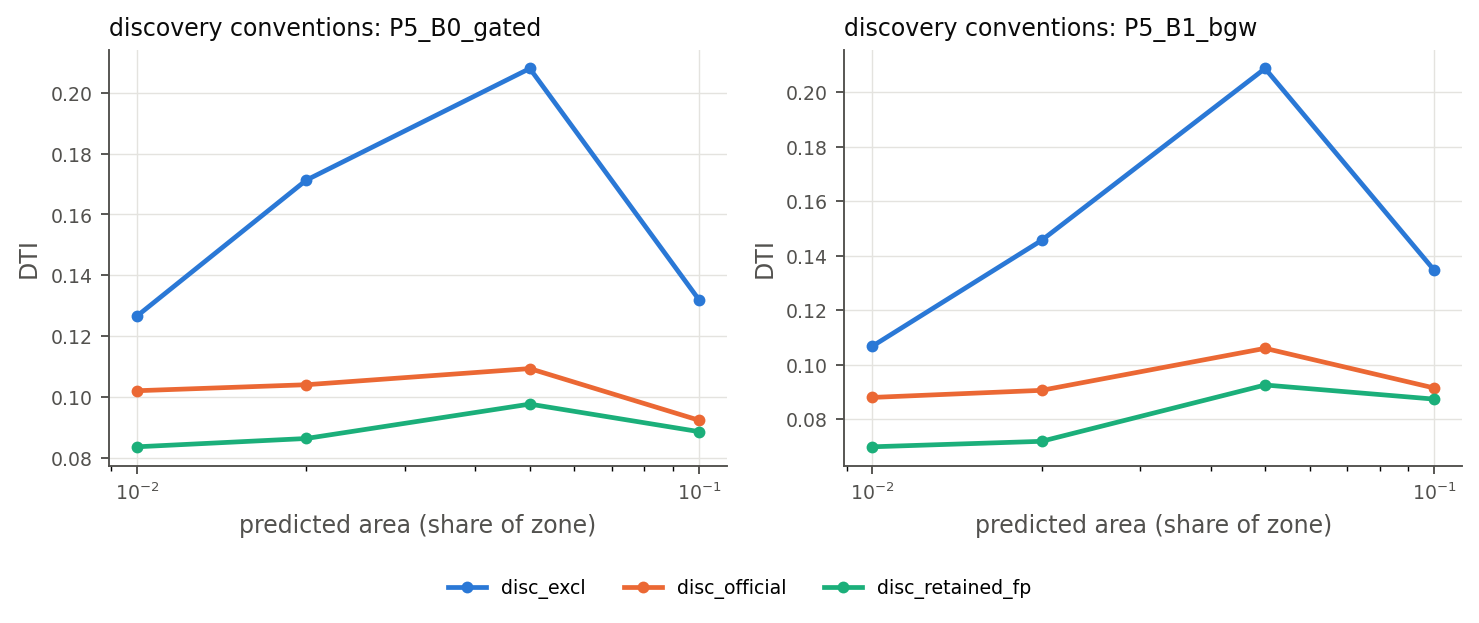

In [29]:
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['verify_official_metric']:
    aud = g3.verify_official_metric()
    display(aud['contract'][['item', 'official', 'status']])
    display(aud['masking'].pivot_table(index='case', columns='convention', values='dti'))
    c = aud['comparison']
    if len(c):
        display(c[c.unit == 'pooled_splits'].pivot_table(index=['model', 'target_frac'], columns='task', values='dti'))
    show3(['official_vs_internal_conventions'], sub='audit')

### G2. Metric optimisation without retraining (A0–A10)

Stage 0: raw sigmoid maps and absolute thresholds. Stage 1: per-zone rank fusion *w R(B0) + (1 − w) R(B1)* × binary top-*a* area. Stage 2: representations (1-px crest lines, skeleton widths, isotropic / across- / along-strike dilation, confidence-dependent width, soft halo, soft top). Stage 3 (`disc_official`): a suppression ring around known faults. For held-out zone *z*, every choice is made on the other zones, among candidates derived from *z*'s own dev choice. **Decision:** the output representation is a bottleneck only if the selected representation beats the better member's binary map consistently (`paired_fold_deltas`, worst zone included) without inflating area.

[gems3] stage 1 geo:0: done
[gems3] stage 1 geo:1: done
[gems3] stage 1 geo:2: done
[gems3] stage 1 disc_official:0: done
[gems3] stage 1 disc_official:1: done
[gems3] stage 1 disc_official:2: done
[gems3] stage 1 disc_excl:0: done
[gems3] stage 1 disc_excl:1: done
[gems3] stage 1 disc_excl:2: done
[gems3] representations geo:0: 10 (w, frac) x 11 reps
[gems3] representations geo:1: 10 (w, frac) x 11 reps
[gems3] representations geo:2: 10 (w, frac) x 11 reps
[gems3] representations disc_official:0: 15 (w, frac) x 11 reps
[gems3] representations disc_official:1: 15 (w, frac) x 11 reps
[gems3] representations disc_official:2: 15 (w, frac) x 11 reps
[gems3] representations disc_official:0: 1 (w, frac) x 1 reps
[gems3] representations disc_official:1: 1 (w, frac) x 1 reps
[gems3] representations disc_official:2: 1 (w, frac) x 1 reps
[gems3] representations disc_official:0: 1 (w, frac) x 1 reps
[gems3] representations disc_official:1: 1 (w, frac) x 1 reps
[gems3] representations disc_officia

,task,method,dti_crossfit,dti_insample,params
0,disc_excl,P5_B0_gated absolute threshold,0.227002,0.227002,"{""threshold"": 0.05}"
1,disc_excl,"P5_B0_gated raw sigmoid (soft, no selection)",0.210623,NaN,-
2,disc_excl,P5_B1_bgw binary top-a,0.208598,0.208598,frac=0.05
3,disc_excl,rank fusion w=0.75 binary top-a,0.205363,0.210071,frac=0.05
4,disc_excl,P5_B1_bgw absolute threshold,0.204737,0.204737,"{""threshold"": 0.05}"
5,disc_excl,P5_B0_gated binary top-a,0.203035,0.211323,frac=0.03
6,disc_excl,rank fusion w=0.5 binary top-a,0.202933,0.208731,frac=0.05
7,disc_excl,rank fusion w=0.25 binary top-a,0.201571,0.207064,frac=0.05
8,disc_excl,"P5_B1_bgw raw sigmoid (soft, no selection)",0.188507,NaN,-
9,disc_official,"selected representation (rep, w, frac[, ring])",0.192213,0.197479,"{""rep"": ""skeleton_1px"", ""w"": 0.75, ""frac"": 0.0..."


,task,rep,family,dti_crossfit,optimism,fold_min,area_frac_mean
0,disc_official,across_strike_1px,dilation,0.111011,1.387779e-17,0.077292,0.126597
1,disc_official,along_strike_3px,dilation,0.100469,0.000000e+00,0.073481,0.182469
2,disc_official,binary,area,0.122570,1.061195e-03,0.091845,0.045500
3,disc_official,confidence_width,width,0.128434,0.000000e+00,0.085371,0.098022
4,disc_official,crest_1px,width,0.153301,4.782751e-03,0.101528,0.045500
5,disc_official,crest_3px,dilation,0.100927,0.000000e+00,0.071600,0.165058
6,disc_official,dilate_1px,dilation,0.091570,3.812591e-03,0.061380,0.097665
7,disc_official,halo_soft,soft,0.095326,-1.387779e-17,0.066284,0.165058
8,disc_official,skeleton_1px,width,0.159299,3.167935e-03,0.097023,0.021661
9,disc_official,skeleton_3px,width,0.123669,7.098410e-03,0.086298,0.074632


,task,w,dti_crossfit,fold_min,frac_all_zones
0,geo,0.00,0.167877,0.163087,0.075
1,geo,0.25,0.178716,0.169000,0.050
2,geo,0.50,0.178309,0.166573,0.050
3,geo,0.75,0.174187,0.165346,0.050
4,geo,1.00,0.164560,0.153408,0.050
5,disc_official,0.00,0.104887,0.072689,0.050
6,disc_official,0.25,0.120038,0.097099,0.050
7,disc_official,0.50,0.121443,0.097148,0.050
8,disc_official,0.75,0.122166,0.096127,0.050
9,disc_official,1.00,0.110386,0.067486,0.030


zone                                            0         1         2
task          method                                                 
disc_excl     P5_B0_gated_abs_threshold  0.263062  0.260785  0.148702
              P5_B0_gated_binary         0.232977  0.223356  0.129263
              P5_B0_gated_raw            0.242928  0.243785  0.137851
              P5_B1_bgw_abs_threshold    0.218328  0.240236  0.151530
              P5_B1_bgw_binary           0.227657  0.214825  0.179109
              P5_B1_bgw_raw              0.198178  0.223459  0.140388
              stage1_fusion_area         0.232977  0.214825  0.129263
disc_official P5_B0_gated_abs_threshold  0.129192  0.132873  0.065852
              P5_B0_gated_binary         0.123223  0.133675  0.067486
              P5_B0_gated_raw            0.122258  0.127436  0.062775
              P5_B1_bgw_abs_threshold    0.102538  0.122533  0.067233
              P5_B1_bgw_binary           0.113170  0.118269  0.072689
              P5_B1_bgw_raw              0.095572  0.116785  0.064188
              stage1_fusion_area         0.134487  0.134894  0.096127
              stage2_representation      0.183754  0.170194  0.097023
              stage3_known_ring          0.220813  0.202291  0.121403
geo           P5_B0_gated_abs_threshold  0.147228  0.115689  0.113799
              P5_B0_gated_binary         0.153408  0.156302  0.179918
              P5_B0_gated_raw            0.137510  0.104690  0.103642
              P5_B1_bgw_abs_threshold    0.149695  0.107799  0.136702
              P5_B1_bgw_binary           0.173332  0.163087  0.166036
              P5_B1_bgw_raw              0.142860  0.098272  0.115495
              stage1_fusion_area         0.185647  0.166573  0.179699
              stage2_representation      0.197203  0.169640  0.180145

selected (primary task, all zones): {'rep': 'skeleton_1px', 'w': 0.75, 'frac': 0.05, 'ring': 3}


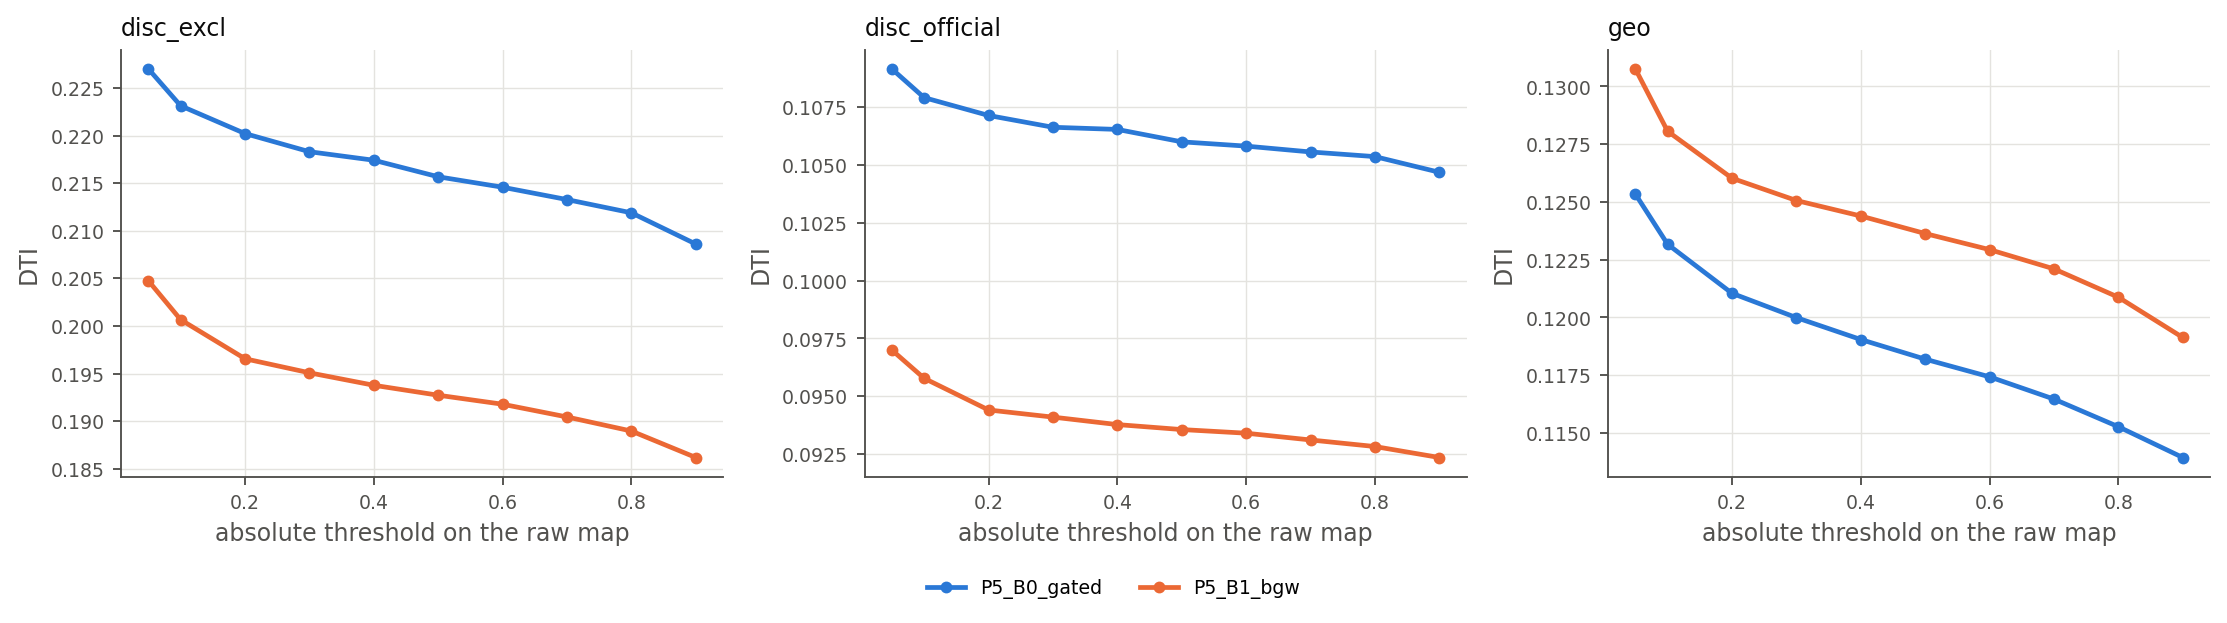

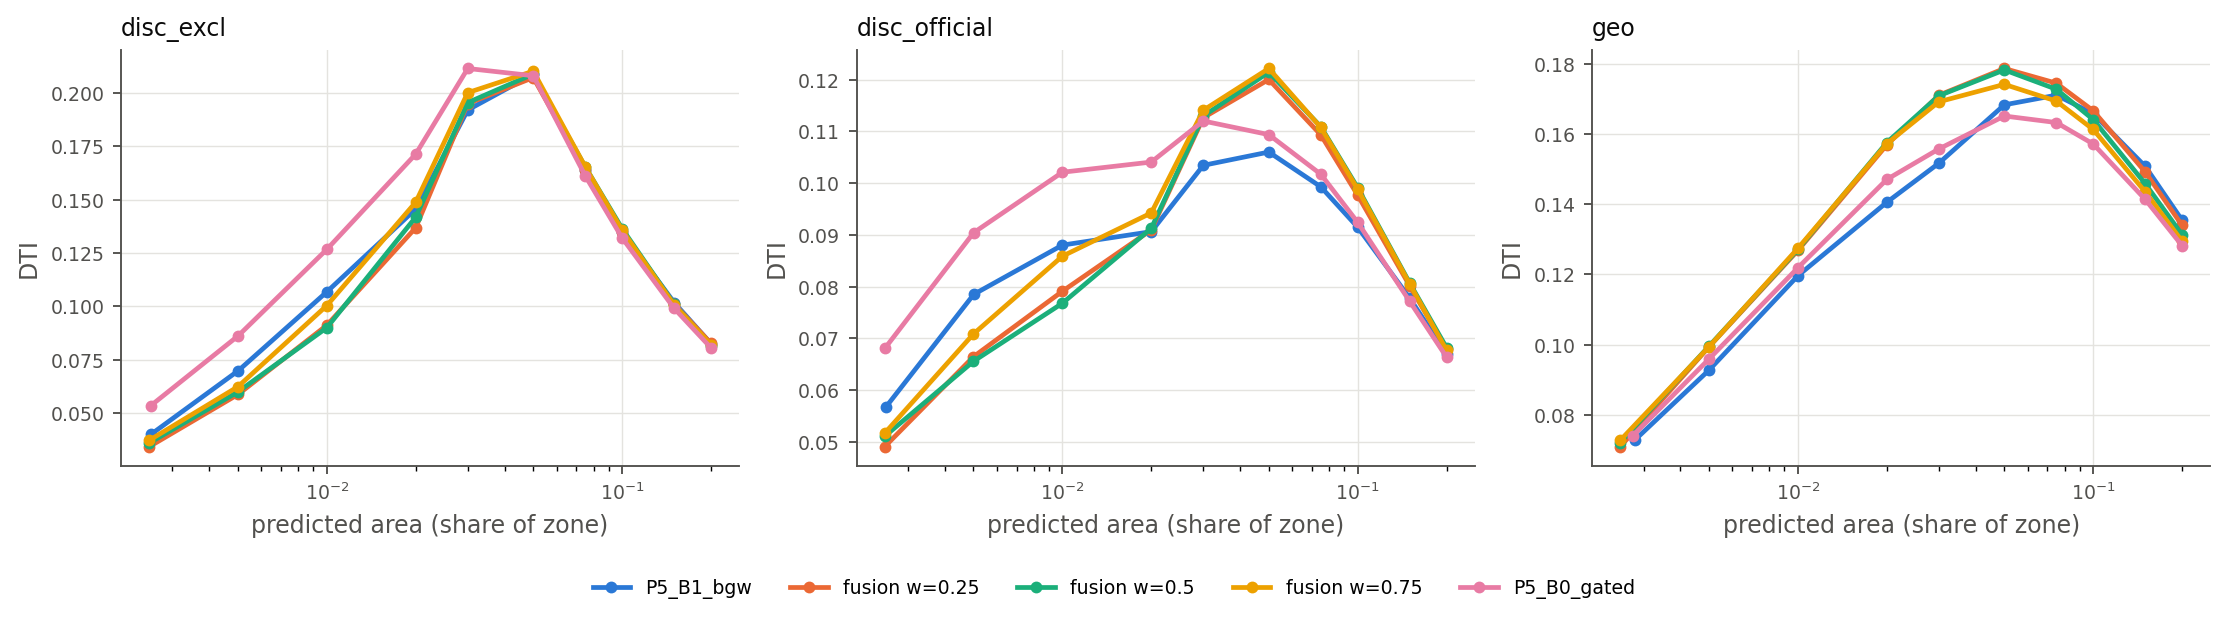

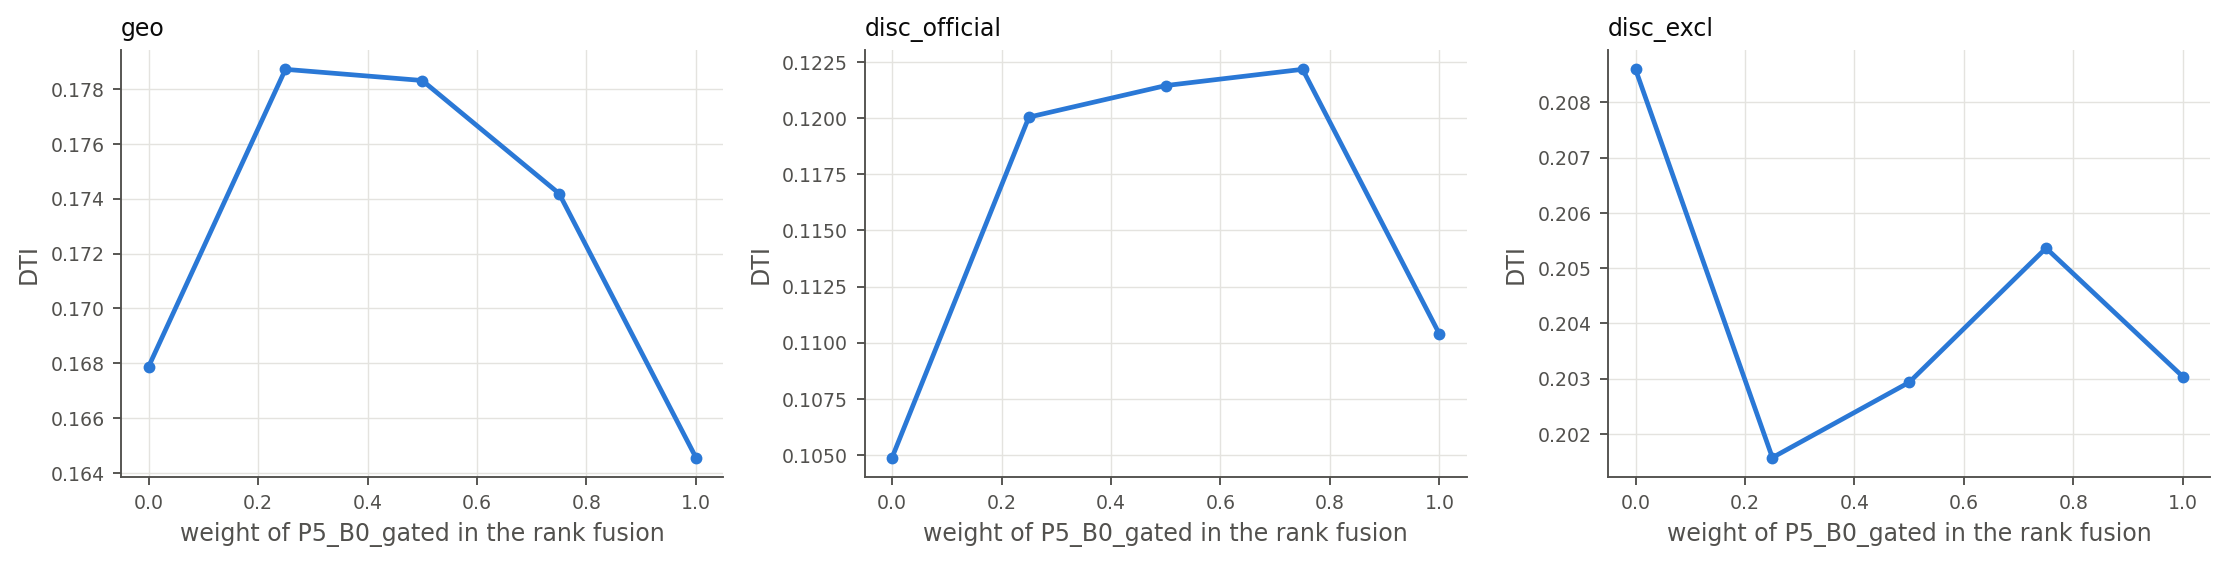

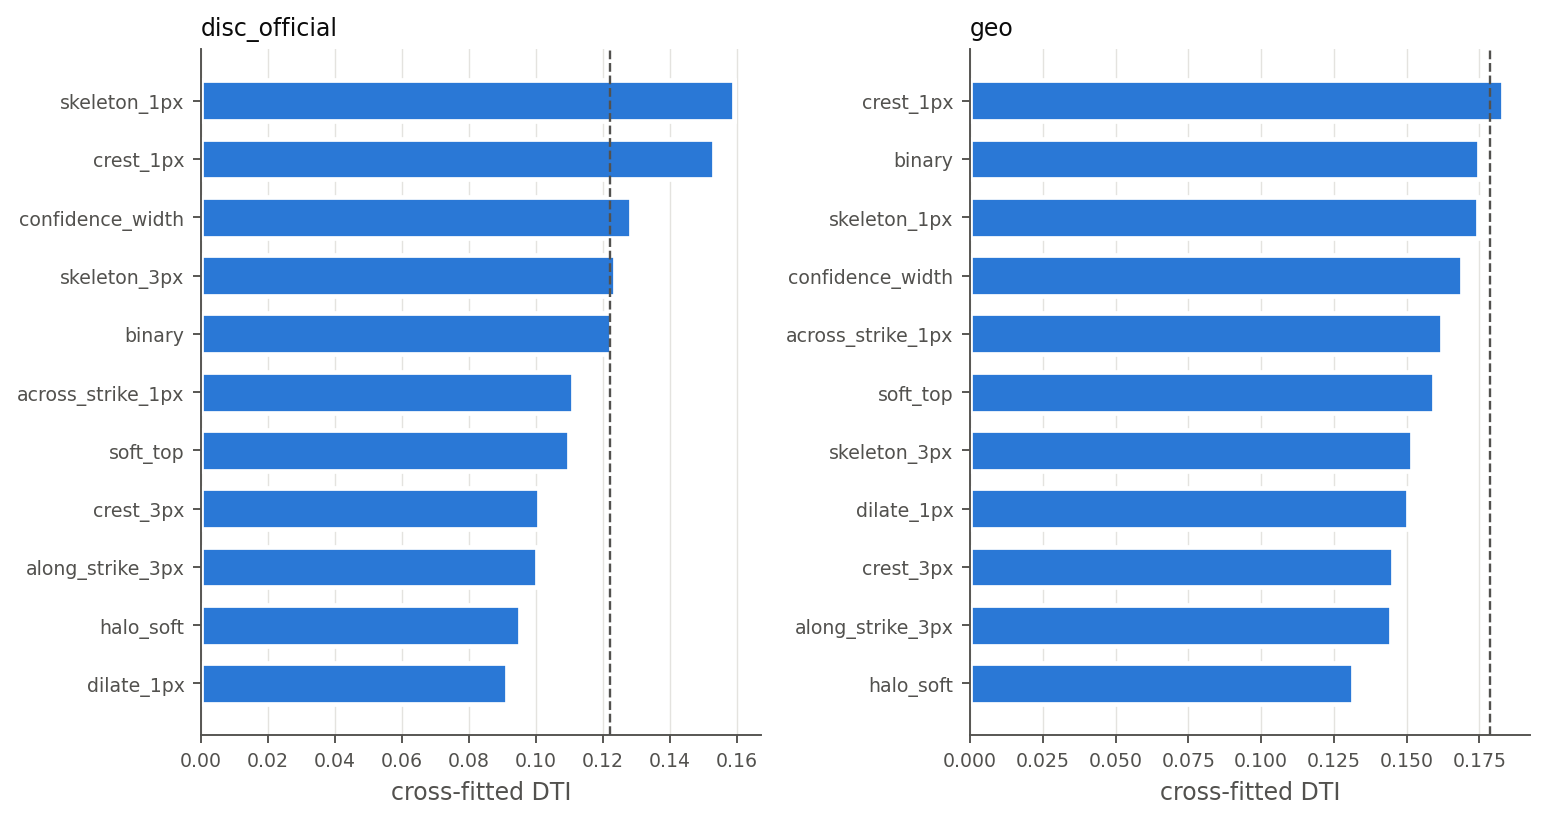

In [30]:
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['run_metric_optimization']:
    sel = g3.metric_optimization()
    display(g3.summary())                            # cross-fitted DTI of every method per task
    display(g3.ws.load_table('representation_ablation', 'metric_optimization')[
        ['task', 'rep', 'family', 'dti_crossfit', 'optimism', 'fold_min', 'area_frac_mean']])
    display(g3.ws.load_table('ensemble_ablation', 'metric_optimization')[['task', 'w', 'dti_crossfit', 'fold_min', 'frac_all_zones']])
    pf = g3.ws.load_table('paired_fold_deltas', 'ensembles')
    if len(pf):
        display(pf.pivot_table(index=['task', 'method'], columns='zone', values='dti_heldout'))
    print('selected (primary task, all zones):', (sel or {}).get('choice', {}).get(g3.cfg['primary_task'], {}).get('params_all'))
    show3(['threshold_sweep', 'area_budget_curves', 'ensemble_weight_curve', 'representation_ablation'],
          sub='metric_optimization/figures')

### G3. Full-region submission candidate

Fold-average inference of each member's CV checkpoints over the whole footprint (cached raw maps in `predictions/`). Then the development rule: per-member rank, fusion weight, representation, area fraction (`submission.area_frac_source`, default: the geo all-zone fraction), known-fault ring. The output is validated against `example_submission.tif` (single float32 band, EPSG:32611, 100 m, same grid, values in [0, 1], 0 where the template is finite, NaN only where it is NaN). The raw maps are never overwritten. **Nothing is uploaded.** Record each manual upload in `reports/leaderboard_log.csv`. Without a GPU, set `'submission': {'source': 'oof_stitched'}`.

In [31]:
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['prepare_submission_candidate']:
    sub = g3.submission()
    display(sub)
    for f in sorted((g3.ws.root / 'submissions').glob('*.tif')):
        print('ready (not uploaded):', f)

[sync in] 3 copied (102.1 MiB), 0 unchanged, 4s: ['experiments/b0_reference__d54e938a/checkpoints/cv_fold0_model.pt', 'experiments/b0_reference__d54e938a/checkpoints/cv_fold1_model.pt', 'experiments/b0_reference__d54e938a/checkpoints/cv_fold2_model.pt']
[sync in] 3 copied (102.1 MiB), 0 unchanged, 11s: ['experiments/b1_bg_weight__7755635b/checkpoints/cv_fold0_model.pt', 'experiments/b1_bg_weight__7755635b/checkpoints/cv_fold1_model.pt', 'experiments/b1_bg_weight__7755635b/checkpoints/cv_fold2_model.pt']
[gems3] submission FAILED: AssertionError: submission /content/gems_work/reports/gems3/submissions/gems3_skeleton_1px_w0.75_f0.05_r3.tif fails: ['finite values where the template is NaN']


None

ready (not uploaded): /content/gems_work/reports/gems3/submissions/gems3_skeleton_1px_w0.75_f0.05_r3.tif


### G4. Geological candidates and oracle headroom

Candidates: label-free crest lines of cached magnetic / gravity / conductivity / terrain layers (computed once), crest lines of the honest B0 / B1 maps, and straight extensions of known-fault tips. Duplicates are fused, keeping their provenance. The **oracle** reads the truth: it says what a perfect ranker could reach *with these candidates*, which bounds any ranker. `oracle_decision` applies the go / no-go rule: if candidate recall is poor, fix generation before ranking.

[gems3] candidates mag_thdr1: 997
[gems3] candidates mag_thdr2: 455
[gems3] candidates mag_tilt2: 985
[gems3] candidates grav_thdr2: 214
[gems3] candidates cond_thdr5: 109
[gems3] candidates terr_ridge1: 1785
[gems3] candidates terr_curv05: 2454
[gems3] candidates geo:0: 2370
[gems3] candidates geo:1: 2513
[gems3] candidates geo:2: 2400
[gems3] candidates disc_official:0: 4156
[gems3] candidates disc_official:1: 4126
[gems3] candidates disc_official:2: 4121
[gems3] candidates full:0: 12236
[gems3] candidates: computed in 150s
[sync out] 34 copied (74.9 MiB), 69 unchanged, 1s: ['reports/gems3']


,source,feature,status,n
0,mag_thdr1,magnetic:thdr@1km,ok,997
1,mag_thdr2,magnetic:thdr@2km,ok,455
2,mag_tilt2,magnetic:tilt@2km,ok,985
3,grav_thdr2,gravity:thdr@2km,ok,214
4,cond_thdr5,conductivity:thdr@5km,ok,109
5,terr_ridge1,terrain:ridge@1km,ok,1785
6,terr_curv05,terrain:curvature@0.5km,ok,2454


[gems3] oracle geo:0: done
[gems3] oracle geo:1: done
[gems3] oracle geo:2: done
[gems3] oracle disc_official:0: done
[gems3] oracle disc_official:1: done
[gems3] oracle disc_official:2: done
[gems3] oracle: computed in 136s
[sync out] 18 copied (1.4 MiB), 102 unchanged, 0s: ['reports/gems3']


,task,zone,n_candidates,recall_w,recall@300m,system_recall,short_system_recall,dti,candidate_km_per_100km2
0,geo,0.0,2370.0,0.181916,0.310312,0.088608,0.046512,0.135461,30.621508
1,geo,1.0,2513.0,0.164137,0.289213,0.074689,0.145833,0.126791,40.367373
2,geo,2.0,2400.0,0.177125,0.306854,0.087558,0.036364,0.134125,34.750331
3,disc_official,0.0,4156.0,0.259851,0.433303,0.184211,NaN,0.073361,71.307203
4,disc_official,1.0,4126.0,0.259427,0.424421,0.157895,NaN,0.075054,65.031648
5,disc_official,2.0,4121.0,0.185201,0.314199,0.045455,NaN,0.051496,72.350497


,task,oracle_dti,oracle_kd_threshold,system_recall_all_candidates,best_crossfit_representation_dti,oracle_gain,decision,rule,note
0,disc_official,0.237202,0.1,0.125000,0.192213,0.044989,STOP,system_recall >= 0.5 and oracle gain >= 0.05,"oracle reads the unit's truth: an upper bound,..."
1,geo,0.178818,0.1,0.082792,0.183266,-0.004449,STOP,system_recall >= 0.5 and oracle gain >= 0.05,"oracle reads the unit's truth: an upper bound,..."


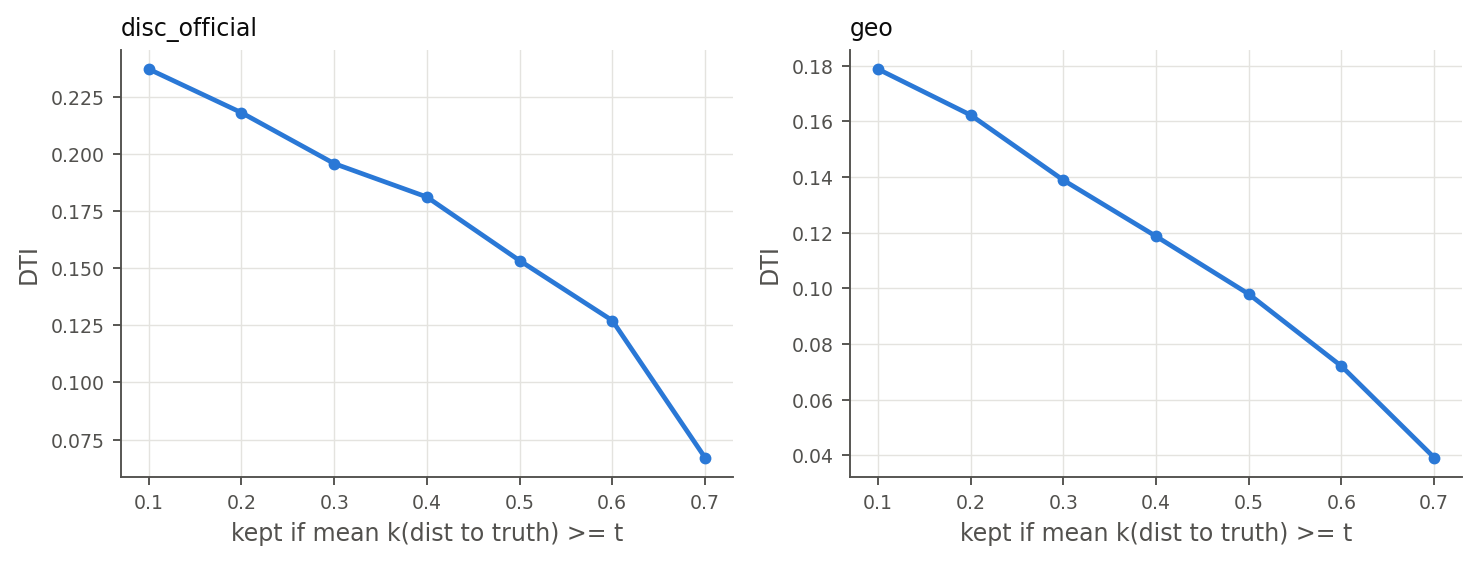

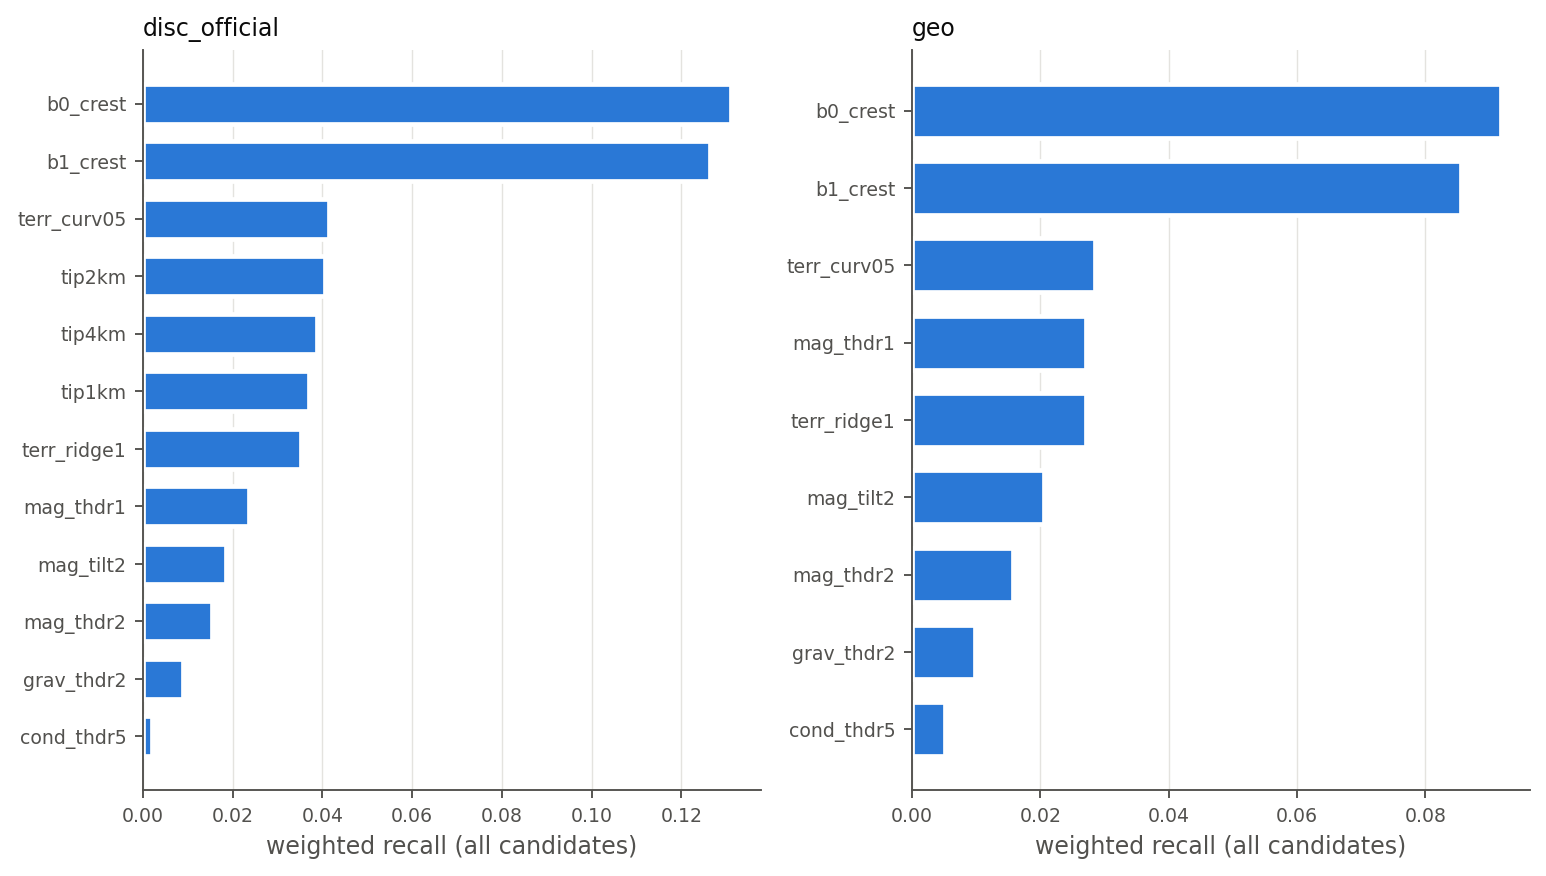

In [32]:
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['run_candidate_generation']:
    g3.candidates()
    display(g3.ws.load_table('label_free_sources', 'proposals'))
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['run_candidate_oracle']:
    g3.oracle()
    orc = g3.ws.load_table('oracle_recall', 'proposals')
    display(orc[orc.subset == 'all_unranked'][['task', 'zone', 'n_candidates', 'recall_w', 'recall@300m', 'system_recall',
                                              'short_system_recall', 'dti', 'candidate_km_per_100km2']])
    display(g3.ws.load_table('oracle_decision', 'proposals'))
    show3(['oracle_dti_curve', 'oracle_recall_by_source'], sub='proposals')

### G5. Gated follow-ups: candidate ranker, DEM gate, map completion

Run each one only when its switch is on and its gate allows it. The ranker refuses to run unless the oracle decision for the primary task is `CONTINUE` (override: `'ranker': {'force': True}`). Its training rows for a held-out unit exclude everything inside that unit's evaluation zone (+ 2 km). The DEM gate uses only cached DEM aggregates and never downloads. Map completion scores a deterministic endpoint-extension completer on synthetic damaged maps, per corruption class.

In [33]:
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['run_candidate_ranker']:
    g3.ranker()
    display(g3.ws.load_table('ranker_vs_pixel_models', 'ranker'))
    display(g3.ws.load_table('training_audit', 'ranker'))
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['run_dem_gate']:
    g3.dem_gate()
    display(g3.ws.load_table('decision', 'dem'))
    display(g3.ws.load_table('pilot_results', 'dem'))
if GEMS3_CONFIG['enabled'] and GEMS3_CONFIG['run_map_completion']:
    g3.map_completion()
    display(g3.ws.load_table('selection', 'map_completion'))

### G6. Research summary and recommended next experiment

The report is rebuilt from the saved tables only, so it can be regenerated in any later session without recomputation. `GEMS3_RESEARCH_REPORT.md` ends with the rule-based recommendation.

In [34]:
import pandas as pd

if GEMS3_CONFIG['enabled']:
    report3 = g3.report()
    display(g3.summary())
    display(pd.DataFrame(g3.log)) if g3.log else None
    print('report:', report3)
    display(Markdown(report3.read_text(encoding='utf-8')[:8000]))

[sync out] 1 copied (0.0 MiB), 120 unchanged, 0s: ['reports/gems3']


,task,method,dti_crossfit,dti_insample,params
0,disc_excl,P5_B0_gated absolute threshold,0.227002,0.227002,"{""threshold"": 0.05}"
1,disc_excl,"P5_B0_gated raw sigmoid (soft, no selection)",0.210623,NaN,-
2,disc_excl,P5_B1_bgw binary top-a,0.208598,0.208598,frac=0.05
3,disc_excl,rank fusion w=0.75 binary top-a,0.205363,0.210071,frac=0.05
4,disc_excl,P5_B1_bgw absolute threshold,0.204737,0.204737,"{""threshold"": 0.05}"
5,disc_excl,P5_B0_gated binary top-a,0.203035,0.211323,frac=0.03
6,disc_excl,rank fusion w=0.5 binary top-a,0.202933,0.208731,frac=0.05
7,disc_excl,rank fusion w=0.25 binary top-a,0.201571,0.207064,frac=0.05
8,disc_excl,"P5_B1_bgw raw sigmoid (soft, no selection)",0.188507,NaN,-
9,disc_official,"selected representation (rep, w, frac[, ring])",0.192213,0.197479,"{""rep"": ""skeleton_1px"", ""w"": 0.75, ""frac"": 0.0..."


,stage,outcome,seconds,error,traceback
0,official_metric,COMPUTED,25.8,NaN,NaN
1,metric_optimization,COMPUTED,1000.6,NaN,NaN
2,submission,FAILED,161.6,AssertionError: submission /content/gems_work/...,"Traceback (most recent call last):\n File ""/c..."
3,candidates,COMPUTED,150.2,NaN,NaN
4,oracle,COMPUTED,135.6,NaN,NaN


report: /content/gems_work/reports/gems3/GEMS3_RESEARCH_REPORT.md


# GEMS 3.0 research report

Members: P5_B0_gated, P5_B1_bgw (FULL experiments, reused; no CNN retraining). Primary task: `disc_official`. Generated from saved tables only.

Reading rules: geographic DTI = rediscovery of mapped faults in held-out folds; `disc_official` = withheld systems under the official known-fault mask (proxy); oracle = reads the truth (upper bound). No number here is a leaderboard score.

## 1. Stages

| stage | outcome | seconds | error |
|---|---|---|---|
| official_metric | COMPUTED | 25.8 |  |
| metric_optimization | COMPUTED | 1000.6 |  |
| submission | FAILED | 161.6 | AssertionError: submission /content/gems_work/reports/gems3/submissions/gems3_skeleton_1px_w0.75_f0.05_r3.tif fails: ['finite values where the template is NaN'] |
| candidates | COMPUTED | 150.2 |  |
| oracle | COMPUTED | 135.6 |  |

## 2. Official metric

Contract (docs/GEMS_OFFICIAL_METRIC_AUDIT.md):

| item | status | source |
|---|---|---|
| kernel | VERIFIED (problem description) | page/967 |
| alpha_beta | VERIFIED (problem description) | page/967 |
| tp_fp_fn | VERIFIED (problem description) | page/967 |
| eps | UNSPECIFIED | page/967 |
| truth | VERIFIED (organizer) | t/11516 |
| known_mask_geometry | VERIFIED (organizer) - MISMATCH fixed by disc_official | t/11516 |
| known_mask_fp | VERIFIED (organizer) | t/11516 |
| near_known_fp | VERIFIED (organizer) - MISMATCH fixed | t/11516 |
| masked_pred_supports_tp | INFERRED from organizer wording; no public scorer - both conventions reported | t/11516 |
| new_truth_near_known | VERIFIED (organizer) - proxy limitation | t/11516 |
| aggregation | VERIFIED (organizer) | t/11550 |
| weighting | VERIFIED (organizer) | t/11556 |
| format | VERIFIED (problem description) | page/967 |
| nan_inside_bounds | UNVERIFIED | - |
| clip | UNVERIFIED | - |
| public_private_split | UNKNOWN | t/11550 |
| reference_scorer | VERIFIED absent (github.com/drivendataorg/gems-prize-reference-solution) | reference solution |

Masking conventions on synthetic cases:

| case | convention | dti | tp_w | fp_w |
|---|---|---|---|---|
| predict_known_only | official_pixel_exact_no_support | 0.0 | 0.0 | 0.0 |
| predict_known_only | pixel_exact_with_support | 0.7143 | 20.0 | 0.0 |
| predict_known_only | excl_dilated_300m_with_support | 0.7143 | 20.0 | 0.0 |
| predict_known_only | known_is_fp | 0.6667 | 20.0 | 10.0 |
| predict_new_exactly | official_pixel_exact_no_support | 1.0 | 30.0 | 0.0 |
| predict_new_exactly | pixel_exact_with_support | 1.0 | 30.0 | 0.0 |
| predict_new_exactly | excl_dilated_300m_with_support | 1.0 | 30.0 | 0.0 |
| predict_new_exactly | known_is_fp | 1.0 | 30.0 | 0.0 |
| ring_far_from_new | official_pixel_exact_no_support | 0.8333 | 30.0 | 30.0 |
| ring_far_from_new | pixel_exact_with_support | 0.8333 | 30.0 | 30.0 |
| ring_far_from_new | excl_dilated_300m_with_support | 1.0 | 30.0 | 0.0 |
| ring_far_from_new | known_is_fp | 0.8333 | 30.0 | 30.0 |
| known_fill_plus_new | official_pixel_exact_no_support | 1.0 | 30.0 | 0.0 |
| known_fill_plus_new | pixel_exact_with_support | 1.0 | 30.0 | 0.0 |
| known_fill_plus_new | excl_dilated_300m_with_support | 1.0 | 30.0 | 0.0 |
| known_fill_plus_new | known_is_fp | 0.8333 | 30.0 | 30.0 |

B0 / B1 discovery DTI under each convention (pooled splits):

| task | model | target_frac | dti | recall_w | fp_w |
|---|---|---|---|---|---|
| disc_excl | P5_B0_gated | 0.01 | 0.1267 | 0.1067 | 2327.9777 |
| disc_excl | P5_B0_gated | 0.02 | 0.1713 | 0.1505 | 5412.6978 |
| disc_excl | P5_B0_gated | 0.05 | 0.2079 | 0.3071 | 68742.4491 |
| disc_excl | P5_B0_gated | 0.1 | 0.132 | 0.4901 | 314274.9483 |
| disc_excl | P5_B1_bgw | 0.01 | 0.1068 | 0.0892 | 1949.8218 |
| disc_excl | P5_B1_bgw | 0.02 | 0.1456 | 0.1255 | 4136.5586 |
| disc_excl | P5_B1_bgw | 0.05 | 0.2086 | 0.2909 | 59910.2425 |
| disc_excl | P5_B1_bgw | 0.1 | 0.1347 | 0.4824 | 299882.5353 |
| disc_official | P5_B0_gated | 0.01 | 0.1021 | 0.1295 | 49432.9247 |
| disc_official | P5_B0_gated | 0.02 | 0.1041 | 0.1802 | 99928.9404 |
| disc_official | P5_B0_gated | 0.05 | 0.1094 | 0.3435 | 253682.642 |
| disc_official | P5_B0_gated | 0.1 | 0.0924 | 0.5106 | 516184.6944 |
| disc_official | P5_B1_bgw | 0.01 | 0.088 | 0.1118 | 49994.2526 |
| disc_official | P5_B1_bgw | 0.02 | 0.0906 | 0.1573 | 100979.1403 |
| disc_official | P5_B1_bgw | 0.05 | 0.106 | 0.3327 | 253608.4598 |
| disc_official | P5_B1_bgw | 0.1 | 0.0915 | 0.5046 | 515351.0978 |
| disc_retained_fp | P5_B0_gated | 0.01 | 0.0837 | 0.1067 | 50631.9777 |
| disc_retained_fp | P5_B0_gated | 0.02 | 0.0864 | 0.1505 | 101721.6978 |
| disc_retained_fp | P5_B0_gated | 0.05 | 0.0977 | 0.3071 | 254764.4491 |
| disc_retained_fp | P5_B0_gated | 0.1 | 0.0887 | 0.4901 | 516901.9483 |
| disc_retained_fp | P5_B1_bgw | 0.01 | 0.0699 | 0.0892 | 51158.8218 |
| disc_retained_fp | P5_B1_bgw | 0.02 | 0.0719 | 0.1255 | 102699.5586 |
| disc_retained_fp | P5_B1_bgw | 0.05 | 0.0926 | 0.2909 | 255083.2425 |
| disc_retained_fp | P5_B1_bgw | 0.1 | 0.0874 | 0.4824 | 516221.5353 |

## 3. Baselines, thresholds, widths, fusion (cross-fitted)

| task | method | dti_crossfit | dti_insample | params |
|---|---|---|---|---|
| disc_excl | P5_B0_gated absolute threshold | 0.227 | 0.227 | {"threshold": 0.05} |
| disc_excl | P5_B0_gated raw sigmoid (soft, no selection) | 0.2106 |  | - |
| disc_excl | P5_B1_bgw binary top-a | 0.2086 | 0.2086 | frac=0.05 |
| disc_excl | rank fusion w=0.75 binary top-a | 0.2054 | 0.2101 | frac=0.05 |
| disc_excl | P5_B1_bgw absolute threshold | 0.2047 | 0.2047 | {"threshold": 0.05} |
| disc_excl | P5_B0_gated binary top-a | 0.203 | 0.2113 | frac=0.03 |
| disc_excl | rank fusion w=0.5 binary top-a | 0.2029 | 0.2087 | frac=0.05 |
| disc_excl | rank fusion w=0.25 binary top-a | 0.2016 | 0.2071 | frac=0.05 |
| disc_excl | P5_B1_bgw raw sigmoid (soft, no selection) | 0.1885 |  | - |
| disc_official | selected representation (rep, w, frac[, ring]) | 0.1922 | 0.1975 | {"rep": "skeleton_1px", "w": 0.75, "frac": 0.05, "ring": 3} |
| disc_official | rank fusion w=0.75 binary top-a | 0.1222 | 0.1222 | frac=0.05 |
| disc_official | rank fusion w=0.5 binary top-a | 0.1214 | 0.1214 | frac=0.05 |
| disc_official | rank fusion w=0.25 binary top-a | 0.12 | 0.12 | frac=0.05 |
| disc_official | P5_B0_gated binary top-a | 0.1104 | 0.112 | frac=0.03 |
| disc_official | P5_B0_gated absolute threshold | 0.1091 | 0.1091 | {"threshold": 0.05} |
| disc_official | P5_B1_bgw binary top-a | 0.1049 | 0.106 | frac=0.05 |
| disc_official | P5_B0_gated raw sigmoid (soft, no selection) | 0.1039 |  | - |
| disc_official | P5_B1_bgw absolute threshold | 0.097 | 0.097 | {"threshold": 0.05} |
| disc_official | P5_B1_bgw raw sigmoid (soft, no selection) | 0.0917 |  | - |
| geo | selected representation (rep, w, frac[, ring]) | 0.1833 | 0.1875 | {"rep": "crest_1px", "w": 0.25, "frac": 0.04} |
| geo | rank fusion w=0.25 binary top-a | 0.1787 | 0.1787 | frac=0.05 |
| geo | rank fusion w=0.5 binary top-a | 0.1783 | 0.1783 | frac=0.05 |
| geo | rank fusion w=0.75 binary top-a | 0.1742 | 0.1742 | frac=0.05 |
| geo | P5_B1_bgw binary top-a | 0.1679 | 0.1711 | frac=0.075 |
| geo | P5_B0_gated binary top-a | 0.1646 | 0.1652 | frac=0.05 |
| geo | P5_B1_bgw absolute threshold | 0.1308 | 0.1308 | {"threshold": 0.05} |
| geo | P5_B0_gated absolute threshold | 0.1253 | 0.1253 | {"threshold": 0.05} |
| geo | P5_B1_bgw raw sigmoid (soft, no selection) | 0.1179 |  | - |
| geo | P5_B0_gated raw sigmoid (soft, no selection) | 0.1149 |  | - |

Paired held-out deltas per zone: `ensembles/paired_fold_deltas.csv`.

## 4. Submission readiness

_not produced_

Files in `submissions/` (validated against the template; never uploaded). Raw member maps and the fused score are in `predictions/`.

## 5. Candidates and oracle headroom

| source | feature | status | n |
|---|---|---|---|
| mag_thdr1 | magnetic:thdr@1km | ok | 997 |
| mag_thdr2 | magnetic:thdr@2km | ok | 455 |
| mag_tilt2 | magnetic:tilt@2km | ok | 985 |
| grav_thdr2 | gravity:thdr@2km | ok | 214 |

## 19–20. Full-area inference and competition GeoTIFF

Uses the registry **champion** (status `promoted`): fold models averaged over the full footprint (chunked, Hann-blended tiles), area-budget export policy, one validated single-band float32 GeoTIFF per known-fault policy in `submissions/` with provenance JSON. **Uploading is manual**; record each upload in `reports/leaderboard_log.csv`.

In [35]:
pipe.step('full_inference')
pipe.step('submission')
import pandas as pd
from gems_bench.evaluation.scoreboard import LEADERBOARD_COLUMNS
log = pipe.pc.local / 'reports' / 'leaderboard_log.csv'
if not log.exists():
    pd.DataFrame(columns=LEADERBOARD_COLUMNS).to_csv(log, index=False)
display(pd.read_csv(log))

[sync in] 6 copied (0.0 MiB), 0 unchanged, 2s: ['submissions', 'model_registry']
[full_inference] not part of mode ADVANCED_RESEARCH: outputs missing - full_inference: missing - z_submission__c46ee057:train: missing - pending; full_region.tif: missing - file not found
[sync in] 0 copied (0.0 MiB), 6 unchanged, 0s: ['submissions', 'model_registry']
[submission] not part of mode ADVANCED_RESEARCH: outputs missing - submission: missing - z_submission__c46ee057:export: missing - pending


,submitted_at,model,submission_file,known_fault_policy,public_score,notes


## 21. Figures and research reporting

`reports/pipeline/` on Drive: `PIPELINE_REPORT.md`, `stage_status.csv`, `dashboard_summary.csv`, `baseline_status.csv`, `experiment_status.csv`, `scoreboard_latest.csv`, `figures/*.png|svg`. Per-experiment tables and figures stay in `experiments/<id>/`.

[sync out] 7 copied (0.2 MiB), 12 unchanged, 0s: ['reports/pipeline']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/reports.json']
[reports] DONE: reports: ok (1 checks)
[reports] outputs: ['/content/drive/MyDrive/GEMS_2/reports/pipeline']


,key,value
0,time,2026-10-26 01:41
1,mode,ADVANCED_RESEARCH
2,device,Tesla T4
3,vram_gb,14.6
4,drive,/content/drive/MyDrive/GEMS_2
5,stages_done,6
6,stages_cached,7
7,stages_pending,3
8,stages_failed,1
9,stages_blocked,0


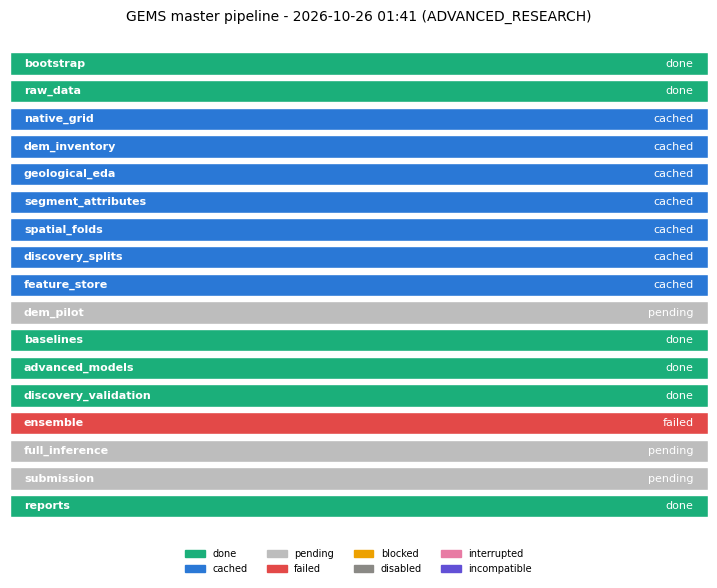

[sync out] 3 copied (0.2 MiB), 16 unchanged, 0s: ['reports/pipeline']


,key,value
0,time,2026-10-26 01:41
1,mode,ADVANCED_RESEARCH
2,device,Tesla T4
3,vram_gb,14.6
4,drive,/content/drive/MyDrive/GEMS_2
5,stages_done,6
6,stages_cached,7
7,stages_pending,3
8,stages_failed,1
9,stages_blocked,0


In [36]:
pipe.step('reports')
pipe.dashboard()

## 22. Final artifact and manifest validation

Re-validates every stage's outputs **on Drive** (what survives the session), lists the stage records and the latest events.

In [37]:
pipe.push_all()
final = pipe.plan(mode='FULL_PIPELINE', root='drive')
display(final[['stage', 'outputs', 'planned', 'last_status', 'last_origin', 'last_finished', 'detail']])
display(pipe.status())
display(pipe.events(30))
for s in ('feature_store', 'baselines', 'discovery_validation', 'submission'):
    print(s, '->', pipe.outputs(s)[:3])

[sync out] 71 copied (1618.9 MiB), 518 unchanged, 78s: ['environment/pipeline', 'reports', 'environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv', 'data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv', 'environment/pipeline/native_grid.json', 'data/raw/dem_1m/inventory', 'data/raw/dem_1m/tnm_urls.json', 'outputs/eda/manifest.json', 'outputs/eda/datasets', 'outputs/eda/features/lineament_maps.tif', 'outputs/eda/features/crossmodal_orientation.tif', 'outputs/eda/REBUILD_PROVENANCE.json', 'outputs/eda/INSTALL_STATE.json', 'outputs/benchmark/datasets/native_segment_ids.tif', 'outputs/benchmark/datasets/segment_attributes.parquet', 'outputs/benchmark/datasets/native_segments_provenance.json', 'outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026', 'outputs/benchmark/folds/discovery_d3_link1km_s2026', 'outputs/benchmark/cache/features/raw_mag_anom.npy', 'outputs/benchmark/cache/features/raw_rtp.npy', 'outputs/benchmark/cache/features/

,stage,outputs,planned,last_status,last_origin,last_finished,detail
0,bootstrap,ok,SKIP_CACHED,done,built,2026-10-26T00:17:49,bootstrap: ok (3 checks)
1,raw_data,ok,SKIP_CACHED,done,built,2026-10-26T00:19:36,raw_data: ok (3 checks)
2,native_grid,ok,SKIP_CACHED,done,built,2026-10-22T13:40:01,native_grid: ok (1 checks)
3,dem_inventory,ok,SKIP_CACHED,done,built,2026-10-22T20:46:34,dem_inventory: ok (2 checks)
4,geological_eda,ok,SKIP_CACHED,done,built,2026-10-22T20:50:36,eda_minimal: ok (7 checks)
5,segment_attributes,ok,SKIP_CACHED,done,built,2026-10-22T20:50:38,native_segments: ok (2 checks)
6,spatial_folds,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:02,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
7,discovery_splits,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:03,discovery:discovery_d3_link1km_s2026: ok (3 ch...
8,feature_store,ok,SKIP_CACHED,done,built,2026-10-22T21:18:58,feature_store: ok (139 checks)
9,dem_pilot,missing,DISABLED (DEM pilot disabled (stages.run_dem_p...,,,,dem_pilot: missing - f1_dem_pilot__888c6e12:pr...


,stage,state,title,resource,origin,last_finished,attempts,reason,recovery,outputs
0,bootstrap,done,"Environment, Drive, workspace folders",light,built,2026-10-26T00:17:49,7,bootstrap: ok (3 checks),,"environment/pipeline/config_snapshot.json, rep..."
1,raw_data,done,"Competition files: locate, validate, download ...",network,built,2026-10-26T00:19:36,6,raw_data: ok (3 checks),,"data/raw/acquisition_manifest.json, reports/pi..."
2,native_grid,cached,"Native 100 m grid, labels, template checks",cpu,built,2026-10-22T13:40:01,1,native_grid: ok (1 checks),,"environment/pipeline/native_grid.json, reports..."
3,dem_inventory,cached,USGS 1 m DEM inventory (metadata only),light,built,2026-10-22T20:46:34,1,dem_inventory: ok (2 checks),,"data/raw/dem_1m/inventory, data/raw/dem_1m/tnm..."
4,geological_eda,cached,Phase-1 EDA dependency repair (minimal rebuild),cpu-heavy,built,2026-10-22T20:50:36,2,eda_minimal: ok (7 checks),,"outputs/eda/manifest.json, outputs/eda/datasets"
5,segment_attributes,cached,Native-grid segment ids + attributes,cpu,built,2026-10-22T20:50:38,1,native_segments: ok (2 checks),,outputs/benchmark/datasets/native_segment_ids....
6,spatial_folds,cached,Geographic folds (Phase-2 protocol),cpu,adopted_existing,2026-10-22T13:40:02,1,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks),,outputs/benchmark/folds/geo_k3_b20km_buf13km_s...
7,discovery_splits,cached,Pseudo-discovery fault-system splits,cpu,adopted_existing,2026-10-22T13:40:03,1,discovery:discovery_d3_link1km_s2026: ok (3 ch...,,outputs/benchmark/folds/discovery_d3_link1km_s...
8,feature_store,cached,"Feature store: compute once, reuse",cpu-heavy,built,2026-10-22T21:18:58,1,feature_store: ok (139 checks),,outputs/benchmark/cache/features/raw_mag_anom....
9,dem_pilot,pending,"1 m DEM pilot: selection, download, morphology...",network-heavy,,,0,,,"experiments/f1_dem_pilot__888c6e12, data/proce..."


,time,stage,event,decision,validation,seconds,reason,location
0,2026-10-25T13:09:58,advanced_models,start,RUN,partial,NaN,NaN,NaN
1,2026-10-25T14:26:01,advanced_models,done,NaN,NaN,4736.3,NaN,NaN
2,2026-10-25T14:26:07,discovery_validation,start,BUILD,missing,NaN,NaN,NaN
3,2026-10-25T14:27:57,discovery_validation,done,NaN,NaN,109.1,NaN,NaN
4,2026-10-25T14:27:59,reports,start,RUN,missing,NaN,NaN,NaN
5,2026-10-25T14:28:02,reports,done,NaN,NaN,2.6,NaN,NaN
6,2026-10-25T22:51:36,bootstrap,start,RUN,ok,NaN,NaN,NaN
7,2026-10-25T22:51:42,bootstrap,done,NaN,NaN,8.1,NaN,NaN
8,2026-10-25T22:53:39,raw_data,start,BUILD,missing,NaN,NaN,NaN
9,2026-10-25T22:53:49,raw_data,done,NaN,NaN,10.6,NaN,NaN


feature_store -> ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_mag_anom.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_rtp.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_tmi_hg.npy']
baselines -> ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/b0_lineament_fused_s2026', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/lgbm_G1_s2026', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/disc0_lgbm_G1_s2026']
discovery_validation -> ['/content/drive/MyDrive/GEMS_2/experiments/pipeline_scoreboard__a50ac697', '/content/drive/MyDrive/GEMS_2/reports/pipeline/scoreboard_latest.csv']
submission -> ['/content/drive/MyDrive/GEMS_2/experiments/z_submission__c46ee057', '/content/drive/MyDrive/GEMS_2/submissions', '/content/drive/MyDrive/GEMS_2/model_registry']


## 23. Resume, inspect a failure, update the code

After a disconnect or in a new session: **run sections 1–4 again, then the same cells (or `pipe.run()`)**.

* Finished stages are `SKIP_CACHED` (validated on Drive, staged back to `/content/gems_work` only when needed). Raw files and folds are never downloaded or regenerated again.
* **A stage failed?** `pipe.explain('<stage>')` prints the error, `file:line`, the recovery action and the traceback, also for a failure recorded in an earlier session. `pipe.failure_report()` lists each root failure and the stages it blocks.
* **After a fix is pushed to GitHub:** *Runtime → Restart session*, then run from section 1. The installation cell fast-forwards `ref` (or checks out the pinned SHA) and prints the commit. Completed stages are skipped; the failed stage resumes.
* Interrupted feature builds continue with the missing features. Interrupted experiments continue at the next CV fold / discovery split and resume training from the last checkpoint pushed to Drive (`ckpt_sync_min`).
* To change a protocol (folds, features, experiment settings), edit the configuration. A new versioned folder / experiment id is created, and earlier results are kept.
* On short sessions set `max_stage_minutes` (e.g. 200): training stops cleanly at an epoch boundary and resumes next time.

The original notebooks `00`–`07` remain as focused research entry points; this notebook is the recommended start.